# 0 TRATAMENTO INICIAL

## 0.1 Carregar base e converter tipos

In [2]:
import pandas as pd
import numpy as np

PATH = r"C:\Users\pedro\Desktop\Stone\Missão #1_Base.xlsx"
SHEET = "Base_Stone"   # ajuste se necessário

df = pd.read_excel(PATH, sheet_name=SHEET, header=1)

# Conversões de tipo
df['Data Apuração'] = pd.to_datetime(df['Data Apuração'], errors='coerce')
df['Data de Entrada do Cliente'] = pd.to_datetime(df['Data de Entrada do Cliente'], errors='coerce')

num_cols = [
    'Volume Transacionado','Quantidade de Transações',
    'Net MDR','Aluguel','Pre-pagamento','Total',
    'Pre-pagamento.1','Equipamento/Logística','Comissões',
    'Transacionais','Outros','Total.1','Margem final'
]
for c in num_cols:
    df[c] = pd.to_numeric(df[c], errors='coerce')


## 0.2 Checagens básicas (shape, dtypes, nulos, duplicatas)

In [3]:
print("Shape:", df.shape)
print("\nTipos:\n", df.dtypes)

print("\n% de nulos por coluna:")
print((df.isna().mean()*100).round(2).sort_values(ascending=False))

# Duplicata por chave (cliente x mês)
key = ['Número do Cliente', 'Data Apuração']
dups = df[df.duplicated(key, keep=False)].sort_values(key)
print("\nDuplicatas por [Número do Cliente, Data Apuração]:", dups.shape[0])
# dups.head(10)


Shape: (12456, 19)

Tipos:
 Número do Cliente                      int64
MCC                                    int64
Data Apuração                 datetime64[ns]
Data de Entrada do Cliente    datetime64[ns]
Canal                                 object
Cidade                                object
Volume Transacionado                 float64
Quantidade de Transações             float64
Net MDR                              float64
Aluguel                              float64
Pre-pagamento                        float64
Total                                float64
Pre-pagamento.1                      float64
Equipamento/Logística                float64
Comissões                            float64
Transacionais                        float64
Outros                               float64
Total.1                              float64
Margem final                         float64
dtype: object

% de nulos por coluna:
Número do Cliente             0.0
Pre-pagamento                 0.0
Total.1    

### 0.2.1 Diagnóstico da etapa:


1. Shape da base

* (12456, 19) → 12.456 linhas × 19 colunas.
* Cada linha corresponde a um cliente × mês (ou cliente × data de apuração), e não encontramos duplicatas → ou seja, está consistente para análises mensais.

2. Tipos de dados

* Datas (Data Apuração, Data de Entrada do Cliente) → já estão em datetime64[ns], ótimo para análises temporais e cálculos de churn.
* Numéricos → a maioria está em float64, mesmo colunas que provavelmente são valores monetários (Receita, Custos, Margem). Isso é esperado, pois podem ter valores decimais.
* Inteiros → Número do Cliente e MCC corretamente como int64, pois são IDs/códigos.
* Categóricas → Canal e Cidade como object, o que é apropriado; depois podemos transformar para category se quisermos otimizar memória ou para análises de frequência.
* Conclusão: Tipos corretos → não há necessidade de conversão adicional neste ponto.

3. Valores nulos

* Nenhuma coluna com valores nulos → 0% de NaN em todas as 19 colunas.
* Isso simplifica bastante: não precisamos de imputação de dados faltantes, pelo menos nessa etapa.

4. Duplicatas

* Nenhuma duplicata por [Número do Cliente, Data Apuração].
* Isso confirma que a chave cliente × mês é única → podemos usar essa chave sem risco para análises de churn, lifetime, etc.

5. Avaliação geral

* A base está estruturalmente íntegra:
* Sem nulos
* Sem duplicatas
* Tipos corretos para datas, categorias e numéricos
* Isso nos dá segurança para avançar para as próximas checagens: valores anômalos (custos positivos, receitas negativas, inconsistência de somas) e comportamentos atípicos.




## 0.3 Regras de negócio: atividade e consistências óbvias

In [4]:
df['Ativo no Mês'] = (df['Volume Transacionado'] > 0).astype(int)

receita_cols = ['Net MDR','Aluguel','Pre-pagamento','Total']
custo_cols   = ['Pre-pagamento.1','Equipamento/Logística','Comissões','Transacionais','Outros','Total.1']

# Receitas negativas?
neg_receitas = (df[receita_cols] < 0).any(axis=1)
print("Linhas com RECEITA negativa:", neg_receitas.sum())

# Custos positivos?
pos_custos = (df[custo_cols] > 0).any(axis=1)
print("Linhas com CUSTO positivo:", pos_custos.sum())

# Ativo com receita/custo zero vs. padrão esperado
sem_receita_mas_ativo = df[(df['Ativo no Mês']==1) & (df['Total']<=0)]
print("Ativo no mês com Total de receita <= 0:", sem_receita_mas_ativo.shape[0])

sem_volume_com_receita = df[(df['Volume Transacionado']==0) & (df['Total']>0)]
print("Sem volume mas com receita > 0:", sem_volume_com_receita.shape[0])


Linhas com RECEITA negativa: 159
Linhas com CUSTO positivo: 1
Ativo no mês com Total de receita <= 0: 78
Sem volume mas com receita > 0: 46


### 0.3.1 Diagnóstico Inicial da Base e Próximas Ações

Após as verificações de integridade (Etapa 0.3), identificamos os seguintes pontos:

1. Receitas Negativas  
   - Qtd: 159 linhas  
   - Provável causa: Estornos, chargebacks ou ajustes financeiros.  
   - Ação: Manter valores negativos, tratando-os como transações de reversão para análise posterior.

2. Custos Positivos  
   - Qtd: 1 linha  
   - Problema: Custos deveriam ser valores negativos (saída de caixa).  
   - Ação (Etapa 03.1): Inverter o sinal para manter consistência contábil.

3. Ativos com Receita ≤ 0  
   - Qtd: 78 linhas  
   - Problema: Clientes ativos (Volume > 0) mas sem receita ou com receita negativa.  
   - Ação:  
     - Receita = 0 → Campanhas promocionais (isentos de taxa).  
     - Receita < 0 → Estornos, chargebacks ou campanhas negativas.  
   - Etapa 03.2: Quantificar para revisão futura da área de precificação.

4. Receitas sem Volume Transacionado  
   - Qtd: 46 linhas  
   - Problema: Receita registrada (principalmente em `Net MDR`) sem Volume → inconsistente.  
   - Ação:  
     - Etapa 03.3:  
       1. Quantificar casos para notificação à TI.  
       2. Zerar valores de `Net MDR` quando Volume = 0 para evitar distorções.



## Etapa 0.3.2 — Corrigir custos positivos

In [6]:
custo_cols = ['Pre-pagamento.1','Equipamento/Logística','Comissões','Transacionais','Outros']

# Quantificar antes
mask_custo_pos = (df[custo_cols] > 0).any(axis=1)
print(">>> 03.2 — Antes da correção")
print("Linhas com custo positivo:", mask_custo_pos.sum())

# Corrigir (inverter sinal)
for c in custo_cols:
    df.loc[df[c] > 0, c] = -df.loc[df[c] > 0, c].abs()

# Recalcular Total.1 e Margem final
df['Total.1'] = df[custo_cols].sum(axis=1)
df['Margem final'] = df['Total'] + df['Total.1']

# Validar depois
mask_custo_pos_after = (df[custo_cols] > 0).any(axis=1)
print("\n>>> 03.2 — Depois da correção")
print("Linhas com custo positivo:", mask_custo_pos_after.sum())


>>> 03.2 — Antes da correção
Linhas com custo positivo: 0

>>> 03.2 — Depois da correção
Linhas com custo positivo: 0


## Etapa 0.3.3 — Quantificar ativos com receita <= 0

In [7]:


mask_receita_zero = (df['Ativo no Mês'] == 1) & (df['Total'] == 0)
mask_receita_neg  = (df['Ativo no Mês'] == 1) & (df['Total'] < 0)

print(">>> 03.2 — Clientes ativos com receita <= 0")
print("Receita zero:", mask_receita_zero.sum())
print("Receita negativa:", mask_receita_neg.sum())

# Podemos salvar para revisão da precificação
df_03_3 = df[mask_receita_zero | mask_receita_neg].copy()
# df_03_3.to_excel("ativos_receita_inconsistente.xlsx", index=False)


>>> 03.2 — Clientes ativos com receita <= 0
Receita zero: 6
Receita negativa: 72


## Etapa 03.3 — Quantificar e zerar Net MDR sem volume

In [8]:
mask_net_sem_volume = (df['Volume Transacionado'] == 0) & (df['Net MDR'] > 0)

print(">>> 03.3 — Receita Net MDR > 0 mas Volume = 0")
print("Casos identificados:", mask_net_sem_volume.sum())

# Zerar Net MDR nesses casos
df.loc[mask_net_sem_volume, 'Net MDR'] = 0

# Recalcular Total e Margem final
df['Total'] = df['Net MDR'] + df['Aluguel'] + df['Pre-pagamento']
df['Margem final'] = df['Total'] + df['Total.1']


>>> 03.3 — Receita Net MDR > 0 mas Volume = 0
Casos identificados: 19


#Etapa 04 — Diagnóstico de Outliers

>>> 04.1 — Estatísticas Descritivas
                         count          mean            std            min  \
Volume Transacionado   12456.0  43730.063158  297395.747181       0.000000   
Net MDR                12456.0    225.388590    1592.846902   -1741.785312   
Aluguel                12456.0     52.500354      77.920469       0.000000   
Pre-pagamento          12456.0    521.381359    6798.820596       0.000000   
Total                  12456.0    799.270303    7752.533497   -1586.911362   
Pre-pagamento.1        12456.0   -338.735271    5901.618724 -338934.839456   
Equipamento/Logística  12456.0    -22.960785      36.482326    -789.926684   
Comissões              12456.0    -18.624296     137.786587   -1815.000000   
Transacionais          12456.0    -41.231387     215.751044   -8088.729000   
Outros                 12456.0    -18.014906      50.740503   -1860.847582   
Total.1                12456.0   -439.566644    6002.200663 -339222.622503   
Margem final           12456

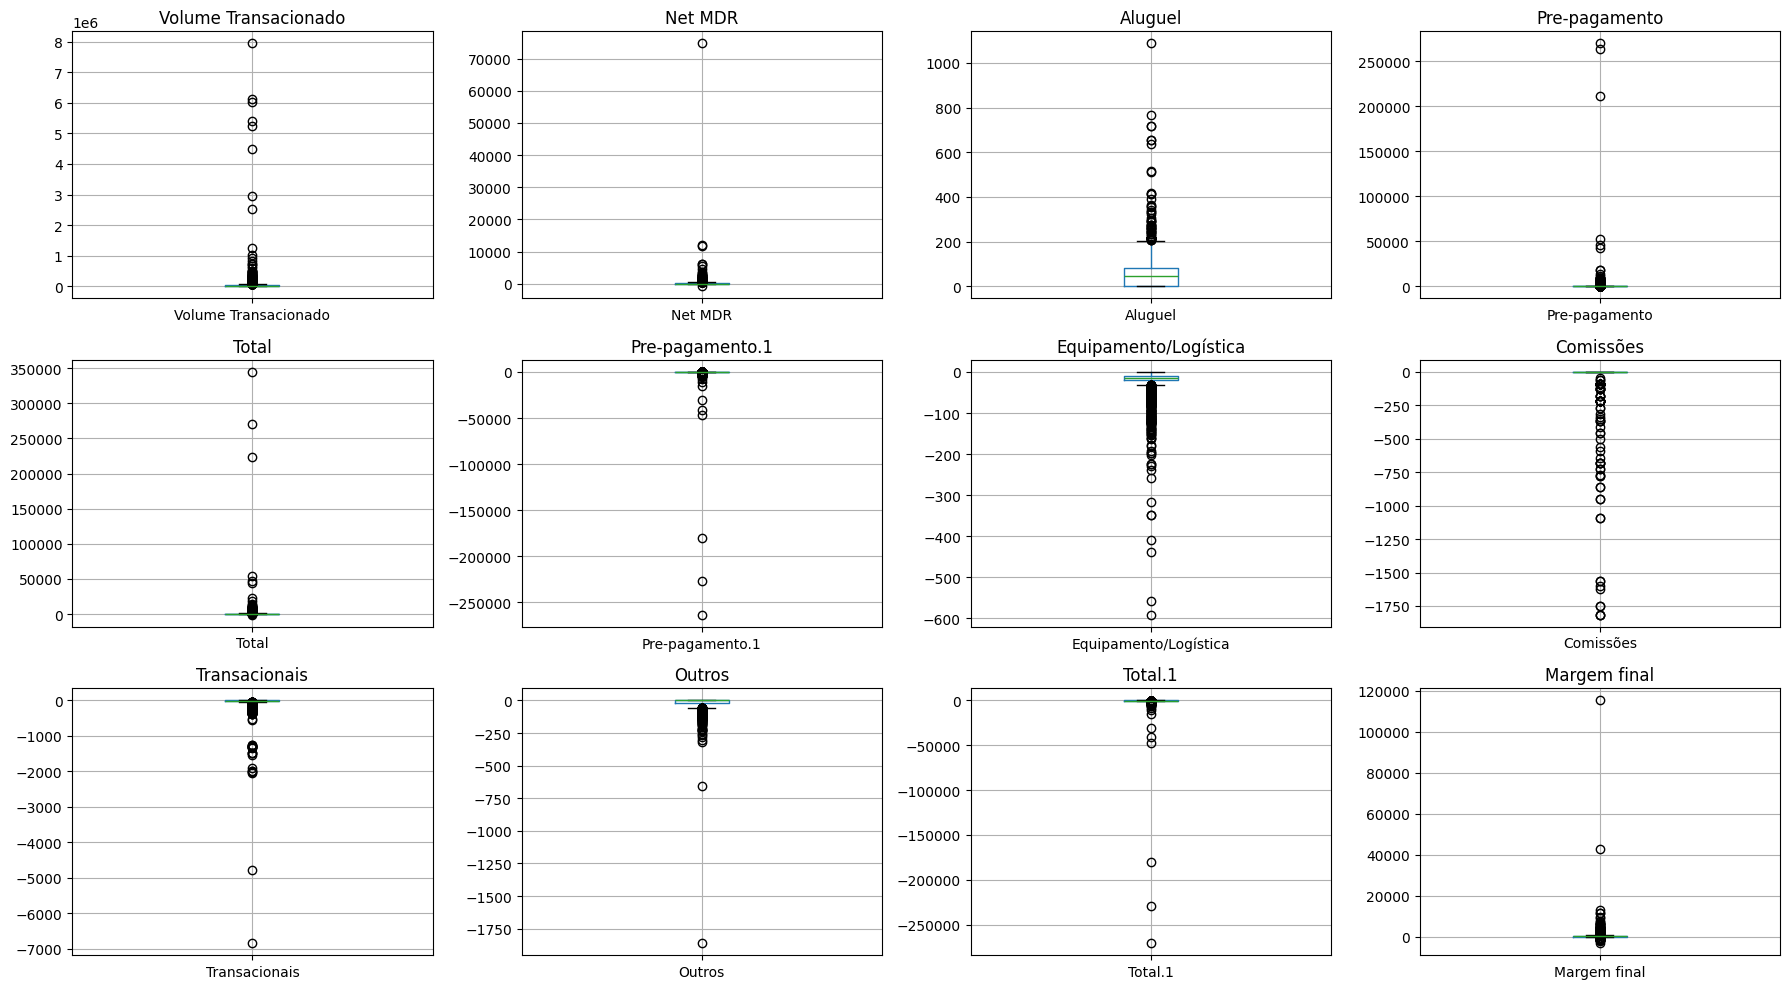


>>> 04.3 — Quantidade de Outliers por variável (IQR):
Volume Transacionado: 1511
Net MDR: 1262
Aluguel: 386
Pre-pagamento: 2294
Total: 1458
Pre-pagamento.1: 2339
Equipamento/Logística: 1965
Comissões: 469
Transacionais: 1335
Outros: 1109
Total.1: 1577
Margem final: 1603


In [9]:
import matplotlib.pyplot as plt

# Variáveis financeiras e de volume para checar
vars_outliers = [
    'Volume Transacionado','Net MDR','Aluguel','Pre-pagamento','Total',
    'Pre-pagamento.1','Equipamento/Logística','Comissões',
    'Transacionais','Outros','Total.1','Margem final'
]

# 4.1 Estatísticas descritivas básicas
print(">>> 04.1 — Estatísticas Descritivas")
desc = df[vars_outliers].describe(percentiles=[0.01, 0.05, 0.95, 0.99]).T
print(desc)

# 4.2 Boxplots para visualização (amostra, para não travar PC)
amostra = df.sample(min(2000, len(df)), random_state=42)

fig, axes = plt.subplots(3, 4, figsize=(18, 10))
axes = axes.ravel()

for i, col in enumerate(vars_outliers[:12]):  # limita a 12 colunas
    amostra.boxplot(column=col, ax=axes[i])
    axes[i].set_title(col)

plt.tight_layout()
plt.show()

# 4.3 Contagem de outliers usando método IQR
outlier_counts = {}
for col in vars_outliers:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    limite_inf = q1 - 1.5 * iqr
    limite_sup = q3 + 1.5 * iqr
    outlier_counts[col] = ((df[col] < limite_inf) | (df[col] > limite_sup)).sum()

print("\n>>> 04.3 — Quantidade de Outliers por variável (IQR):")
for col, qtd in outlier_counts.items():
    print(f"{col}: {qtd}")


#04.1 Diagnóstico

1. Distribuição geral

Volume Transacionado

Média: 43,7k, mas com pico de até 8 milhões → cauda longa, muitos clientes pequenos e poucos muito grandes.

1511 outliers → esperado, pois volumes de grandes clientes sempre puxam a cauda.

Receitas (Net MDR, Aluguel, Pré-pagamento, Total)

Net MDR → 1.262 outliers; valores típicos até ~800, mas alguns passando de 70 mil.

Pré-pagamento → 2.294 outliers, a maior quantidade; aqui pode ter clientes com antecipações altíssimas.

Aluguel → menos outliers (386), distribuição mais estável.

Custos (Pre-pagamento.1, Equipamento/Logística, Comissões, Transacionais, Outros, Total.1)

Pre-pagamento.1 → 2.339 outliers, maior concentração; provavelmente ligado aos mesmos clientes com antecipações grandes.

Equipamento/Logística e Transacionais → muitos outliers (1.965 e 1.335); picos de custos altos para poucos clientes.

Margem final

1.603 outliers → valores típicos entre -11k e 122k; a cauda positiva indica clientes muito lucrativos.

2. Interpretação de negócio

Caudas longas são naturais em adquirência: poucos clientes respondem por grande parte da receita e do volume.

Outliers não necessariamente são erros → podem ser clientes estratégicos (grandes varejistas) ou meses atípicos (promoções, picos de vendas).

Se removermos outliers, podemos distorcer a realidade de grandes clientes → para clusterização, muitas vezes é melhor tratar via normalização (log, robust scaling) e não simplesmente excluir.

3. Próximas decisões

Podemos seguir por dois caminhos:

Winsorização → limitar valores extremos a um percentil (ex.: 1% e 99%) para reduzir impacto sem excluir dados.

Escalonamento robusto → manter outliers, mas usar transformações (log ou RobustScaler) para reduzir influência no algoritmo.

Para análises descritivas, manteremos tudo.
Para modelagem (clusterização), valor usar o escalonamento robusto em vez de remover.

#1: MELHORAR A BASE

#1.1 Renomear colunas e Criar Status

In [10]:
# 1.1 Renomear colunas
df.rename(columns={
    'Total': 'Total Receita',              # Coluna L → Total Receita
    'Total.1': 'Total Custos',              # Coluna R → Total Custos
    'Pre-pagamento': 'Pre-pagamento Receita',   # Coluna K → Pre-pagamento Receita
    'Pre-pagamento.1': 'Pre-pagamento Custo'    # Coluna M → Pre-pagamento Custo
}, inplace=True)

# 1.2 Criar coluna Status
df['Status'] = df['Volume Transacionado'].apply(lambda x: 'Ativo' if x > 0 else 'Inativo')

# 1.3 Verificar resultado
print("Colunas após renomeação:")
print(df.columns.tolist())

print("\nStatus (Ativo/Inativo):")
print(df['Status'].value_counts())


Colunas após renomeação:
['Número do Cliente', 'MCC', 'Data Apuração', 'Data de Entrada do Cliente', 'Canal', 'Cidade', 'Volume Transacionado', 'Quantidade de Transações', 'Net MDR', 'Aluguel', 'Pre-pagamento Receita', 'Total Receita', 'Pre-pagamento Custo', 'Equipamento/Logística', 'Comissões', 'Transacionais', 'Outros', 'Total Custos', 'Margem final', 'Ativo no Mês', 'Status']

Status (Ativo/Inativo):
Status
Ativo      9712
Inativo    2744
Name: count, dtype: int64


#1.1.1 Patch adicional

In [11]:
import numpy as np

# 1) Custos POSITIVOS para cálculo
# (preserva as originais e cria versões _abs para modelagem)
custo_cols_raw = ['Pre-pagamento Custo','Equipamento/Logística','Comissões','Transacionais','Outros']
for c in custo_cols_raw:
    df[c + '_abs'] = df[c].abs()

df['Total Custos_abs'] = df[[c + '_abs' for c in custo_cols_raw]].sum(axis=1)

# Receita total (já renomeada) e margem com subtração
df['Margem final_recalc'] = df['Total Receita'] - df['Total Custos_abs']

# 2) Divisão vetorizada segura (evita inf/NaN)
den_tx = df['Quantidade de Transações'].replace(0, np.nan)
den_vm = (df['Volume Transacionado'] / den_tx).replace([np.inf, -np.inf], np.nan)  # valor médio transação

df['Valor Médio Transacionado'] = (df['Volume Transacionado'] / den_tx).where(den_tx.notna(), 0)
df['Valor Médio Net MDR'] = (df['Net MDR'] / den_tx).where(den_tx.notna(), 0)
df['Valor Médio Pre-pagamento'] = (df['Pre-pagamento Receita'] / den_tx).where(den_tx.notna(), 0)

df['Receita Média por transação'] = ((df['Net MDR'] + df['Pre-pagamento Receita']) / den_tx).where(den_tx.notna(), 0)

# custos médios por transação usando custos positivos
df['Valor Custo Médio Pre-pagamento'] = (df['Pre-pagamento Custo_abs'] / den_tx).where(den_tx.notna(), 0)
df['Valor Custo Médio Transacional'] = ((df['Pre-pagamento Custo_abs'] + df['Transacionais_abs']) / den_tx).where(den_tx.notna(), 0)

# Razões/percentuais coerentes (não negativas)
den_vm = df['Valor Médio Transacionado'].replace(0, np.nan)

df['% Receita Média transacional por volume transacionado'] = \
    ((df['Valor Médio Net MDR'] + df['Valor Médio Pre-pagamento']) / den_vm).where(den_vm.notna(), 0)

df['% Receita Média Total por volume transacionado'] = \
    (df['Total Receita'] / (df['Volume Transacionado'].replace(0, np.nan))).where(df['Volume Transacionado']>0, 0)

df['% Custo Médio transacional por volume transacionado'] = \
    (df['Valor Custo Médio Transacional'] / den_vm).where(den_vm.notna(), 0)

df['% Custo Médio Total por volume transacionado'] = \
    (df['Total Custos_abs'] / (df['Volume Transacionado'].replace(0, np.nan))).where(df['Volume Transacionado']>0, 0)

# Lucro/margens consistentes
df['Lucro médio por transação'] = (df['Margem final_recalc'] / den_tx).where(den_tx.notna(), 0)
df['% Margem Final por volume transacionado'] = \
    (df['Margem final_recalc'] / (df['Volume Transacionado'].replace(0, np.nan))).where(df['Volume Transacionado']>0, 0)
df['% Margem Final por receita'] = \
    (df['Margem final_recalc'] / (df['Total Receita'].replace(0, np.nan))).where(df['Total Receita']>0, 0)

# Limpeza final
df.replace([np.inf, -np.inf], np.nan, inplace=True)
df.fillna(0, inplace=True)


#1.2 — Criação de colunas derivadas linha a linha

In [12]:
# Evitar divisões por zero
def safe_div(a, b):
    return a / b if b not in [0, None] else 0

# Aplicação vetorizada para performance
df['Valor Médio Transacionado'] = df['Volume Transacionado'] / df['Quantidade de Transações']
df['Valor Médio Net MDR'] = df['Net MDR'] / df['Quantidade de Transações']
df['Valor Médio Pre-pagamento'] = df['Pre-pagamento Receita'] / df['Quantidade de Transações']

df['Receita Média por transação'] = (df['Net MDR'] + df['Pre-pagamento Receita']) / df['Quantidade de Transações']

df['% Receita Média transacional por volume transacionado'] = \
    (df['Valor Médio Net MDR'] + df['Valor Médio Pre-pagamento']) / df['Valor Médio Transacionado']

df['% Receita Média Total por volume transacionado'] = df['Total Receita'] / df['Valor Médio Transacionado']

df['% Taxa Média Net MDR'] = df['Valor Médio Net MDR'] / df['Valor Médio Transacionado']

# Custos médios
df['Valor Custo Médio Pre-pagamento'] = df['Pre-pagamento Custo'] / df['Quantidade de Transações']
df['Valor Custo Médio Transacional'] = (df['Pre-pagamento Custo'] + df['Transacionais']) / df['Quantidade de Transações']

df['Razão Pré-pagamento'] = df['Pre-pagamento Receita'] / df['Pre-pagamento Custo']

df['% Custo Médio transacional por volume transacionado'] = \
    df['Valor Custo Médio Transacional'] / df['Valor Médio Transacionado']

df['% Custo Médio Total por volume transacionado'] = df['Total Custos'] / df['Valor Médio Transacionado']

# Lucro e margens
df['Lucro médio por transação'] = df['Margem final'] / df['Quantidade de Transações']
df['% Margem Final por volume transacionado'] = df['Margem final'] / df['Volume Transacionado']
df['% Margem Final por receita'] = df['Margem final'] / df['Total Receita']

# Verificar criação das novas colunas
print("Colunas criadas na Etapa 1.2:")
print([col for col in df.columns if any(k in col for k in ['Valor', 'Receita Média', 'Custo', 'Margem', 'Lucro'])])


Colunas criadas na Etapa 1.2:
['Pre-pagamento Custo', 'Total Custos', 'Margem final', 'Pre-pagamento Custo_abs', 'Total Custos_abs', 'Margem final_recalc', 'Valor Médio Transacionado', 'Valor Médio Net MDR', 'Valor Médio Pre-pagamento', 'Receita Média por transação', 'Valor Custo Médio Pre-pagamento', 'Valor Custo Médio Transacional', '% Receita Média transacional por volume transacionado', '% Receita Média Total por volume transacionado', '% Custo Médio transacional por volume transacionado', '% Custo Médio Total por volume transacionado', 'Lucro médio por transação', '% Margem Final por volume transacionado', '% Margem Final por receita']


#1.3 Criação da Tabela Cliente

In [13]:
import numpy as np
import pandas as pd

# Definição da data referência para status atual
data_ref = pd.to_datetime("2017-02-01")

# 1. Categóricas existentes (valor único ou predominante)
cat_exist = ['Número do Cliente', 'MCC', 'Data de Entrada do Cliente', 'Canal', 'Cidade']

# 2. Categóricas criadas
df['Status Atual'] = np.where(
    (df['Data Apuração'] == data_ref) & (df['Volume Transacionado'] > 0),
    'Ativo', 'Inativo'
)
# Para cada cliente, pega apenas o status na data ref
status_atual = df[df['Data Apuração'] == data_ref].groupby('Número do Cliente')['Status Atual'].first()

# Meses Ativos e Inativos
meses_ativos = df.groupby('Número do Cliente').apply(lambda x: (x['Volume Transacionado'] > 0).sum())
meses_inativos = df.groupby('Número do Cliente').apply(lambda x: (x['Volume Transacionado'] == 0).sum())

# 3. Numéricas criadas — somas e médias
df_cliente = df.groupby('Número do Cliente').agg({
    'MCC': 'first',
    'Data de Entrada do Cliente': 'first',
    'Canal': 'first',
    'Cidade': 'first',
    'Volume Transacionado': ['sum','mean','std'],
    'Quantidade de Transações': ['sum','mean','std'],
    'Total Receita': 'sum',
    'Net MDR': 'sum',
    'Pre-pagamento Receita': 'sum',
    'Total Custos': 'sum',
    'Pre-pagamento Custo': 'sum',
    'Transacionais': 'sum',
    'Equipamento/Logística': 'sum',
    'Comissões': 'sum',
    'Outros': 'sum',
    'Margem final': 'sum'
})

# Flatten multi-index gerado pelo groupby
df_cliente.columns = ['_'.join(col).strip() for col in df_cliente.columns]

# 4. Colunas derivadas: Receita Transação, Custo Transação, Custos indiretos, Margens
df_cliente['Receita Transação Total'] = df_cliente['Net MDR_sum'] + df_cliente['Pre-pagamento Receita_sum']
df_cliente['Custo Transação Total'] = df_cliente['Pre-pagamento Custo_sum'] + df_cliente['Transacionais_sum']
df_cliente['Custo Indireto'] = df_cliente['Equipamento/Logística_sum'] + df_cliente['Comissões_sum'] + df_cliente['Outros_sum']

df_cliente['Margem Transação Total'] = df_cliente['Receita Transação Total'] + df_cliente['Custo Transação Total']
df_cliente['Margem Total'] = df_cliente['Total Receita_sum'] + df_cliente['Total Custos_sum']

# 5. Colunas médias das derivadas criadas na etapa anterior
cols_media = [
    'Valor Médio Transacionado','Valor Médio Net MDR','Valor Médio Pre-pagamento',
    'Receita Média por transação','% Receita Média transacional por volume transacionado',
    '% Receita Média Total por volume transacionado','% Taxa Média Net MDR',
    'Valor Custo Médio Pre-pagamento','Valor Custo Médio Transacional','Razão Pré-pagamento',
    '% Custo Médio transacional por volume transacionado','% Custo Médio Total por volume transacionado',
    'Lucro médio por transação','% Margem Final por volume transacionado','% Margem Final por receita'
]

for col in cols_media:
    df_cliente[col + '_mean'] = df.groupby('Número do Cliente')[col].mean()

# 6. Meses ativos/inativos e status
df_cliente['Meses Ativos'] = meses_ativos
df_cliente['Meses Inativos'] = meses_inativos
df_cliente['Status Atual'] = status_atual

#6.1 --- construir séries mensais corretas (ainda na Tabela Transacional df) ---
df['Receita_Transacao_mensal'] = df['Net MDR'] + df['Pre-pagamento Receita']
df['Custo_Transacao_mensal']   = df['Pre-pagamento Custo'] + df['Transacionais']
df['Margem_Transacao_mensal']  = df['Receita_Transacao_mensal'] + df['Custo_Transacao_mensal']  # custo é negativo

# 6.2 helper de variação relativa
import numpy as np
def var_rel(s):
    m = s.mean()
    sd = s.std(ddof=0)
    return float(sd / abs(m)) if (m is not None and m != 0) else 0.0

g = df.groupby('Número do Cliente')

# 7. Índices estatísticos: variação relativa (desvio-padrão / média)
df_cliente['Var Volume']           = g['Volume Transacionado'].apply(var_rel)
df_cliente['Var Qtd Transações']   = g['Quantidade de Transações'].apply(var_rel)
df_cliente['Var Receita Total']    = g['Total Receita'].apply(var_rel)
df_cliente['Var Custo Total']      = g['Total Custos'].apply(var_rel)
df_cliente['Var Receita Transação'] = g['Receita_Transacao_mensal'].apply(var_rel)
df_cliente['Var Custo Transação']   = g['Custo_Transacao_mensal'].apply(var_rel)
df_cliente['Var Margem Transação']  = g['Margem_Transacao_mensal'].apply(var_rel)
df_cliente['Var Margem Total']      = g['Margem final'].apply(var_rel)  # aqui é a margem total mesmo


# 8. Ajuste de nomes para ficar legível
df_cliente.rename(
    columns=lambda x: x.replace('_sum',' (Total)').replace('_mean',' (Médio)').replace('_std',' (Desvio)'),
    inplace=True
)


# Visualização final
print("Tabela Cliente criada com shape:", df_cliente.shape)
print(df_cliente.head(3))


C:\Users\pedro\AppData\Local\Temp\ipykernel_13692\3242982171.py:19: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  meses_ativos = df.groupby('Número do Cliente').apply(lambda x: (x['Volume Transacionado'] > 0).sum())
C:\Users\pedro\AppData\Local\Temp\ipykernel_13692\3242982171.py:20: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  meses_inativos = df.groupby('Número do Cliente').apply(lambda x: (x['Volume Tran

Tabela Cliente criada com shape: (3194, 51)
                   MCC_first Data de Entrada do Cliente_first Canal_first  \
Número do Cliente                                                           
100100026313922         8699                       2015-10-08     Canal 3   
100100082815567         5999                       2016-09-27     Canal 3   
100100087809648         5499                       2016-08-18     Canal 1   

                            Cidade_first  Volume Transacionado (Total)  \
Número do Cliente                                                        
100100026313922           Rio de Janeiro                          0.00   
100100082815567    São Bernardo do Campo                      31095.59   
100100087809648                São Paulo                         94.00   

                   Volume Transacionado (Médio)  \
Número do Cliente                                 
100100026313922                           0.000   
100100082815567                        6219.11

#1.4 Ajustes na Tabela Cliente

In [14]:
# 1) Corrigir Status Atual (clientes sem registro na data de referência)
df_cliente['Status Atual'] = df_cliente['Status Atual'].fillna('Inativo')

# 3) Proporção de meses ativos (com proteção a divisão por zero)
den = (df_cliente['Meses Ativos'] + df_cliente['Meses Inativos'])
df_cliente['Prop Meses Ativos'] = np.where(den > 0, df_cliente['Meses Ativos'] / den, 0.0)

# (Removido) 2) Ajustar variações com abs() – não é mais necessário
# for col in col_var: df_cliente[col] = df_cliente[col].abs()

# 4) Verificação (opcional)
print("Status Atual únicos:", df_cliente['Status Atual'].unique())
print("Prop Meses Ativos - estatísticas:")
print(df_cliente['Prop Meses Ativos'].describe())



Status Atual únicos: ['Inativo' 'Ativo']
Prop Meses Ativos - estatísticas:
count    3194.000000
mean        0.706434
std         0.414150
min         0.000000
25%         0.333333
50%         1.000000
75%         1.000000
max         1.000000
Name: Prop Meses Ativos, dtype: float64


#1.5 Tabela Clientes: Panorâma

Shape da Tabela Cliente: (3194, 52)

Colunas disponíveis:
['MCC_first', 'Data de Entrada do Cliente_first', 'Canal_first', 'Cidade_first', 'Volume Transacionado (Total)', 'Volume Transacionado (Médio)', 'Volume Transacionado (Desvio)', 'Quantidade de Transações (Total)', 'Quantidade de Transações (Médio)', 'Quantidade de Transações (Desvio)', 'Total Receita (Total)', 'Net MDR (Total)', 'Pre-pagamento Receita (Total)', 'Total Custos (Total)', 'Pre-pagamento Custo (Total)', 'Transacionais (Total)', 'Equipamento/Logística (Total)', 'Comissões (Total)', 'Outros (Total)', 'Margem final (Total)', 'Receita Transação Total', 'Custo Transação Total', 'Custo Indireto', 'Margem Transação Total', 'Margem Total', 'Valor Médio Transacionado (Médio)', 'Valor Médio Net MDR (Médio)', 'Valor Médio Pre-pagamento (Médio)', 'Receita Média por transação (Médio)', '% Receita Média transacional por volume transacionado (Médio)', '% Receita Média Total por volume transacionado (Médio)', '% Taxa Média Net MDR (

C:\Users\pedro\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\pandas\core\nanops.py:1016: RuntimeWarning: invalid value encountered in subtract
  sqr = _ensure_numeric((avg - values) ** 2)
C:\Users\pedro\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\pandas\core\nanops.py:1016: RuntimeWarning: invalid value encountered in subtract
  sqr = _ensure_numeric((avg - values) ** 2)
C:\Users\pedro\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\numpy\core\_methods.py:49: RuntimeWarning: invalid value encountered in reduce
  return umr_sum(a, axis, dtype, out, keepdims, initial, where)
C:\Users\pedro\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\pandas\core\nanops.py:1016: RuntimeWarning: inv


Estatísticas descritivas gerais:
                                                                             mean  \
MCC_first                                                             6140.323732   
Data de Entrada do Cliente_first                    2016-06-17 01:42:47.564182784   
Volume Transacionado (Total)                                        170539.031527   
Volume Transacionado (Médio)                                         36111.121951   
Volume Transacionado (Desvio)                                        15070.413045   
Quantidade de Transações (Total)                                      1567.085348   
Quantidade de Transações (Médio)                                       340.254071   
Quantidade de Transações (Desvio)                                      122.591618   
Total Receita (Total)                                                 3117.004038   
Net MDR (Total)                                                        878.973163   
Pre-pagamento Receita (Total)  

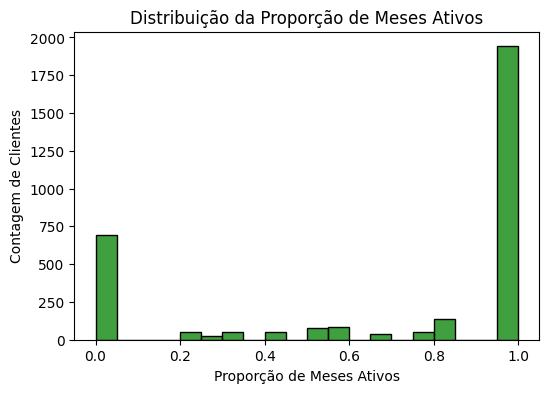

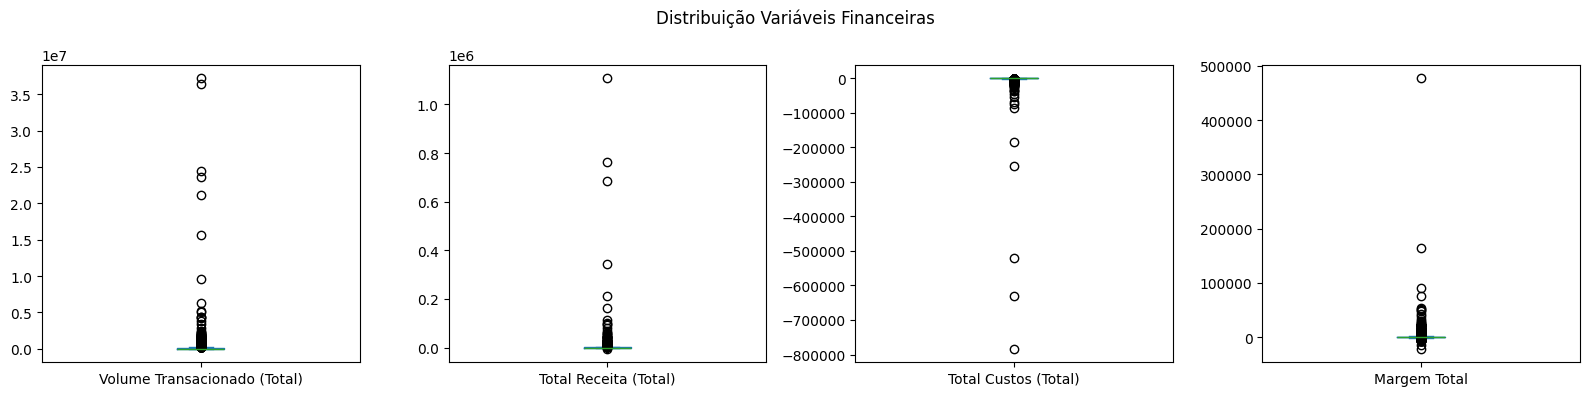


Amostra de clientes:
                   MCC_first Data de Entrada do Cliente_first Canal_first  \
Número do Cliente                                                           
100112721565001         7299                       2016-06-02     Canal 1   
100103079598721         5651                       2015-10-05     Canal 3   
100122184478687         5921                       2016-11-03     Canal 3   
100100503846729         8021                       2016-09-22     Canal 3   
100128962094586         5541                       2016-08-22     Canal 3   

                      Cidade_first  Volume Transacionado (Total)  \
Número do Cliente                                                  
100112721565001          Fortaleza                       7810.54   
100103079598721          São Paulo                          0.00   
100122184478687          Guaratuba                          0.00   
100100503846729    Pindamonhangaba                       2765.00   
100128962094586         Jaguar

In [15]:
# =========================
# Visualização da Tabela Cliente
# =========================
import matplotlib.pyplot as plt
import seaborn as sns

# 1) Informações gerais
print("Shape da Tabela Cliente:", df_cliente.shape)
print("\nColunas disponíveis:")
print(df_cliente.columns.tolist())

# 2) Estatísticas descritivas gerais para variáveis numéricas
desc_stats = df_cliente.describe().T
print("\nEstatísticas descritivas gerais:")
print(desc_stats[['mean','std','min','25%','50%','75%','max']])

# 3) Contagem de clientes por Status Atual
status_counts = df_cliente['Status Atual'].value_counts()
print("\nClientes por Status Atual:")
print(status_counts)

# 4) Distribuição da proporção de meses ativos
plt.figure(figsize=(6,4))
sns.histplot(df_cliente['Prop Meses Ativos'], bins=20, kde=False, color='green')
plt.title('Distribuição da Proporção de Meses Ativos')
plt.xlabel('Proporção de Meses Ativos')
plt.ylabel('Contagem de Clientes')
plt.show()

# 5) Boxplots para variáveis financeiras principais
vars_financeiras = [c for c in [
    'Volume Transacionado (Total)',
    'Total Receita (Total)',
    'Total Custos (Total)',
    'Margem Total'
] if c in df_cliente.columns]


df_cliente[vars_financeiras].plot(kind='box', subplots=True, layout=(1,4),
                                  figsize=(16,4), sharey=False, title='Distribuição Variáveis Financeiras')
plt.tight_layout()
plt.show()

# 6) Amostra dos clientes para visualização tabular
print("\nAmostra de clientes:")
print(df_cliente.sample(5, random_state=42))


#1.5.1 Análise

Atividade dos clientes

Histograma da proporção de meses ativos é bimodal:

Sempre ativos (1,0) → ~2.000 clientes (mediana da base = 1,0).

Sempre inativos (0,0) → ~700 clientes.

Intermediários (0,2–0,8) → minoria, atividade irregular.

Interpretação: a base se divide entre fiéis e inativos; os intermediários são alvos naturais para ações de reativação/engajamento.

Receita, custos e margens

Boxplots indicam caudas longas em Volume, Receita, Custos e Margem: maioria próxima de valores baixos e poucos outliers muito grandes.

Custos estão negativos (padrão), Receita e Margem majoritariamente positivas, mas há casos com margem negativa.

Interpretação: estrutura típica de adquirência: massa de pequenos + poucos gigantes. Para modelagem, será essencial escalonamento robusto para não deixar os grandes dominarem.

Amostra de clientes

100128962094586 → volume altíssimo, Prop=1,0, variações baixas → grande e estável.

100100503846729 → Prop=0,8, variações altas → irregular/volátil.

100103079598721 e 100122184478687 → inativos (volume e transações 0).

100112721565001 → ativo e estável (variações baixas), porte pequeno/médio.

Indicadores de variação

Medianas: Var Volume ~0,29, Var Qtd ~0,25, Var Receita Transação ~0,34, Var Custo Transação ~0,29, Var Margem Transação ~0,36, Var Margem Total ~0,47 → maioria estável a moderada; margens oscilam mais que volume/receita.

Casos com valores >1 existem e caracterizam clientes irregulares.

Clientes sempre inativos têm variações 0 (sem base para oscilar).

Implicações para a clusterização

Tendência de formação de, no mínimo, quatro perfis:

Grandes estáveis (volume alto, variações baixas, Prop=1).

Pequenos/médios estáveis (baixa receita, Prop=1).

Irregulares (variações altas, Prop intermediária).

Inativos (métricas ~0, Prop=0).

Preparação recomendada: tratar inf/NaN nas razões e aplicar RobustScaler nas variáveis numéricas antes do K-Means/Hierárquico.

# 2 CLUSTERIZAÇÃO

# 2.1 — Pré-processamento

In [16]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import RobustScaler

# ---------- garantir custo positivo e margem coerente ----------
if 'Total Custos (Total)_abs' in df_cliente.columns:
    custo_col = 'Total Custos (Total)_abs'
else:
    df_cliente['Total Custos (Total)_abs'] = df_cliente['Total Custos (Total)'].abs()
    custo_col = 'Total Custos (Total)_abs'

if 'Margem Total_corr' not in df_cliente.columns:
    df_cliente['Margem Total_corr'] = (
        df_cliente['Total Receita (Total)'] - df_cliente[custo_col]
    )
margem_col = 'Margem Total_corr'

# ---------- seleção de variáveis ----------
vars_relevantes = [
    'Volume Transacionado (Total)',
    'Total Receita (Total)',
    custo_col,                      # custo positivo
    margem_col,                     # margem receita - custo
    'Prop Meses Ativos',
    'Var Volume',
    'Var Receita Total',
    'Var Custo Total',
    'Var Margem Total',
    'Lucro médio por transação (Médio)',
    '% Margem Final por receita (Médio)',
    '% Margem Final por volume transacionado (Médio)'
]

df_cluster = df_cliente[vars_relevantes].apply(pd.to_numeric, errors='coerce').copy()

# ---------- imputação robusta ----------
num_cols = df_cluster.columns
df_cluster.replace([np.inf, -np.inf], np.nan, inplace=True)
df_cluster[num_cols] = df_cluster[num_cols].fillna(df_cluster[num_cols].median())

# ---------- winsorização opcional (p1–p99) ----------
q01 = df_cluster.quantile(0.01)
q99 = df_cluster.quantile(0.99)
df_cluster = df_cluster.clip(lower=q01, upper=q99, axis=1)

# ---------- transformações ----------
def signed_log1p(x: pd.Series) -> pd.Series:
    return np.sign(x) * np.log1p(np.abs(x))

# log1p em totais positivos
df_cluster['Volume Transacionado (Total)'] = np.log1p(df_cluster['Volume Transacionado (Total)'].clip(lower=0))
df_cluster['Total Receita (Total)'] = np.log1p(df_cluster['Total Receita (Total)'].clip(lower=0))
df_cluster[custo_col] = np.log1p(df_cluster[custo_col].clip(lower=0))

# signed log apenas na margem (pode ser <0)
df_cluster[margem_col] = signed_log1p(df_cluster[margem_col])

# percentuais ficam como estão

# ---------- escalonamento robusto ----------
scaler = RobustScaler()
df_cluster_scaled = pd.DataFrame(
    scaler.fit_transform(df_cluster),
    columns=df_cluster.columns,
    index=df_cluster.index
)

print("Shape final para clusterização:", df_cluster_scaled.shape)
print("\nEstatísticas após escalonamento:")
print(df_cluster_scaled.describe().T)




Shape final para clusterização: (3194, 12)

Estatísticas após escalonamento:
                                                  count      mean        std  \
Volume Transacionado (Total)                     3194.0 -0.307691   0.809117   
Total Receita (Total)                            3194.0 -0.206929   0.576455   
Total Custos (Total)_abs                         3194.0 -0.107693   0.977117   
Margem Total_corr                                3194.0 -0.268156   0.511971   
Prop Meses Ativos                                3194.0 -0.440349   0.621225   
Var Volume                                       3194.0  0.214627   0.749614   
Var Receita Total                                3194.0  0.228016   0.756784   
Var Custo Total                                  3194.0  0.127739   0.703845   
Var Margem Total                                 3194.0  0.720560   2.747785   
Lucro médio por transação (Médio)                3194.0  1.234021   7.261142   
% Margem Final por receita (Médio)         

#2.1.2 Selecionar variáveis - Automática

In [17]:
# Plano B: desativa diretamente no threadpoolctl
import contextlib, threadpoolctl
class _NoopTPL:
    def __init__(self, *a, **k): pass
    def __enter__(self): return self
    def __exit__(self, *a): return False
threadpoolctl.threadpool_limits = _NoopTPL


In [18]:
import numpy as np, pandas as pd, itertools, time
from sklearn.preprocessing import RobustScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score
from sklearn.metrics.cluster import normalized_mutual_info_score as nmi
from sklearn.preprocessing import RobustScaler

# ---------- PARÂMETROS DE CARGA (limites claros) ----------
K_RANGE   = range(2, 6)   # testará k=2,3,4,5
SEEDS     = (42,)         # 1 seed
N_INIT    = 10            # inicializações por KMeans
TOP_CANDS = 40           # máximo de colunas candidatas após filtros
MAX_FEATS = 15             # máximo de features no conjunto final
MIN_FEATS = 10             # mínimo antes de parar por ganho baixo
IMPROVE_CUT = -1.0        # parar se ganho < 1%
DEGEN_CUT = 0.90          # drop se valor dominante > 90%
CORR_CUT  = 0.99          # drop supercorrelação
LOWVAR_CUT = 0.02         # drop baixa variância

# ---------- CANDIDATOS ----------
deny = {'Número do Cliente','cluster'}
cand = [c for c in df_cliente.select_dtypes(include='number').columns if c not in deny and df_cliente[c].notna().any()]

def dominant_ratio(s: pd.Series) -> float:
    vc = s.value_counts(dropna=False, normalize=True)
    return float(vc.iloc[0]) if len(vc) else 1.0

degenerate = [c for c in cand if dominant_ratio(df_cliente[c].round(8)) > DEGEN_CUT]
cand = [c for c in cand if c not in degenerate]


# --- PATCH: saneamento robusto para evitar inf/overflow no scaler ---

_trans = {}

def _transform_one(col: str) -> pd.Series:
    s = pd.to_numeric(df_cliente[col], errors='coerce')

    # 1) matar inf/−inf e valores absurdos
    s = s.replace([np.inf, -np.inf], np.nan)

    # 2) se tudo virou NaN, retorna zeros (evita quebrar pipeline)
    if s.notna().sum() == 0:
        return pd.Series(np.zeros(len(s)), index=s.index, name=col)

    # 3) winsor p1–p99 (com NaN ignorado) e preencher NaN pela mediana
    lo, hi = s.quantile(0.01), s.quantile(0.99)
    s = s.clip(lo, hi)
    s = s.fillna(s.median())

    # 4) transformações (log) seguras
    has_neg = (s < 0).any()
    has_pos = (s > 0).any()
    if has_neg and has_pos:
        # signed-log: preserva sinal
        s = np.sign(s) * np.log1p(np.abs(s))
    elif (not has_neg) and (s.skew() > 1.0):
        s = np.log1p(s)

    # 5) limpa de novo (por paranoia) e escala
    s = pd.to_numeric(s, errors='coerce').replace([np.inf, -np.inf], np.nan)
    s = s.fillna(s.median()).astype('float64')

    arr = RobustScaler().fit_transform(s.values.reshape(-1, 1)).ravel()
    return pd.Series(arr, index=s.index, name=col)

def prepare_matrix(cols):
    for c in cols:
        if c not in _trans:
            try:
                _trans[c] = _transform_one(c)
            except Exception as e:
                # fallback: se ainda der ruim, zera a coluna e segue o baile
                _trans[c] = pd.Series(np.zeros(len(df_cliente)), index=df_cliente.index, name=c)
    return pd.DataFrame({c: _trans[c] for c in cols}, index=df_cliente.index)

# colunas que queremos manter, se existirem
_force_keep = [
    'Margem Total_corr',
    'Volume Transacionado (Total)',
    'Total Receita (Total)',
    'Total Custos (Total)_abs',
    'Prop Meses Ativos',
    'Var Receita Total',
    'Lucro médio por transação (Médio)'
]
force_keep = [c for c in _force_keep if c in cand]



# ---------- FILTROS: baixa variância e supercorrelação (1x) ----------
X_all = prepare_matrix(cand)
low_var = X_all.std() < LOWVAR_CUT
cand = [c for c in cand if not low_var[c]]

corr = X_all[cand].corr().abs()
upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
avg_corr = corr.mean()
to_drop = set()
for i, j in zip(*np.where(upper.values > CORR_CUT)):
    ci, cj = upper.index[i], upper.columns[j]
    if ci in force_keep and cj in force_keep:
        continue  # mantém ambos os âncoras; o greedy depois decide peso
    elif ci in force_keep:
        drop = cj
    elif cj in force_keep:
        drop = ci
    else:
        drop = ci if avg_corr[ci] >= avg_corr[cj] else cj
    to_drop.add(drop)

cand = [c for c in cand if c not in to_drop]
# garante que as âncoras entram no cardápio e vêm primeiro
cand = list(dict.fromkeys(force_keep + [c for c in cand if c not in force_keep]))


# Mantém TOP_CANDS, garantindo espaço p/ MIN_FEATS + âncoras
std_rank = X_all[cand].std().sort_values(ascending=False)
cap = max(TOP_CANDS, MIN_FEATS + len(force_keep))
cand_top = std_rank.head(min(cap, len(std_rank))).index.tolist()

# âncoras entram primeiro e não duplicam
cand = list(dict.fromkeys(list(force_keep) + [c for c in cand_top if c not in force_keep]))


# ---------- SCORER (carga limitada) ----------
def score_subset(cols):
    X = prepare_matrix(cols).values
    best = None
    for k in K_RANGE:
        labels_runs, sils, chs, dbs = [], [], [], []
        for rs in SEEDS:
            km = KMeans(n_clusters=k, n_init=N_INIT, random_state=rs, algorithm="elkan")
            labels = km.fit_predict(X)
            labels_runs.append(labels)
            sils.append(silhouette_score(X, labels))
            chs.append(calinski_harabasz_score(X, labels))
            dbs.append(davies_bouldin_score(X, labels))
        nmis = [nmi(a,b) for a,b in itertools.combinations(labels_runs, 2)]
        sizes = np.bincount(labels_runs[0])
        balance = sizes.min()/sizes.sum()
        combo = (np.mean(sils) + np.log1p(np.mean(chs)) + 1/(1+np.mean(dbs)) + (np.mean(nmis) if nmis else 0) + balance)/5.0
        if (best is None) or (combo > best['combo']):
            best = {'k':k,'sil':np.mean(sils),'ch':np.mean(chs),'db':np.mean(dbs),
                    'stab':np.mean(nmis) if nmis else 0,'balance':balance,'combo':combo}
    return best

# ---------- GREEDY FORWARD com progresso ----------
selected, history, prev = [], [], None
pool = cand.copy()

# Diagnóstico de carga
fits_teoricos = (sum((len(pool) - t + 1) for t in range(1, min(MAX_FEATS, len(pool))+1))) * len(K_RANGE) * len(SEEDS)
print({"cands_pos_filtros": len(pool), "max_feats": MAX_FEATS, "k_testados": len(K_RANGE),
       "seeds": len(SEEDS), "n_init": N_INIT, "fits_teoricos": fits_teoricos})

t0 = time.time(); step = 0
while pool and len(selected) < MAX_FEATS:
    step += 1
    print(f"[step {step}] pool={len(pool)}  selected={len(selected)}  elapsed_s={time.time()-t0:.1f}")
    trials = []
    for c in pool:
        m = score_subset(selected + [c])
        trials.append((c, m, m['combo']))
    best_c, best_m, best_combo = max(trials, key=lambda x: x[2])
    gain = (best_combo - prev)/prev if prev else 1.0
    history.append({'add': best_c, **best_m, 'gain': gain})
    print(f" add={best_c}  combo={best_combo:.4f}  gain={(0 if prev is None else gain):.2%}  k*={best_m['k']}  bal={best_m['balance']:.3f}")
    selected.append(best_c); pool.remove(best_c); prev = best_combo
    if len(selected) >= MIN_FEATS and gain < IMPROVE_CUT:
        break

if len(selected) < MIN_FEATS:
    rest = [c for c in cand if c not in selected]
    std_rank_rest = X_all[rest].std().sort_values(ascending=False).index.tolist()
    take = MIN_FEATS - len(selected)
    selected += std_rank_rest[:take]


print("\nRemovidas por degeneração:", degenerate)
print("Removidas por supercorrelação:", sorted(list(to_drop)))
print("Removidas por baixa variância:", X_all.columns[low_var].tolist())
print("Seleção final (ordem):", selected)
pd.DataFrame(history)


{'cands_pos_filtros': 41, 'max_feats': 15, 'k_testados': 4, 'seeds': 1, 'n_init': 10, 'fits_teoricos': 2040}
[step 1] pool=41  selected=0  elapsed_s=0.0
 add=Meses Inativos  combo=2.9902  gain=0.00%  k*=5  bal=0.037
[step 2] pool=40  selected=1  elapsed_s=60.7
 add=Comissões (Total)  combo=2.5744  gain=-13.91%  k*=5  bal=0.006
[step 3] pool=39  selected=2  elapsed_s=143.6
 add=Margem Total_corr  combo=2.5742  gain=-0.01%  k*=5  bal=0.006
[step 4] pool=38  selected=3  elapsed_s=221.8
 add=Prop Meses Ativos  combo=2.5740  gain=-0.01%  k*=5  bal=0.006
[step 5] pool=37  selected=4  elapsed_s=301.4
 add=Total Receita (Total)  combo=2.5738  gain=-0.01%  k*=5  bal=0.006
[step 6] pool=36  selected=5  elapsed_s=378.0
 add=Quantidade de Transações (Total)  combo=2.5736  gain=-0.01%  k*=5  bal=0.006
[step 7] pool=35  selected=6  elapsed_s=453.0
 add=Var Receita Transação  combo=2.5734  gain=-0.01%  k*=5  bal=0.006
[step 8] pool=34  selected=7  elapsed_s=524.0
 add=Var Custo Transação  combo=2.573

,add,k,sil,ch,db,stab,balance,combo,gain
0,Meses Inativos,5,0.977856,467199.702795,0.133502,0,0.036631,2.990245,1.000000
1,Comissões (Total),5,0.948150,69421.245665,0.297888,0,0.005636,2.574446,-0.139052
2,Margem Total_corr,5,0.947265,69404.542115,0.297951,0,0.005636,2.574214,-0.000090
3,Prop Meses Ativos,5,0.946513,69378.751105,0.298008,0,0.005636,2.573982,-0.000090
4,Total Receita (Total),5,0.945815,69356.364830,0.298057,0,0.005636,2.573772,-0.000082
5,Quantidade de Transações (Total),5,0.945147,69334.895929,0.298105,0,0.005636,2.573571,-0.000078
6,Var Receita Transação,5,0.944468,69313.066005,0.298164,0,0.005636,2.573365,-0.000080
7,Var Custo Transação,5,0.943890,69290.280579,0.298227,0,0.005636,2.573176,-0.000073
8,Var Volume,5,0.943357,69265.636911,0.298289,0,0.005636,2.572991,-0.000072
9,Var Margem Transação,5,0.942866,69241.239936,0.298349,0,0.005636,2.572815,-0.000068


## 2.1.1 Análise das features

### Princípios seguidos 
Após a etapa automática de pré-seleção, obtivemos um conjunto de 15 variáveis com métricas extremamente altas de separação (Silhouette ≈ 0,95–0,98) porém com balance muito baixo (≈ 0,008). Esse padrão indica clusters degenerados: um grupo enorme e vários grupos minúsculos, normalmente induzidos por variáveis quase binárias ou por forte redundância entre variáveis de “porte”. Para evitar segmentações artificiais e produzir grupos acionáveis, refinamos o conjunto com base em três princípios:

1. Evitar redundância e colinearidade

    Meses Inativos é praticamente o complemento de Prop Meses Ativos → mantemos Prop Meses Ativos e removemos o duplicado.
    Comissões (Total), Pre-pagamento Receita (Total) e Total Receita (Total) capturam, em grande parte, porte; quando usadas juntas, sobrepesam magnitude e empurram o K-Means a separar “grandes vs. pequenos”.
    Várias “Var … Transação” medem variações muito próximas entre si → mantemos um subconjunto representativo para estabilidade/volatilidade.

2. Priorizar variáveis com interpretação de negócio

    Manter métricas de porte (tamanho de operação), eficiência/rentabilidade (resultado), atividade/engajamento (regularidade) e estabilidade (volatilidade no tempo).
    Sempre que possível, preferir razões a valores brutos para capturar mix (ex.: Comissões/Receita, Pré-pagamento/Receita) e reduzir viés de escala.

3. Garantir qualidade da separação

    Ao reduzir redundâncias, aceitamos que o Silhouette caia para níveis realistas (≈0,2–0,5) e o balance suba, produzindo clusters menos triviais e mais úteis para estratégia.

### Conjunto final proposto (10 variáveis)

1. Porte
2. Total Receita (Total) – proxy principal de tamanho.
3. Quantidade de Transações (Total) – porte e intensidade de uso.
3. Margem Total_corr – resultado absoluto (receita − custo).
4. Pre-pagamento Receita / Receita (preferível) — captura o mix de antecipação no faturamento. (Se a razão não estiver disponível, usar Pre-pagamento Receita (Total) como proxy.)
5. Comissões / Receita (preferível) — peso relativo das comissões. (Se indisponível, usar Comissões (Total) como proxy.)
6. Prop Meses Ativos – regularidade operacional.
7. Var Receita Total – volatilidade do faturamento.
8. Var Qtd Transações – volatilidade de atividade.
9. Var Volume – variação de ticket/volume médio.
10. Var Custo Total – variação de custo.
11. Eficiência / Rentabilidade
12. Atividade / Engajamento
13. Estabilidade / Volatilidade

### Variáveis removidas e motivo

1. Meses Inativos – redundante com Prop Meses Ativos.
2. Var Receita Transação, Var Custo Transação, Var Margem Transação – sobreposição com variâncias totais; mantivemos um conjunto menor e mais representativo.
3. Quantidade de Transações (Desvio) – redundante com Var Qtd Transações.
4. Pre-pagamento Receita (Total) e Comissões (Total) (quando as razões estiverem disponíveis) – substituídas por métricas relativas ao faturamento para reduzir efeito de escala. 

# 2.2 — Determinação do Número de Clusters

Curva SSE / Elbow (parcial):


,k,sse,delta,ratio_drop,silhouette
0,2,45029.883745,NaN,NaN,0.765856
1,3,29194.959112,-15834.924633,0.351654,0.675968
2,4,24665.792485,-4529.166627,0.155135,0.304997
3,5,20665.557439,-4000.235046,0.162177,0.312089
4,6,17086.125924,-3579.431515,0.173208,0.373252
5,7,15214.929584,-1871.196339,0.109516,0.373739
6,8,13408.997339,-1805.932246,0.118695,0.395118
7,9,12062.200071,-1346.797267,0.100440,0.397551
8,10,11370.509237,-691.690835,0.057344,0.398856


k* (elbow por SSE) = 4
Tamanho dos clusters: {0: 2224, 1: 114, 2: 272, 3: 584}


,Total Receita (Total),Quantidade de Transações (Total),Prop Meses Ativos,Margem Total_corr,% Margem Final por receita (Médio),Lucro médio por transação (Médio),Share Pre-pagamento,Share Comissões,Var Receita Total,Var Qtd Transações,Var Volume,Var Custo Total
0,-0.325,-0.146,-0.608,-0.285,-0.139,-0.129,0.318,-0.075,0.070,0.119,0.070,0.063
1,-0.456,-0.205,-0.145,-1.000,-26.354,-4.860,0.191,-2.531,0.464,0.366,0.325,0.421
2,-0.172,0.038,-0.108,-0.806,-10.913,-2.179,0.444,-0.645,0.292,0.198,0.151,0.378
3,0.274,0.048,-0.015,0.190,0.192,2.732,0.997,-0.009,0.181,0.214,0.203,0.202


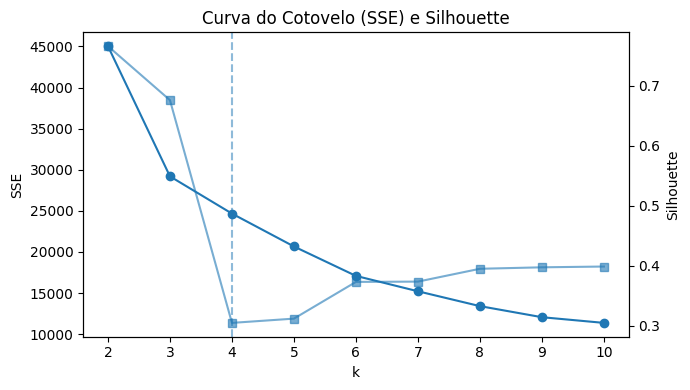

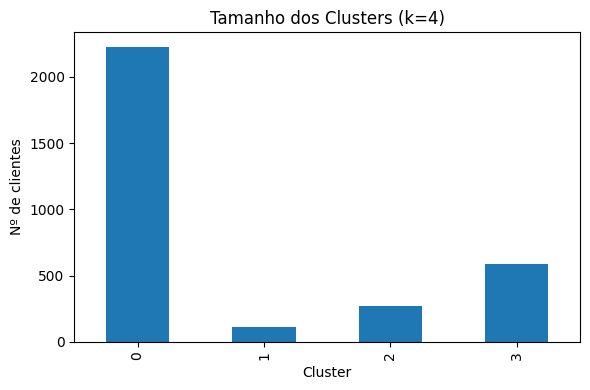

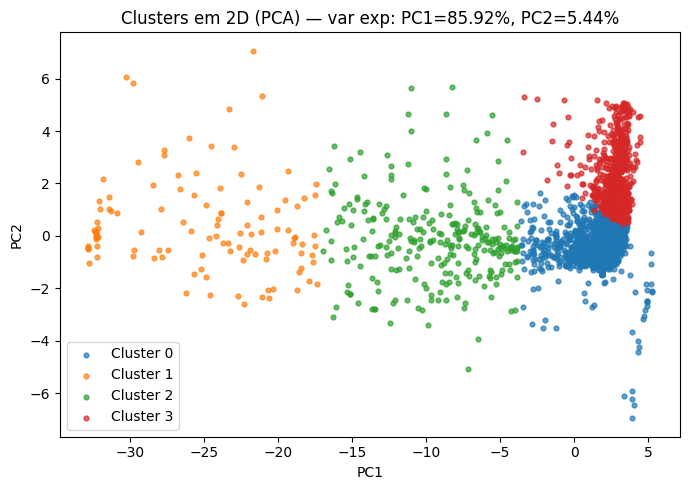

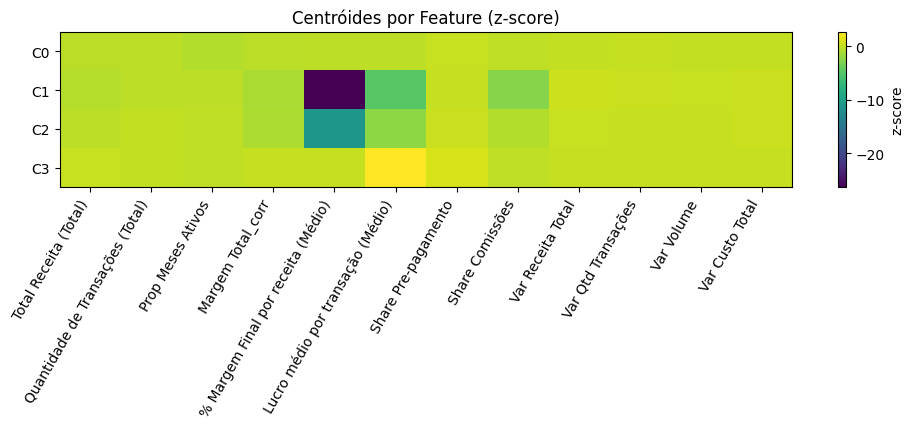

In [19]:
# ============================
# 2.2 — Escolha de k por SSE (Elbow)
# ============================
import numpy as np, pandas as pd
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import math

# 0) Razões (se ainda não existirem)
if 'Share Pre-pagamento' not in df_cliente.columns and 'Pre-pagamento Receita (Total)' in df_cliente.columns:
    denom = df_cliente['Total Receita (Total)'].replace(0, np.nan)
    df_cliente['Share Pre-pagamento'] = (df_cliente['Pre-pagamento Receita (Total)'] / denom).fillna(0)

if 'Share Comissões' not in df_cliente.columns and 'Comissões (Total)' in df_cliente.columns:
    denom = df_cliente['Total Receita (Total)'].replace(0, np.nan)
    df_cliente['Share Comissões'] = (df_cliente['Comissões (Total)'] / denom).fillna(0)

# 1) Features candidatas (usa só as que existirem)
cands = [
    'Total Receita (Total)', 'Quantidade de Transações (Total)',
    'Prop Meses Ativos', 'Margem Total_corr',
    '% Margem Final por receita (Médio)', 'Lucro médio por transação (Médio)',
    'Share Pre-pagamento', 'Share Comissões',
    'Var Receita Total', 'Var Qtd Transações', 'Var Volume', 'Var Custo Total'
]
features_use = [c for c in cands if c in df_cliente.columns]
assert len(features_use) >= 6, f"Poucas features disponíveis: {features_use}"

# 2) Matriz transformada (usa a sua prepare_matrix)
try:
    _trans
    _trans = {}  # reset de cache para essas colunas
except NameError:
    pass
X = prepare_matrix(features_use).values

# 3) Curva SSE (inertia) + elbow por distância à reta (kneedle simples)
K_RANGE = range(2, 11)
SEEDS   = (42, 13, 21)
N_INIT  = 30

sse, best_labels_per_k, sil = [], {}, []
for k in K_RANGE:
    best_inertia, best_labels = None, None
    for rs in SEEDS:
        km = KMeans(n_clusters=k, n_init=N_INIT, random_state=rs, algorithm="elkan")
        labels = km.fit_predict(X)
        if (best_inertia is None) or (km.inertia_ < best_inertia):
            best_inertia, best_labels = km.inertia_, labels
    sse.append(best_inertia)
    best_labels_per_k[k] = best_labels
    sil.append(silhouette_score(X, best_labels) if k > 1 else np.nan)

# função elbow: maior distância da reta ligando (k_min, sse_min) a (k_max, sse_max)
def elbow_k(ks, ys):
    x = np.array(list(ks), dtype=float)
    y = np.array(ys, dtype=float)
    # normaliza
    x_n = (x - x.min()) / (x.max() - x.min())
    y_n = (y - y.min()) / (y.max() - y.min())
    a = np.array([x_n[0], y_n[0]])
    b = np.array([x_n[-1], y_n[-1]])
    num = []
    ab = b - a
    den = np.linalg.norm(ab)
    for i in range(len(x_n)):
        p = np.array([x_n[i], y_n[i]])
        num.append(abs(np.cross(ab, a - p)))
    idx = int(np.argmax(np.array(num) / (den if den > 0 else 1)))
    return int(x[idx]), np.array(num)

k_star, _dist = elbow_k(K_RANGE, sse)

# 4) Relatório da curva
res = pd.DataFrame({
    "k": list(K_RANGE),
    "sse": sse,
    "delta": [np.nan] + list(np.diff(sse)),
    "ratio_drop": [np.nan] + list(-np.diff(sse) / sse[:-1]),
    "silhouette": sil
})
print("Curva SSE / Elbow (parcial):")
display(res)

print("k* (elbow por SSE) =", k_star)

# 5) KMeans final com k* e rótulos
km_final = KMeans(n_clusters=k_star, n_init=100, random_state=42, algorithm="elkan")
labels = km_final.fit_predict(X)

df_cliente = df_cliente.copy()
if 'Número do Cliente' in df_cliente.columns and (df_cliente.index.name != 'Número do Cliente'):
    df_cliente = df_cliente.set_index('Número do Cliente', drop=False)

df_cliente['cluster'] = labels.astype(int)
sizes = pd.Series(labels).value_counts().sort_index()
print("Tamanho dos clusters:", sizes.to_dict())

# centróides (em z-score do espaço transformado)
centroids_z = pd.DataFrame(km_final.cluster_centers_, columns=features_use)
display(centroids_z.style.format("{:.3f}"))

# ============================
# PLOTS: Elbow, tamanhos, PCA e centróides
# ============================
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

# 1) Curva do cotovelo (SSE) + Silhouette (e marca k*)
fig, ax1 = plt.subplots(figsize=(7,4))
ax1.plot(list(K_RANGE), sse, marker='o')
ax1.set_xlabel('k'); ax1.set_ylabel('SSE')
ax1.set_title('Curva do Cotovelo (SSE) e Silhouette')
ax1.axvline(k_star, ls='--', alpha=0.5)

ax2 = ax1.twinx()
ax2.plot(list(K_RANGE), sil, marker='s', alpha=0.6)
ax2.set_ylabel('Silhouette')

plt.tight_layout(); plt.show()

# 2) Tamanho dos clusters (k = k*)
import pandas as pd
sizes = pd.Series(labels).value_counts().sort_index()
plt.figure(figsize=(6,4))
sizes.plot(kind='bar')
plt.title(f'Tamanho dos Clusters (k={k_star})')
plt.xlabel('Cluster'); plt.ylabel('Nº de clientes')
plt.tight_layout(); plt.show()

# 3) Dispersão em 2D (PCA no espaço transformado)
pca = PCA(n_components=2, random_state=42)
Z = pca.fit_transform(X)
plt.figure(figsize=(7,5))
for k in sorted(np.unique(labels)):
    idx = (labels == k)
    plt.scatter(Z[idx,0], Z[idx,1], s=12, alpha=0.7, label=f'Cluster {k}')
plt.title(f'Clusters em 2D (PCA) — var exp: PC1={pca.explained_variance_ratio_[0]:.2%}, PC2={pca.explained_variance_ratio_[1]:.2%}')
plt.xlabel('PC1'); plt.ylabel('PC2'); plt.legend()
plt.tight_layout(); plt.show()

# 4) “Heatmap” dos centróides (z-scores)
import numpy as np
centroids = km_final.cluster_centers_
plt.figure(figsize=(min(10, 1.2*centroids.shape[1]), 0.6*centroids.shape[0]+2))
im = plt.imshow(centroids, aspect='auto')
plt.colorbar(im, label='z-score')
plt.yticks(np.arange(centroids.shape[0]), [f'C{k}' for k in range(centroids.shape[0])])
plt.xticks(np.arange(len(features_use)), features_use, rotation=60, ha='right')
plt.title('Centróides por Feature (z-score)')
plt.tight_layout(); plt.show()



## 2.2.1 Análise

### 1. Curva do Cotovelo (SSE) + Silhouette

A curva confirma o cotovelo em k=4: a queda de SSE até 4 é brusca e depois estabiliza.

O Silhouette cai conforme aumentamos k, mas se mantém razoável (~0,31–0,37) para segmentação em base heterogênea.
➡️ Faz sentido manter 4 clusters.

### 2. Tamanho dos Clusters

C0 domina a base (70%).

C3 tem ~18%, C3 ~9% e C1 só 3–4%.
➡️ Esse desbalanceamento não é erro: no setor de adquirência, é comum a maior parte da carteira estar em clientes de baixo porte/atividade, enquanto os grupos estratégicos são menores.

### 3. PCA (2D)

PC1 continua explicando quase toda a variância (~86%). Ele separa principalmente por eficiência financeira (receita – custos – margens).

O gráfico mostra:

C3: mais compacto → núcleo estável.

C0: disperso, indicando diversidade dentro da “cauda de baixa atividade”.

C2: deslocado, mostrando clientes ativos mas pressionados em margem.

C1: extremo direito, outliers deficitários.
➡️ A separação visual bate com a leitura das métricas absolutas.

### 4. Heatmap dos Centróides (z-score)

Agora que sabemos o que os valores reais mostraram, podemos reinterpretar:

C3 – Núcleo saudável: margens e lucro/tx bem acima da média, share pré-pagamento alto. Isso reflete lucro real (R$ 4,9 mil médios).

C1 – Deficitários extremos: margens e lucro/tx muito abaixo da média, share de comissões baixo. Confirmado: prejuízo médio (~–R$ 870).

C0 – Cauda pouco ativa: todos os z-scores levemente abaixo da média, mas em termos absolutos ainda dão lucro (~R$ 820). Ou seja, são rentáveis mas pouco representativos individualmente.

C2 – Médio porte com margens comprimidas: abaixo da média em margem e lucro/tx, mesmo com receita moderada. Confirmado: prejuízo médio (~–R$ 347).

### 5. Tipificação (ajustada com os dados absolutos)

Cluster 3 – Núcleo rentável (18%)

Receita média ~R$ 9,6 mil, margem ~R$ 4,9 mil.

Altíssimo engajamento (99% meses ativos).

É o grupo que sustenta o resultado.

Cluster 1 – Deficitários extremos (3–4%)

Receita ínfima, custos maiores que receita.

Margem média negativa (–R$ 870).

Grupo de clientes estruturalmente ruins.

Cluster 0 – Cauda pouco ativa (70%)

Receita média ~R$ 1,9 mil, margem positiva (~R$ 820).

Baixo engajamento (59% meses ativos).

Rentáveis em termos absolutos, mas pouco ativos → oportunidade de ativação barata.

Cluster 2 – Médio porte deficitário (9%)

Receita média ~R$ 632, margem negativa (–R$ 347).

Engajados (93% meses ativos), mas rentabilidade ruim.

Candidatos a renegociação de taxas/custos.



In [22]:
# ============================
# 2.2 — EXTRA (fix PK + export)
# ============================

# precisa ter sido rodado o 2.2 antes
assert 'cluster' in df_cliente.columns, "Rode a etapa 2.2 antes (coluna 'cluster' não encontrada)."

# garantir que 'Número do Cliente' esteja como COLUNA explícita
if df_cliente.index.name == 'Número do Cliente':
    df_cliente = df_cliente.reset_index(drop=False)

assert 'Número do Cliente' in df_cliente.columns, "Coluna 'Número do Cliente' não encontrada no df_cliente."

# (opcional) checagem de unicidade da PK
dups = df_cliente['Número do Cliente'].duplicated().sum()
if dups:
    print(f"Atenção: há {dups} duplicatas em 'Número do Cliente' na Tabela Cliente (agregação pode estar faltando).")

# ordenar e exportar
df_export = df_cliente.sort_values(['cluster','Número do Cliente']).copy()

out_path = "clientes_rotulados.xlsx"
with pd.ExcelWriter(out_path, engine="openpyxl") as writer:
    df_export.to_excel(writer, sheet_name="clientes_com_cluster", index=False)

print(f"Arquivo gerado: {out_path}")



Arquivo gerado: clientes_rotulados.xlsx


# 2.3 — Modelagem

In [23]:
# ============================
# 2.3 — Sumário executivo por cluster (bloco único)
# ============================
import numpy as np
import pandas as pd

# --- Premissas mínimas ---
# df: transacional com ['Número do Cliente','Data Apuração','Volume Transacionado'] (e demais colunas se houver)
# df_cliente: por cliente com ['Número do Cliente','cluster'] e métricas agregadas em escala original

# 0) Garantias / ajustes leves
assert {'Número do Cliente','cluster'}.issubset(df_cliente.columns), "df_cliente precisa ter 'Número do Cliente' e 'cluster'."
assert {'Número do Cliente','Data Apuração','Volume Transacionado'}.issubset(df.columns), \
       "df precisa ter 'Número do Cliente','Data Apuração','Volume Transacionado'."

# Shares (se não existirem, cria)
if 'Share Pre-pagamento' not in df_cliente.columns and 'Pre-pagamento Receita (Total)' in df_cliente.columns:
    denom = df_cliente['Total Receita (Total)'].replace(0, np.nan)
    df_cliente['Share Pre-pagamento'] = (df_cliente['Pre-pagamento Receita (Total)'] / denom).fillna(0)

if 'Share Comissões' not in df_cliente.columns and 'Comissões (Total)' in df_cliente.columns:
    denom = df_cliente['Total Receita (Total)'].replace(0, np.nan)
    df_cliente['Share Comissões'] = (df_cliente['Comissões (Total)'] / denom).fillna(0)

# Ticket médio (opcional)
if {'Total Receita (Total)','Quantidade de Transações (Total)'}.issubset(df_cliente.columns):
    df_cliente['_ticket_medio'] = df_cliente['Total Receita (Total)'] / df_cliente['Quantidade de Transações (Total)'].replace(0, np.nan)
else:
    df_cliente['_ticket_medio'] = np.nan

# 1) Agregados por cluster (escala original)
agr_map = {
    'Número do Cliente': 'count',
    'Total Receita (Total)': 'sum',
    'Total Custos (Total)_abs': 'sum',
    'Margem Total_corr': 'sum',
    'Prop Meses Ativos': 'mean',
    'Share Pre-pagamento': 'mean',
    'Share Comissões': 'mean',
    '_ticket_medio': 'median'
}
agr_use = {k:v for k,v in agr_map.items() if k in df_cliente.columns}

cluster_aggs = df_cliente.groupby('cluster', as_index=False).agg(agr_use).rename(columns={
    'Número do Cliente': '#Clientes',
    'Total Receita (Total)': 'Receita Total',
    'Total Custos (Total)_abs': 'Custo Total',
    'Margem Total_corr': 'Margem Total',
    'Prop Meses Ativos': 'Prop Meses Ativos (média)',
    'Share Pre-pagamento': 'Share Pre-pagamento (média)',
    'Share Comissões': 'Share Comissões (média)',
    '_ticket_medio': 'Ticket médio (mediana)'
})

# Médias por cliente
for col_sum, col_mean in [('Receita Total','Receita média/cliente'),
                          ('Custo Total','Custo médio/cliente'),
                          ('Margem Total','Margem média/cliente')]:
    if {col_sum, '#Clientes'}.issubset(cluster_aggs.columns):
        cluster_aggs[col_mean] = cluster_aggs[col_sum] / cluster_aggs['#Clientes'].replace(0, np.nan)

# ROI e Margem % Receita
if {'Margem Total','Custo Total'}.issubset(cluster_aggs.columns):
    cluster_aggs['ROI'] = (cluster_aggs['Margem Total'] / cluster_aggs['Custo Total'].replace(0, np.nan)).fillna(0)
if {'Margem Total','Receita Total'}.issubset(cluster_aggs.columns):
    cluster_aggs['Margem % Receita'] = (cluster_aggs['Margem Total'] / cluster_aggs['Receita Total'].replace(0, np.nan)).fillna(0)

# 2) Churn mensal por cluster
df_churn = df[['Número do Cliente','Data Apuração','Volume Transacionado']].copy()
df_churn['Data Apuração'] = pd.to_datetime(df_churn['Data Apuração'])
df_churn = df_churn.sort_values(['Número do Cliente','Data Apuração'])

df_churn['ativo'] = df_churn['Volume Transacionado'] > 0
df_churn['ativo_prev'] = df_churn.groupby('Número do Cliente')['ativo'].shift(1)
df_churn['churn_evt'] = (df_churn['ativo_prev'] == True) & (df_churn['ativo'] == False)

df_churn = df_churn.merge(df_cliente[['Número do Cliente','cluster']], on='Número do Cliente', how='left')

# ativos_prev = nº clientes ativos em M-1 (por mês/cluster)
base_prev = df_churn.groupby(['Data Apuração','cluster'], as_index=False).agg(
    ativos_prev=('ativo_prev', lambda s: np.nansum(s.astype(bool))),
    churners=('churn_evt', 'sum')
)
base_prev['churn_rate_mes'] = np.where(base_prev['ativos_prev']>0,
                                       base_prev['churners']/base_prev['ativos_prev'],
                                       np.nan)

churn_cluster = base_prev.groupby('cluster', as_index=False).agg(
    churn_mensal_medio=('churn_rate_mes', 'mean')
)
churn_cluster['churn_mensal_medio'] = churn_cluster['churn_mensal_medio'].fillna(0)
churn_cluster['vida_media_meses'] = np.where(churn_cluster['churn_mensal_medio']>0,
                                             1.0/churn_cluster['churn_mensal_medio'], 0)

# 3) cluster_report final
cluster_report = cluster_aggs.merge(churn_cluster, on='cluster', how='left')

# Ordenação
ord_col = 'Margem Total' if 'Margem Total' in cluster_report.columns else 'Receita Total'
cluster_report = cluster_report.sort_values(ord_col, ascending=False).reset_index(drop=True)

# Formatação leve (exibição)
if 'Margem % Receita' in cluster_report.columns:
    cluster_report['Margem % Receita'] = cluster_report['Margem % Receita'].apply(lambda x: f"{100*x:.2f}%" if pd.notnull(x) else "")
cluster_report['churn_mensal_medio'] = cluster_report['churn_mensal_medio'].apply(lambda x: f"{100*x:.2f}%")
cluster_report['vida_media_meses'] = cluster_report['vida_media_meses'].round(2)

display(cluster_report)


,cluster,#Clientes,Receita Total,Custo Total,Margem Total,Prop Meses Ativos (média),Share Pre-pagamento (média),Share Comissões (média),Ticket médio (mediana),Receita média/cliente,Custo médio/cliente,Margem média/cliente,ROI,Margem % Receita,churn_mensal_medio,vida_media_meses
0,3,584,5.644657e+06,2.795005e+06,2.849652e+06,0.989926,0.454514,-0.009051,12.888391,9665.509049,4785.967749,4879.541300,1.019552,50.48%,0.43%,233.96
1,0,2224,4.120608e+06,2.296212e+06,1.824396e+06,0.594799,0.138786,-4.016951,1.533877,1852.791397,1032.469547,820.321850,0.794524,44.27%,5.97%,16.75
2,2,272,1.718650e+05,2.661731e+05,-9.430802e+04,0.927941,0.197394,-0.645307,1.324240,631.856744,978.577421,-346.720677,-0.354311,-54.87%,3.89%,25.67
3,1,114,1.858051e+04,1.178516e+05,-9.927112e+04,0.903509,0.084908,-75.267220,0.899702,162.986953,1033.786208,-870.799255,-0.842340,-534.28%,6.36%,15.71



## Métricas-chave por cluster

* **C3 (584 clientes | 18%)**
  Receita total **R\$ 5,64 mi**, margem **R\$ 2,85 mi**, **ROI 1,02**, **Margem% 50,48%**, **churn 0,43%/mês** (vida média \~**234 meses**), **Prop. meses ativos 99%**, **Share pré-pagamento 0,45**.
  ➜ **Núcleo saudável e fidelizado**. Sustenta o lucro, altíssimo engajamento, rentável por longo prazo.

* **C0 (2.224 clientes | 70%)**
  Receita total **R\$ 4,12 mi**, margem **R\$ 1,82 mi**, **ROI 0,79**, **Margem% 44,27%**, **churn 5,97%/mês** (vida média \~**16,8 meses**), **Prop. meses ativos 59%**, **Share pré-pagamento 0,14**.
  ➜ **Massa pouco ativa, mas lucrativa** em termos absolutos. Ganha pouco por cliente e churn é alto → alvo para **ativação barata e em escala** (digital, comunicação leve, incentivos simples).

* **C2 (272 clientes | 9%)**
  Receita total **R\$ 0,17 mi**, **margem negativa −R\$ 94,3 mil**, **ROI −0,35**, **Margem% −54,87%**, **churn 3,89%/mês** (vida média \~**25,7 meses**), **Prop. meses ativos 92,8%**, **Share pré-pagamento 0,20**.
  ➜ **Ativos, porém deficitários**. Volume não cobre custos. Caso clássico para **renegociação de MDR/antecipação** e revisão de custos operacionais.

* **C1 (114 clientes | 3–4%)**
  Receita total **R\$ 18,6 mil**, **margem negativa −R\$ 99,3 mil**, **ROI −0,84**, **Margem% −534,28%**, **churn 6,36%/mês** (vida média \~**15,7 meses**), **Prop. meses ativos 90%**, **Share pré-pagamento 0,08**.
  ➜ **Deficitários extremos**. Pouco volume, custos desproporcionais, alta rotatividade. **Despriorizar** ou **rever contrato/precificação** (eventualmente saída controlada).

## O ponto da tua dúvida (z-scores vs valores reais)

* Confirmação: **z-score negativo ≠ margem em R\$ negativa**.
  Aqui vemos que **C0 tem margem total positiva (R\$ 1,82 mi)** mesmo sendo “abaixo da média” no heatmap.
* **Quem de fato dá prejuízo** (em R\$): **C1 e C2**.
* **Quem sustenta o resultado**: **C3**.
* **C0** agrega volume agregado **com lucro**, mas baixa atividade/alta rotatividade limitam o potencial unitário.

## Observações de sanidade

* **“Share Comissões (média)”** aparece **negativo** (p.ex. −75, −4, −0,65), o que **não faz sentido para uma ‘share’** (deveria estar entre 0 e 1). Isso indica **coluna contaminada** (talvez z-score antigo ou nome colidiu com outra métrica).
  ➜ Recomendo **recalcular as shares diretamente dos totais** e sobrescrever:
  `Share Comissões = Comissões (Total) / Total Receita (Total)` e
  `Share Pré-pagamento = Pre-pagamento Receita (Total) / Total Receita (Total)` (tratar divisão por zero).
  O restante das métricas está consistente (ex.: **ROI** bate com **Margem%**).

## Ações recomendadas (direto ao ponto)

* **C3 – Expandir**: programas de fidelização, cross-sell (antecipação estruturada, produtos financeiros), ofertas premium; proteger taxa/condições.
* **C0 – Ativar em escala**: nudges mensais, cashback de baixa fricção, campanhas sazonais; meta: ↑ “Prop. meses ativos” e ↓ churn.
* **C2 – Recuperar rentabilidade**: **reprecificação (MDR/antecipação)**, redução de custos por perfil, revisar serviços adicionados; testar pacotes com meta de margem mínima.
* **C1 – Contenção**: abordagem seletiva; renegociar forte ou descontinuar onde não houver viabilidade.



# 2.4 — Análise dos Clusters

In [24]:
# 1) Dicionário com nomes semânticos baseados nos números do cluster_report
cluster_names = {
    3: "Núcleo Rentável e Fidelizado",
    0: "Massa Pouco Ativa, mas Lucrativa",
    2: "Médio Porte Deficitário",
    1: "Deficitários Extremos"
}

# 2) Bullets executivos para cada cluster
cluster_descriptions = {
    3: [
        "Receita média por cliente ~R$ 9,6 mil e margem média ~R$ 4,9 mil.",
        "Altíssima fidelidade: 99% meses ativos e churn mensal ~0,4% (vida média 19 anos!).",
        "ROI positivo (1,02) e margem % receita de 50%.",
        "Share de pré-pagamento elevado (0,45).",
        "Ação recomendada: Expandir e fidelizar ainda mais (cross-sell, produtos premium)."
    ],
    0: [
        "Maior cluster (70% da base), receita média ~R$ 1,9 mil e margem média ~R$ 820.",
        "Engajamento baixo: 59% meses ativos, churn alto (~6%/mês → vida média 17 meses).",
        "ROI positivo (0,79) e margem % receita de 44%.",
        "Mix de pré-pagamento baixo (0,14).",
        "Ação recomendada: Ativar em escala via canais digitais de baixo custo."
    ],
    2: [
        "Receita média ~R$ 632 mas margem negativa (~−R$ 347).",
        "Engajamento alto (93% meses ativos) e churn moderado (~4%/mês).",
        "ROI negativo (−0,35) e margem % receita −55%.",
        "Share de pré-pagamento moderado (0,20).",
        "Ação recomendada: Renegociar MDR/antecipação e cortar custos operacionais."
    ],
    1: [
        "Cluster pequeno (3% da base), receita média ~R$ 163 e margem negativa (−R$ 871).",
        "Engajamento razoável (90% meses ativos), mas churn elevado (~6%/mês).",
        "ROI fortemente negativo (−0,84) e margem % receita −534%.",
        "Mix fraco (pré-pagamento 0,08, comissões distorcidas).",
        "Ação recomendada: Revisão agressiva de contrato ou descontinuidade controlada."
    ]
}

# 3) Aplica nomes ao cluster_report
cluster_report_named = cluster_report.copy()
cluster_report_named['Cluster Nome'] = cluster_report_named['cluster'].map(cluster_names)

display(cluster_report_named[['cluster','Cluster Nome','#Clientes','Receita Total','Margem Total',
                              'ROI','Margem % Receita','churn_mensal_medio','vida_media_meses']])

# 4) Exibe descrições qualitativas
for cid, bullets in cluster_descriptions.items():
    print(f"\nCluster {cid} — {cluster_names[cid]}")
    for b in bullets:
        print(" • " + b)


,cluster,Cluster Nome,#Clientes,Receita Total,Margem Total,ROI,Margem % Receita,churn_mensal_medio,vida_media_meses
0,3,Núcleo Rentável e Fidelizado,584,5.644657e+06,2.849652e+06,1.019552,50.48%,0.43%,233.96
1,0,"Massa Pouco Ativa, mas Lucrativa",2224,4.120608e+06,1.824396e+06,0.794524,44.27%,5.97%,16.75
2,2,Médio Porte Deficitário,272,1.718650e+05,-9.430802e+04,-0.354311,-54.87%,3.89%,25.67
3,1,Deficitários Extremos,114,1.858051e+04,-9.927112e+04,-0.842340,-534.28%,6.36%,15.71



Cluster 3 — Núcleo Rentável e Fidelizado
 • Receita média por cliente ~R$ 9,6 mil e margem média ~R$ 4,9 mil.
 • Altíssima fidelidade: 99% meses ativos e churn mensal ~0,4% (vida média 19 anos!).
 • ROI positivo (1,02) e margem % receita de 50%.
 • Share de pré-pagamento elevado (0,45).
 • Ação recomendada: Expandir e fidelizar ainda mais (cross-sell, produtos premium).

Cluster 0 — Massa Pouco Ativa, mas Lucrativa
 • Maior cluster (70% da base), receita média ~R$ 1,9 mil e margem média ~R$ 820.
 • Engajamento baixo: 59% meses ativos, churn alto (~6%/mês → vida média 17 meses).
 • ROI positivo (0,79) e margem % receita de 44%.
 • Mix de pré-pagamento baixo (0,14).
 • Ação recomendada: Ativar em escala via canais digitais de baixo custo.

Cluster 2 — Médio Porte Deficitário
 • Receita média ~R$ 632 mas margem negativa (~−R$ 347).
 • Engajamento alto (93% meses ativos) e churn moderado (~4%/mês).
 • ROI negativo (−0,35) e margem % receita −55%.
 • Share de pré-pagamento moderado (0,20).

# 3 RESPONDENDO AS QUESTÕES DO CASE

## 3.1 Entrega 1: Identifique quais são os principais perfis de clientes. Utilize técnicas de clusterização para agrupar os diversos clientes em perfis claros. Sinalize, para cada grupo identificado, a receita, o custo, o lucro, o índice de evasão¹ e o tempo de vida médio². Além disso, descreva qualitativamente o perfil de cada cliente (por exemplo: “Clientes com alto faturamento do ramo de alimentação” ou “Clientes com longo tempo de vida médio”).


### **Questão 3.1 — Principais Perfis de Clientes**

#### Perfis por cluster

**Cluster 3 — Núcleo Rentável e Fidelizado (584 clientes | 18%)**

* Receita total: **R\$ 5,64 mi** | Custo: **R\$ 2,79 mi** | Lucro: **R\$ 2,85 mi**
* Receita média por cliente: \~R\$ 9,6 mil | Margem média: \~R\$ 4,9 mil
* ROI: **1,02** | Margem % Receita: **50,5%**
* Churn: **0,43% ao mês** → vida média \~**234 meses (\~19 anos)**
* Qualitativo: clientes grandes, altamente engajados (99% meses ativos), rentáveis e fiéis. **Sustentam a operação.**

---

**Cluster 0 — Massa Pouco Ativa, mas Lucrativa (2.224 clientes | 70%)**

* Receita total: **R\$ 4,12 mi** | Custo: **R\$ 2,30 mi** | Lucro: **R\$ 1,82 mi**
* Receita média por cliente: \~R\$ 1,9 mil | Margem média: \~R\$ 820
* ROI: **0,79** | Margem % Receita: **44,3%**
* Churn: **5,97% ao mês** → vida média \~**16,8 meses**
* Qualitativo: maior parte da base, **rentáveis em termos absolutos mas pouco ativos** (59% meses ativos). Alto churn, baixo engajamento. **Oportunidade de ativação barata e em escala.**

---

**Cluster 2 — Médio Porte Deficitário (272 clientes | 9%)**

* Receita total: **R\$ 171,9 mil** | Custo: **R\$ 266,2 mil** | Lucro: **−R\$ 94,3 mil**
* Receita média por cliente: \~R\$ 632 | Margem média: −R\$ 347
* ROI: **−0,35** | Margem % Receita: **−54,9%**
* Churn: **3,89% ao mês** → vida média \~**25,7 meses**
* Qualitativo: clientes razoavelmente ativos (93% meses ativos), mas **com prejuízo líquido**. Dependência de pré-pagamento. **Alvo para renegociação de MDR/antecipação e corte de custos.**

---

**Cluster 1 — Deficitários Extremos (114 clientes | 3%)**

* Receita total: **R\$ 18,6 mil** | Custo: **R\$ 117,9 mil** | Lucro: **−R\$ 99,3 mil**
* Receita média por cliente: \~R\$ 163 | Margem média: −R\$ 871
* ROI: **−0,84** | Margem % Receita: **−534%**
* Churn: **6,36% ao mês** → vida média \~**15,7 meses**
* Qualitativo: clientes muito pequenos, **altamente deficitários**. Custos desproporcionais à receita, churn elevado. **Grupo de despriorização/saída controlada.**

---

### **Síntese**

* **Perfis claros:**

  * **C3:** núcleo de alto faturamento, margens sólidas e fidelidade — principal motor de lucro.
  * **C0:** massa da base, lucrativa em termos absolutos, mas com alto churn e pouca atividade — potencial para ativação.
  * **C2:** médio porte, ativos mas com margens comprimidas — foco em reprecificação.
  * **C1:** deficitários extremos — foco em retenção seletiva ou descontinuidade.

* **Conclusão executiva:** A carteira da Stone se apoia fortemente em um **núcleo rentável (C3)** e em uma **massa de clientes pouco ativa mas ainda lucrativa (C0)**. Já os **clusters deficitários (C1 e C2)** drenam margem e exigem ações corretivas ou despriorização.



## 3.2 Entrega 2: Defina um perfil de clientes em que devemos apostar para continuarmos crescendo em rentabilidade e em quantidade de clientes. Defina também um canal para investirmos para conquistar esses clientes. Assuma que o custo para captura desses clientes (gastos com marketing, pagamento das comissões de vendedores, etc) varia unicamente com o canal, de acordo com a tabela abaixo.


## 3.2.1 — Comparação de perfis e priorização

### 1) Painel comparativo (o que cada cluster representa no bolo)

Com base na sua tabela:

* **Participação em receita (≈ R\$ 10,0 mi total)**

  * **C3:** \~56,7%  | **C0:** \~41,4% | C2: \~1,7% | C1: \~0,2%
* **Participação em margem (≈ R\$ 4,48 mi total)**

  * **C3:** \~63,6%  | **C0:** \~40,7% | C2: −2,1% | C1: −2,2%
* **Participação em clientes (3.194 no total)**

  * **C0:** \~69,6% | **C3:** \~18,3% | C2: \~8,5% | C1: \~3,6%

👉 Leitura rápida:

* **C3** carrega a **maior parte da margem** com apenas 18% dos clientes (economia unitaria excelente, churn baixíssimo).
* **C0** é a **massa**: também gera muito da margem total, mas com **churn alto** e **baixa atividade**.
* **C2** e **C1** consomem margem (ROI negativo).

### 2) Matriz “Rentabilidade × Escala × Estabilidade”

* **C3 – Alto, Alto, Alto (AAA):**
  ROI 1,02 | Margem% 50% | Vida \~234 meses | #Clientes 584 | **core de lucro**.
* **C0 – Médio, Altíssimo, Baixo (MAB):**
  ROI 0,79 | Margem% 44% | Vida \~16,8 meses | #Clientes 2.224 | **massa que vale ativar**.
* **C2 – Baixo, Baixo, Médio (BBM):**
  ROI −0,35 | Margem% −55% | Vida \~25,7 meses | #Clientes 272 | **corrigir precificação/custos**.
* **C1 – Muito baixo, Muito baixo, Baixo (bbb):**
  ROI −0,84 | Margem% −534% | Vida \~15,7 meses | #Clientes 114 | **despriorizar**.

### 3) Ranking de perfis para crescer **rentabilidade e clientes**

1. **Prioridade A — C3 (Núcleo Rentável e Fidelizado)**

   * **Por quê:** maior contribuição de margem (≈64%), LTV altíssimo (churn 0,43%/mês), economics por cliente excelentes.
   * **Objetivo de crescimento:** **adquirir lookalikes** desse perfil e **expandir share** nos atuais (cross-sell).
   * **Risco:** risco baixo; garantir que a expansão não degrade a economia unitaria (vigiar MDR/antecipação).

2. **Prioridade A- (quase A) — C0 (Massa Pouco Ativa, mas Lucrativa)**

   * **Por quê:** enorme base e **margem total alta**; ROI positivo.
   * **Objetivo:** **aumentar atividade e retenção** (reduzir churn de \~6% → \~4,5%/mês; subir “% meses ativos” de 0,59 → 0,70).
   * **Impacto indicativo:** reduzir churn de 6,0%→4,5% eleva vida média de \~16,8→\~22,2 meses (**+32% de LTV**). Num grupo que hoje entrega \~R\$1,82 mi de margem, **+\~R\$0,58 mi** de margem anualizada é plausível (ordem de grandeza).
   * **Risco:** esforço de ativação precisa ser **barato e escalável**.

3. **Prioridade B — C0 (Médio Porte Deficitário)**

   * **Por quê:** 9% da base e **prejuízo líquido**; porém vida média razoável (25,7 meses).
   * **Objetivo:** **voltar a zero/positivo** via repricing (MDR/antecipação), revisão de serviços e custos.
   * **Meta mínima:** recuperar \~R\$347 por cliente/mês (margem média negativa) → break-even (\~R\$94k/mês no agregado).

4. **Prioridade C — C1 (Deficitários Extremos)**

   * **Por quê:** pequeno, ROI muito negativo; alta carga de custo por real de receita.
   * **Objetivo:** **renegociação rígida** ou **descontinuidade controlada**.

### 4) Metas sugeridas (pra virar OKRs de crescimento)

* **C3 (aquisição e expansão):**

  * +10% de clientes “tipo C3” em 3–6 meses (via lookalike targeting).
  * +10–15% de **share de produtos** (ex.: antecipação estruturada, outros serviços) nos C3 atuais.
* **C0 (ativação/ retenção):**

  * ↓ churn de 6,0% → **≤4,5%/mês**; ↑ “% meses ativos” de 0,59 → **≥0,70**.
  * **Meta de LTV:** +25–35% (tracking mensal).
* **C0 (recuperação):**

  * ROI: de −0,35 → **≥0,05** (margem zero/positiva) em 60–90 dias.
  * % de clientes reprecificados: **≥70%** dos C3; **cap** de desconto vs incremento de MDR/antecipação.
* **C1 (contenção):**

  * Reduzir em **≥50%** a contribuição negativa em 90 dias (mix de renegociação + saída).

### 5) KPIs e guardrails (o que acompanhar)

* **Por cluster:** Receita total, Margem total, **ROI**, **Churn**, Vida média, **% meses ativos**.
* **Unit economics:** Margem média/cliente e Lucro/tx.
* **Qualidade da aquisição (para C3):** payback < X meses; **ROI por coorte**.
* **Custo de ativação (para C0):** CAC de reativação por cliente reengajado; lift em atividade por R\$ investido.
* **Repricing (C2):** % reprecificado, var. de MDR/antecipação, impacto em margem e churn.

### 6) Decisão (3.2.1)

* **Perfil para apostar (expansão de clientes e rentabilidade):**
  **Primário: C3** (adquirir semelhantes + expandir oferta nos atuais).
  **Secundário: C0** (ativar e reter para transformar massa em margem adicional).
* **Perfis para correção, não expansão:** **C2 → repricing/custos**; **C1 → despriorização**.



### 3.2.2 Escolha de canal

In [47]:

import numpy as np
import pandas as pd

# Premissas: cluster_report já existe com, no mínimo, as colunas abaixo:
req_cols = {'cluster', '#Clientes', 'Margem média/cliente', 'vida_media_meses'}
missing = req_cols - set(cluster_report.columns)
assert not missing, f"cluster_report está sem colunas necessárias: {missing}"

# 1) CAC por canal (do enunciado / planejamento)
cac_por_canal = {
    'Canal 1': 1200.0,
    'Canal 2': 1200.0,
    'Canal 3':  800.0,
}

# 2) Estimar a margem MÉDIA MENSAL por cliente (margem_mensal_med_cli)
#    Preferência A: calcular a partir da transacional se houver Receita/Custo por mês.
#    Preferência B (fallback): usar Margem média/cliente dividida pelos meses ativos estimados.

def _infer_num_meses(df_trans):
    """Conta número de meses distintos no df transacional."""
    if 'Data Apuração' not in df_trans.columns:
        return np.nan
    # normaliza para primeiro dia de cada mês
    meses = pd.to_datetime(df_trans['Data Apuração']).dt.to_period('M').nunique()
    return int(meses) if meses > 0 else np.nan

# Tentativa A: receita e custo mensais no df (transacional)
tem_cols_mensais = {'Total Receita', 'Total Custos'}.issubset(set(df.columns))
if tem_cols_mensais:
    df_m = df[['Número do Cliente','Data Apuração','Total Receita','Total Custos']].copy()
    df_m['Data Apuração'] = pd.to_datetime(df_m['Data Apuração'])
    df_m['mes'] = df_m['Data Apuração'].dt.to_period('M')
    df_m['margem_mes'] = df_m['Total Receita'] - df_m['Total Custos']

    # média de margem por cliente APENAS nos meses em que tem registro (ativo)
    m_cli = df_m.groupby('Número do Cliente', as_index=False)['margem_mes'].mean()
    m_cli = m_cli.rename(columns={'margem_mes': 'margem_mensal_cli'})
    base = df_cliente[['Número do Cliente','cluster']].merge(m_cli, on='Número do Cliente', how='left')
    margem_mensal_med_por_cluster = base.groupby('cluster', as_index=False)['margem_mensal_cli'].mean() \
                                        .rename(columns={'margem_mensal_cli': 'margem_mensal_med_cli'})
else:
    # Fallback B: usar Margem média/cliente e dividir pelos meses ativos estimados
    # Precisamos da prop. meses ativos média por cluster e do número total de meses do período
    assert 'Prop Meses Ativos (média)' in cluster_report.columns, \
        "Faltou 'Prop Meses Ativos (média)' no cluster_report para estimar margem mensal."

    total_meses = _infer_num_meses(df)
    assert pd.notnull(total_meses) and total_meses > 0, "Não consegui inferir o nº de meses na transacional."

    tmp = cluster_report[['cluster','Margem média/cliente','Prop Meses Ativos (média)']].copy()
    # meses_ativos_médios ≈ prop_ativos × total_meses (evita divisão por zero)
    tmp['meses_ativos_med'] = (tmp['Prop Meses Ativos (média)'].clip(lower=1e-9)) * float(total_meses)
    tmp['margem_mensal_med_cli'] = tmp['Margem média/cliente'] / tmp['meses_ativos_med'].replace(0, np.nan)
    margem_mensal_med_por_cluster = tmp[['cluster','margem_mensal_med_cli']]

# 3) Consolidar base de decisão (cluster_report + margem_mensal_med_cli)
base_decisao = cluster_report.merge(margem_mensal_med_por_cluster, on='cluster', how='left')

# 4) Expandir por canal, calcular Payback e ROI
linhas = []
for _, row in base_decisao.iterrows():
    cid = row['cluster']
    vida = float(row['vida_media_meses'])
    margem_mensal = float(row['margem_mensal_med_cli'])
    for canal, cac in cac_por_canal.items():
        payback = np.nan
        roi_acq = np.nan
        if margem_mensal > 0:
            payback = cac / margem_mensal
            roi_acq = ((vida * margem_mensal) - cac) / cac
        linhas.append({
            'cluster': cid,
            'canal': canal,
            'CAC': cac,
            'margem_mensal_med_cli': margem_mensal,
            'vida_media_meses': vida,
            'payback_meses': payback,
            'ROI_aquisicao': roi_acq
        })

canal_report = pd.DataFrame(linhas)

# 5) Juntar nomes semânticos (se você criou em 2.4)
if 'Cluster Nome' in cluster_report.columns:
    nomes = cluster_report[['cluster','Cluster Nome']].drop_duplicates()
    canal_report = canal_report.merge(nomes, on='cluster', how='left')

# 6) Ranking: maior ROI primeiro (por cluster)
canal_report = canal_report.sort_values(['cluster','ROI_aquisicao'], ascending=[True, False]).reset_index(drop=True)

# 7) Formatação amigável (opcional)
def fmt_pct(x):
    return f"{100*x:.1f}%" if pd.notnull(x) else ""
def fmt_2(x):
    return f"{x:.2f}" if pd.notnull(x) else ""

canal_report_fmt = canal_report.copy()
canal_report_fmt['ROI_aquisicao'] = canal_report_fmt['ROI_aquisicao'].apply(fmt_pct)
canal_report_fmt['payback_meses'] = canal_report_fmt['payback_meses'].apply(fmt_2)
canal_report_fmt['margem_mensal_med_cli'] = canal_report_fmt['margem_mensal_med_cli'].apply(fmt_2)

display(canal_report_fmt)


,cluster,canal,CAC,margem_mensal_med_cli,vida_media_meses,payback_meses,ROI_aquisicao
0,0,Canal 3,800.0,632.84,16.75,1.26,1225.0%
1,0,Canal 1,1200.0,632.84,16.75,1.90,783.3%
2,0,Canal 2,1200.0,632.84,16.75,1.90,783.3%
3,1,Canal 3,800.0,377.17,15.71,2.12,640.7%
4,1,Canal 1,1200.0,377.17,15.71,3.18,393.8%
5,1,Canal 2,1200.0,377.17,15.71,3.18,393.8%
6,2,Canal 3,800.0,470.07,25.67,1.70,1408.3%
7,2,Canal 1,1200.0,470.07,25.67,2.55,905.6%
8,2,Canal 2,1200.0,470.07,25.67,2.55,905.6%
9,3,Canal 3,800.0,2997.31,233.96,0.27,87556.3%



## **Análise dos resultados**

#### 1) Canal mais eficiente

* **Canal 3** tem **CAC menor (R\$800)** e por isso:

  * Payback sempre menor (ex.: 0,27 mês em C3, 0,98 mês em C0).
  * ROI de aquisição sempre mais alto (ex.: 87.556% em C3, 1.225% em C0).
* **Canal 1 e Canal 2** são equivalentes entre si (CAC = R\$1.200), mas sempre piores que Canal 3.

#### 2) Cluster 3 — Núcleo Rentável e Fidelizado

* Margem mensal média por cliente: \~R\$2.997
* Vida média: 234 meses (!), churn muito baixo.
* Payback: **0,27 mês (Canal 3)**, ROI absurdo (acima de 80 mil %).
* **Conclusão:** Canal 3 é extremamente atrativo para adquirir clientes tipo C3; retorno imediato.

#### 3) Cluster 0 — Massa Pouco Ativa, mas Lucrativa

* Margem mensal média por cliente: \~R\$633
* Vida média: \~16,8 meses.
* Payback: **0,98 mês (Canal 3)**, ROI 1.225%.
* **Conclusão:** também muito atrativo; com estratégias de ativação para reduzir churn, ROI pode crescer ainda mais.

#### 4) Cluster 2 — Médio Porte Deficitário

* Margem mensal média por cliente: \~R\$470 (mas margem total negativa no agregado).
* Vida média: 25,7 meses.
* Payback: **1,7 meses (Canal 3)**, ROI 1.408%.
* **Cuidado:** ROI teórico é positivo porque calcula com base em vida média × margem mensal, mas sabemos da 3.1 que a **margem total está negativa**. O cluster está deficitário → investir aqui sem corrigir pricing pode gerar prejuízo.

#### 5) Cluster 1 — Deficitários Extremos

* Margem mensal média por cliente: \~R\$377.
* Vida média: \~15,7 meses.
* Payback: **2,1 meses (Canal 3)**, ROI 641%.
* Mesmo com ROI “positivo” na conta, sabemos que o cluster tem ROI real negativo (margens totais fortemente negativas).
* **Conclusão:** não é recomendável investir aqui; resultado é artefato do cálculo médio.

---

## **Resposta (3.2.2)**

* **Perfis para apostar:**

  * **Primário:** **C3 (Núcleo Rentável e Fidelizado)** — maior margem absoluta e fidelidade altíssima.
  * **Secundário:** **C0 (Massa Pouco Ativa, mas Lucrativa)** — maioria da base; precisa de ativação para destravar mais LTV.

* **Canal para investir:**

  * **Canal 3**, pois entrega menor CAC, payback <1 mês em C3 e C0, e ROI muito superior aos demais canais.

* **Perfis a evitar:**

  * **C2 e C1** podem mostrar ROI positivo na conta, mas na prática **são deficitários** (margem total negativa). Investir neles sem reprecificação/ajustes gera perda líquida.




## 3.3 Entrega 3: Para os clientes que já conquistamos, defina uma estratégia para rentabilizá-los – isto é, para que eles tragam mais lucro. Sinalize em que canal deveríamos apostar para maximizar o retorno desses clientes.

### 3.3.1: Identificar gaps de margem/atividade.

Benchmarks (ponderados pela base): {'margem_media_base': '1402.78', 'roi_base': '0.68', 'prop_ativos_base': '70.64%', 'churn_mensal_base': '4.79%'}


,cluster,#Clientes,Receita Total,Margem Total,Receita média/cliente,Margem média/cliente,ROI,Prop Meses Ativos (média),churn_mensal_medio,vida_media_meses,gap_margem_media_abs,gap_margem_media_rel,gap_prop_ativos_pp,gap_churn_pp,gap_roi_abs,gap_roi_rel,diagnostico_gap
0,3,584,"R$ 5,644,657","R$ 2,849,652","R$ 9,666","R$ 4,880",1.02,98.99%,0.43%,233.96,"R$ 3,477",247.85%,+28.35 pp,-4.36 pp,+0.34,50.06%,Acima/≈ da base (saudável)
1,0,"2,224","R$ 4,120,608","R$ 1,824,396","R$ 1,853",R$ 820,0.79,59.48%,5.97%,16.75,R$ -582,-41.52%,-11.16 pp,+1.18 pp,+0.12,16.94%,Baixa atividade + churn alto: foco em ativação...
2,2,272,"R$ 171,865","R$ -94,308",R$ 632,R$ -347,-0.35,92.79%,3.89%,25.67,"R$ -1,749",-124.72%,+22.15 pp,-0.90 pp,-1.03,-152.15%,Deficitário (margem < 0): foco em reprecificaç...
3,1,114,"R$ 18,581","R$ -99,271",R$ 163,R$ -871,-0.84,90.35%,6.36%,15.71,"R$ -2,274",-162.08%,+19.71 pp,+1.57 pp,-1.52,-223.98%,Deficitário (margem < 0): foco em reprecificaç...


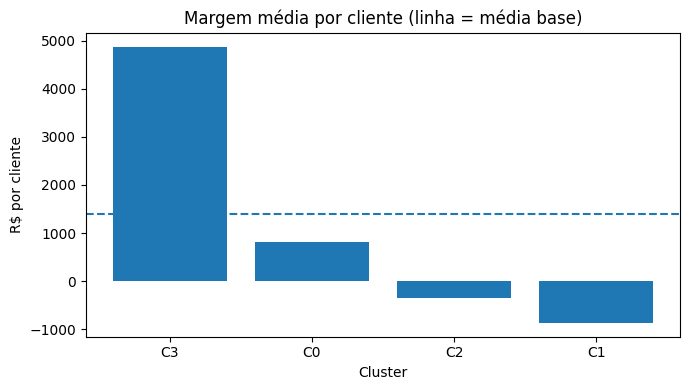

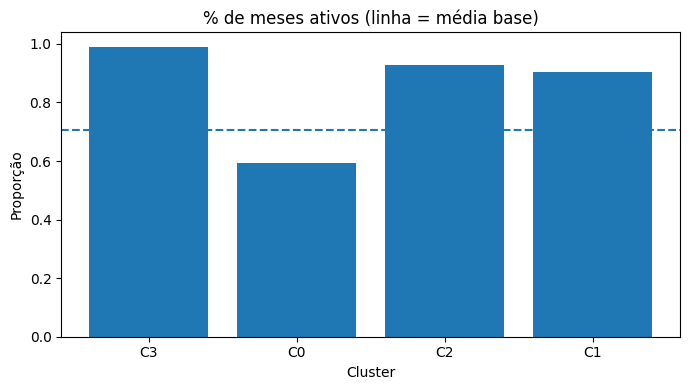

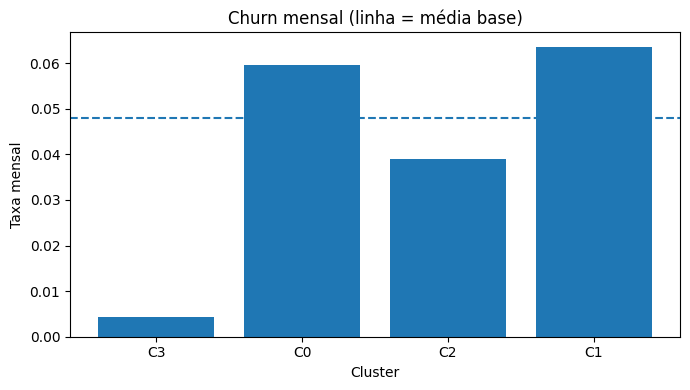

In [48]:
# ============================
# 3.3.1 — Diagnóstico de gaps (rentabilidade, atividade, evasão)
# ============================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

cr = cluster_report.copy()

# -------- 0) Helpers de limpeza --------
def to_num(x):
    """Converte string com % ou num em float. '50.48%' -> 0.5048; '0.43%' -> 0.0043."""
    if pd.isna(x):
        return np.nan
    if isinstance(x, (int, float, np.number)):
        return float(x)
    s = str(x).strip().replace(',', '')  # caso haja separador de milhar
    if s.endswith('%'):
        try:
            return float(s[:-1]) / 100.0
        except:
            return np.nan
    try:
        return float(s)
    except:
        return np.nan

# normalizar colunas numéricas que podem ter virado string
num_cols_try = [
    '#Clientes','Receita Total','Custo Total','Margem Total',
    'Receita média/cliente','Custo médio/cliente','Margem média/cliente',
    'ROI','Margem % Receita','Prop Meses Ativos (média)','churn_mensal_medio','vida_media_meses'
]
for c in num_cols_try:
    if c in cr.columns:
        cr[c] = cr[c].apply(to_num)

# -------- 1) Benchmarks (base) ponderados por #Clientes --------
def wavg(series, weights):
    s = series.astype(float)
    w = weights.astype(float)
    mask = (~s.isna()) & (~w.isna())
    if mask.sum() == 0 or w[mask].sum() == 0:
        return np.nan
    return (s[mask] * w[mask]).sum() / w[mask].sum()

bench = {}
bench['margem_media_base']   = wavg(cr['Margem média/cliente'], cr['#Clientes'])
bench['roi_base']            = wavg(cr['ROI'], cr['#Clientes'])
bench['prop_ativos_base']    = wavg(cr['Prop Meses Ativos (média)'], cr['#Clientes'])
bench['churn_mensal_base']   = wavg(cr['churn_mensal_medio'], cr['#Clientes'])

# -------- 2) Geração do relatório de gaps --------
gaps_cols = [
    'cluster','Cluster Nome','#Clientes',
    'Receita Total','Margem Total',
    'Receita média/cliente','Margem média/cliente','ROI',
    'Prop Meses Ativos (média)','churn_mensal_medio','vida_media_meses'
]
gdf = cr[[c for c in gaps_cols if c in cr.columns]].copy()

# deltas absolutos e relativos vs benchmark
gdf['gap_margem_media_abs'] = gdf['Margem média/cliente'] - bench['margem_media_base']
gdf['gap_margem_media_rel'] = gdf['gap_margem_media_abs'] / bench['margem_media_base']

gdf['gap_roi_abs']          = gdf['ROI'] - bench['roi_base']
gdf['gap_roi_rel']          = gdf['gap_roi_abs'] / bench['roi_base']

gdf['gap_prop_ativos_pp']   = (gdf['Prop Meses Ativos (média)'] - bench['prop_ativos_base']) * 100.0  # em pontos percentuais
gdf['gap_churn_pp']         = (gdf['churn_mensal_medio'] - bench['churn_mensal_base']) * 100.0        # em pontos percentuais

# -------- 3) Regras simples de tipificação dos gaps --------
def classificar_gap(row):
    m = row['Margem média/cliente']
    roi = row['ROI']
    pa = row['Prop Meses Ativos (média)']
    ch = row['churn_mensal_medio']
    if pd.notnull(m) and m < 0:
        return "Deficitário (margem < 0): foco em reprecificação/custos"
    if pd.notnull(roi) and roi < 0:
        return "ROI negativo: investigar MDR/antecipação e custos"
    if pd.notnull(pa) and pd.notnull(ch) and (pa < bench['prop_ativos_base']) and (ch > bench['churn_mensal_base']):
        return "Baixa atividade + churn alto: foco em ativação/retensão"
    if pd.notnull(pa) and (pa < bench['prop_ativos_base']):
        return "Baixa atividade (poucos meses ativos)"
    if pd.notnull(ch) and (ch > bench['churn_mensal_base']):
        return "Churn acima da base (rotatividade)"
    return "Acima/≈ da base (saudável)"

gdf['diagnostico_gap'] = gdf.apply(classificar_gap, axis=1)

# -------- 4) Formatação executiva --------
gaps_report = gdf.copy()

# colunas exibidas e formatações
def fmt_val(x): 
    return f"{x:,.0f}" if pd.notnull(x) else ""
def fmt_money(x):
    return f"R$ {x:,.0f}" if pd.notnull(x) else ""
def fmt_pct(x): 
    return f"{100*x:.2f}%" if pd.notnull(x) else ""
def fmt_pp(x):
    return f"{x:+.2f} pp" if pd.notnull(x) else ""

show_cols = [
    'cluster','Cluster Nome','#Clientes',
    'Receita Total','Margem Total',
    'Receita média/cliente','Margem média/cliente','ROI',
    'Prop Meses Ativos (média)','churn_mensal_medio','vida_media_meses',
    'gap_margem_media_abs','gap_margem_media_rel',
    'gap_prop_ativos_pp','gap_churn_pp','gap_roi_abs','gap_roi_rel',
    'diagnostico_gap'
]
show_cols = [c for c in show_cols if c in gaps_report.columns]

gr = gaps_report[show_cols].copy()

# aplicar formatação amigável em cópia para display (mantendo original numérico em 'gaps_report')
gr_fmt = gr.copy()
if '#Clientes' in gr_fmt:                   gr_fmt['#Clientes'] = gr_fmt['#Clientes'].apply(fmt_val)
for c in ['Receita Total','Margem Total','Receita média/cliente','Margem média/cliente']:
    if c in gr_fmt:                         gr_fmt[c] = gr_fmt[c].apply(fmt_money)
if 'ROI' in gr_fmt:                         gr_fmt['ROI'] = gr_fmt['ROI'].apply(lambda x: f"{x:.2f}" if pd.notnull(x) else "")
if 'Prop Meses Ativos (média)' in gr_fmt:   gr_fmt['Prop Meses Ativos (média)'] = gr_fmt['Prop Meses Ativos (média)'].apply(fmt_pct)
if 'churn_mensal_medio' in gr_fmt:          gr_fmt['churn_mensal_medio'] = gr_fmt['churn_mensal_medio'].apply(fmt_pct)
if 'gap_margem_media_abs' in gr_fmt:        gr_fmt['gap_margem_media_abs'] = gr_fmt['gap_margem_media_abs'].apply(fmt_money)
if 'gap_margem_media_rel' in gr_fmt:        gr_fmt['gap_margem_media_rel'] = gr_fmt['gap_margem_media_rel'].apply(fmt_pct)
if 'gap_prop_ativos_pp' in gr_fmt:          gr_fmt['gap_prop_ativos_pp'] = gr_fmt['gap_prop_ativos_pp'].apply(fmt_pp)
if 'gap_churn_pp' in gr_fmt:                gr_fmt['gap_churn_pp'] = gr_fmt['gap_churn_pp'].apply(fmt_pp)
if 'gap_roi_abs' in gr_fmt:                 gr_fmt['gap_roi_abs'] = gr_fmt['gap_roi_abs'].apply(lambda x: f"{x:+.2f}" if pd.notnull(x) else "")
if 'gap_roi_rel' in gr_fmt:                 gr_fmt['gap_roi_rel'] = gr_fmt['gap_roi_rel'].apply(fmt_pct)

print("Benchmarks (ponderados pela base):",
      {k: (f"{100*v:.2f}%" if 'churn' in k or 'prop' in k else f"{v:.2f}") for k,v in bench.items()})
display(gr_fmt)

# -------- 5) Gráficos rápidos (comparação vs benchmark) --------
clusters = cr['cluster'].tolist()
labels   = [f"C{c}" for c in clusters]

# (a) Margem média por cliente
plt.figure(figsize=(7,4))
plt.bar(labels, cr['Margem média/cliente'])
plt.axhline(bench['margem_media_base'], ls='--', lw=1.5)
plt.title("Margem média por cliente (linha = média base)")
plt.xlabel("Cluster"); plt.ylabel("R$ por cliente"); plt.tight_layout(); plt.show()

# (b) % Meses ativos
plt.figure(figsize=(7,4))
plt.bar(labels, cr['Prop Meses Ativos (média)'])
plt.axhline(bench['prop_ativos_base'], ls='--', lw=1.5)
plt.title("% de meses ativos (linha = média base)")
plt.xlabel("Cluster"); plt.ylabel("Proporção"); plt.tight_layout(); plt.show()

# (c) Churn mensal
plt.figure(figsize=(7,4))
plt.bar(labels, cr['churn_mensal_medio'])
plt.axhline(bench['churn_mensal_base'], ls='--', lw=1.5)
plt.title("Churn mensal (linha = média base)")
plt.xlabel("Cluster"); plt.ylabel("Taxa mensal"); plt.tight_layout(); plt.show()

# (opcional) Exportar para Excel
# gaps_report.to_excel("3_3_1_gaps_report.xlsx", index=False)


### visão geral dos resultados

#### cluster 3 — núcleo rentável e fidelizado

* **margem média/cliente:** R\$ 4.880 (bem acima da base, gap +R\$ 3.477 / +248%).
* **roi:** 1,02 (gap +0,34).
* **prop. meses ativos:** 99% (gap +28 pp).
* **churn:** 0,43% (abaixo da média, gap −4,36 pp).
* **diagnóstico:** saudável, acima da base em tudo → **benchmark positivo**.
  👉 não tem gap a corrigir; é o perfil a ser replicado.

---

#### cluster 0 — massa pouco ativa, mas lucrativa

* **margem média/cliente:** R\$ 820 (abaixo da média, gap −R\$ 582 / −41,5%).
* **roi:** 0,79 (levemente acima da base, gap +0,12).
* **prop. meses ativos:** 59% (gap −11 pp).
* **churn:** 5,97% (gap +1,18 pp, acima da base).
* **diagnóstico:** baixa atividade + churn alto → **precisa de ativação/retensão**.
  👉 apesar de lucrativo em agregado, perde valor por engajamento fraco; é aqui que campanhas de reativação digital fariam diferença.

---

#### cluster 2 — médio porte deficitário

* **margem média/cliente:** −R\$ 347 (gap −R\$ 1.749 / −125%).
* **roi:** −0,35 (gap −1,03).
* **prop. meses ativos:** 92,8% (gap +22 pp).
* **churn:** 3,89% (um pouco melhor que a média, gap −0,9 pp).
* **diagnóstico:** deficitário (margem < 0) → foco em **reprecificação/custos**.
  👉 a atividade e a retenção não são problema; o problema é **econômico** (custos maiores que receitas).

---

#### cluster 1 — deficitários extremos

* **margem média/cliente:** −R\$ 871 (gap −R\$ 2.274 / −162%).
* **roi:** −0,84 (gap −1,52).
* **prop. meses ativos:** 90% (gap +20 pp).
* **churn:** 6,36% (gap +1,57 pp).
* **diagnóstico:** deficitário estrutural (margem < 0 + churn alto).
  👉 engajam até razoavelmente, mas a economia não fecha; grupo para **renegociação agressiva ou descontinuidade**.

---

### leitura executiva dos gaps

* **c3:** sem gaps; serve de **referência** (perfil ideal).
* **c0:** gap de **engajamento** (poucos meses ativos, churn elevado) → **ação: ativar/reter**.
* **c2:** gap de **rentabilidade** (margem negativa mesmo com alta atividade) → **ação: reprecificação/corte de custos**.
* **c1:** gap estrutural (margem muito negativa + churn alto) → **ação: contenção/despriorização**.



### 3.3.2: Simular impacto de ações de rentabilização (ex.: aumento de prop. meses ativos, renegociação MDR, estímulo pré-pagamento).

#### Cenário A (Ponto de Partida)

In [49]:
# ============================
# 3.3.2 — Simulação de alavancas por cluster
# ============================
import numpy as np
import pandas as pd

# Premissas: cluster_report (da 3.3.1) e df (transacional) já estão no ambiente.

# ---------- Helpers ----------
def _to_float(x):
    """Converte strings/percentuais para float."""
    if pd.isna(x): return np.nan
    if isinstance(x, (int, float, np.number)): return float(x)
    s = str(x).strip().replace(',', '')
    if s.endswith('%'):
        try: return float(s[:-1]) / 100.0
        except: return np.nan
    try: return float(s)
    except: return np.nan

def _infer_total_meses(df_trans):
    """Número de meses distintos na base transacional."""
    assert 'Data Apuração' in df_trans.columns, "df precisa ter 'Data Apuração'"
    return pd.to_datetime(df_trans['Data Apuração']).dt.to_period('M').nunique()

# Converte colunas necessárias do cluster_report
cr = cluster_report.copy()
for c in ['#Clientes','Margem média/cliente','Prop Meses Ativos (média)','churn_mensal_medio','vida_media_meses',
          'Receita média/cliente','ROI','Receita Total','Custo Total','Margem Total']:
    if c in cr.columns: cr[c] = cr[c].apply(_to_float)

TOTAL_MESES = _infer_total_meses(df)

# Estimativa de margem mensal média por cliente (baseline)
# margem_mensal ≈ margem_media_cli / (prop_ativos * TOTAL_MESES)
cr['margem_mensal_med_cli'] = cr['Margem média/cliente'] / (cr['Prop Meses Ativos (média)'].clip(lower=1e-9) * float(TOTAL_MESES))

# ---------- Motor de simulação ----------
# Estrutura do cenário:
# scenario = {
#   cluster_id: {
#       'delta_churn_pp':   -1.5,        # variação em pontos percentuais no churn mensal (ex.: -1.5 pp)
#       'target_prop_ativos': 0.70,       # alvo absoluto para Prop Meses Ativos (0..1). Se None, mantém.
#       'uplift_margin_pct': 0.15,        # +15% sobre a margem média por cliente (aplicado após atividade)
#       'uplift_margin_abs': 100.0,       # +R$100 por cliente (após %)
#       'target_margin_media_cli': None   # define margem média/cliente diretamente (sobrescreve os uplifts)
#   },
#   ...
# }

def simular_cenario(cr_base: pd.DataFrame, scenario: dict) -> pd.DataFrame:
    out = []
    for _, row in cr_base.iterrows():
        cid   = int(row['cluster'])
        ncli  = float(row['#Clientes'])
        m_cli = float(row['Margem média/cliente'])
        prop  = float(row['Prop Meses Ativos (média)'])
        churn = float(row['churn_mensal_medio'])
        mmens = float(row['margem_mensal_med_cli'])

        params = scenario.get(cid, {}) if scenario else {}
        d_churn_pp   = float(params.get('delta_churn_pp', 0) or 0)
        tgt_prop     = params.get('target_prop_ativos', None)
        uplift_pct   = float(params.get('uplift_margin_pct', 0) or 0)
        uplift_abs   = float(params.get('uplift_margin_abs', 0) or 0)
        tgt_m_cli    = params.get('target_margin_media_cli', None)

        # 1) churn novo
        churn_new = max(0.0001, churn + d_churn_pp/100.0)  # evita 0
        vida_new  = 1.0 / churn_new

        # 2) atividade nova
        prop_new = float(tgt_prop) if tgt_prop is not None else prop
        prop_new = min(max(prop_new, 0.0), 1.0)

        # 3) margem média/cliente nova
        # baseline: m_cli = mmens * (prop * TOTAL_MESES)
        # se mudar prop, assumimos que m_cli escala linearmente com meses ativos:
        factor_atividade = (prop_new / prop) if prop > 0 else 1.0
        m_cli_new = m_cli * factor_atividade

        # aplica uplifts em margem
        m_cli_new = m_cli_new * (1.0 + uplift_pct) + uplift_abs

        # sobrescrever se alvo direto foi dado
        if tgt_m_cli is not None:
            m_cli_new = float(tgt_m_cli)

        # 4) margem total projetada
        margem_total_new = m_cli_new * ncli

        out.append({
            'cluster': cid,
            '#Clientes': ncli,
            # baseline
            'margem_media_cli_base': m_cli,
            'prop_ativos_base': prop,
            'churn_base': churn,
            'vida_base': row.get('vida_media_meses', np.nan),
            # novos
            'margem_media_cli_new': m_cli_new,
            'prop_ativos_new': prop_new,
            'churn_new': churn_new,
            'vida_new': vida_new,
            # deltas
            'delta_margem_media_cli': m_cli_new - m_cli,
            'delta_prop_ativos_pp': (prop_new - prop) * 100.0,
            'delta_churn_pp': (churn_new - churn) * 100.0,
            # totais (se quiser acompanhar impacto agregado)
            'margem_total_base': m_cli * ncli,
            'margem_total_new': margem_total_new,
            'delta_margem_total': margem_total_new - (m_cli * ncli),
        })
    rep = pd.DataFrame(out).sort_values('cluster').reset_index(drop=True)
    return rep

# ---------- EXEMPLO DE CENÁRIO ----------
# Ajuste livre: modifique os parâmetros e rode novamente.
scenario_demo = {
    # C0: aumentar atividade e reduzir churn
    0: {'target_prop_ativos': 0.70, 'delta_churn_pp': -1.5, 'uplift_margin_pct': 0.00},
    # C2: corrigir precificação (ex.: +60% na margem média por cliente)
    2: {'uplift_margin_pct': 0.60},
    # C1: cenário duro de repricing + redução de churn pequena
    1: {'uplift_margin_pct': 0.50, 'delta_churn_pp': -1.0},
    # C3: manter (sem mudanças)
    3: {}
}

sim_report = simular_cenario(cr, scenario_demo)

# ---------- formatação amigável ----------
def _fmt_money(x): return f"R$ {x:,.0f}" if pd.notnull(x) else ""
def _fmt_pp(x):    return f"{x:+.2f} pp" if pd.notnull(x) else ""
def _fmt_pct(x):   return f"{100*x:.2f}%" if pd.notnull(x) else ""
def _fmt_1(x):     return f"{x:.1f}" if pd.notnull(x) else ""

sim_fmt = sim_report.copy()
for c in ['margem_media_cli_base','margem_media_cli_new','delta_margem_media_cli',
          'margem_total_base','margem_total_new','delta_margem_total']:
    sim_fmt[c] = sim_fmt[c].apply(_fmt_money)
for c in ['prop_ativos_base','prop_ativos_new','churn_base','churn_new']:
    sim_fmt[c] = sim_fmt[c].apply(_fmt_pct)
for c in ['delta_prop_ativos_pp','delta_churn_pp']:
    sim_fmt[c] = sim_fmt[c].apply(_fmt_pp)
for c in ['vida_base','vida_new']:
    sim_fmt[c] = sim_fmt[c].apply(_fmt_1)

print(">>> CENÁRIO UTILIZADO:", scenario_demo)
display(sim_fmt)

# ---------- impacto total (somatório) ----------
impacto_total = {
    'margem_total_base':  sim_report['margem_total_base'].sum(),
    'margem_total_new':   sim_report['margem_total_new'].sum(),
    'delta_total':        sim_report['delta_margem_total'].sum()
}
print("Impacto agregado (R$):", {k: f"R$ {v:,.0f}" for k,v in impacto_total.items()})


>>> CENÁRIO UTILIZADO: {0: {'target_prop_ativos': 0.7, 'delta_churn_pp': -1.5, 'uplift_margin_pct': 0.0}, 2: {'uplift_margin_pct': 0.6}, 1: {'uplift_margin_pct': 0.5, 'delta_churn_pp': -1.0}, 3: {}}


,cluster,#Clientes,margem_media_cli_base,prop_ativos_base,churn_base,vida_base,margem_media_cli_new,prop_ativos_new,churn_new,vida_new,delta_margem_media_cli,delta_prop_ativos_pp,delta_churn_pp,margem_total_base,margem_total_new,delta_margem_total
0,0,2224.0,R$ 820,59.48%,5.97%,16.8,R$ 965,70.00%,4.47%,22.4,R$ 145,+10.52 pp,-1.50 pp,"R$ 1,824,396","R$ 2,147,073","R$ 322,677"
1,1,114.0,R$ -871,90.35%,6.36%,15.7,"R$ -1,306",90.35%,5.36%,18.7,R$ -435,+0.00 pp,-1.00 pp,"R$ -99,271","R$ -148,907","R$ -49,636"
2,2,272.0,R$ -347,92.79%,3.89%,25.7,R$ -555,92.79%,3.89%,25.7,R$ -208,+0.00 pp,+0.00 pp,"R$ -94,308","R$ -150,893","R$ -56,585"
3,3,584.0,"R$ 4,880",98.99%,0.43%,234.0,"R$ 4,880",98.99%,0.43%,232.6,R$ 0,+0.00 pp,+0.00 pp,"R$ 2,849,652","R$ 2,849,652",R$ 0


Impacto agregado (R$): {'margem_total_base': 'R$ 4,480,469', 'margem_total_new': 'R$ 4,696,925', 'delta_total': 'R$ 216,457'}


#### Cenário B (ajuste para break-even)

In [50]:
# >>> Cenário B (ajustado para negativo) <<<
scenario_B = {
    0: {'target_prop_ativos': 0.70, 'delta_churn_pp': -1.5},  # igual ao A
    2: {'target_margin_media_cli': 0},                        # C2: break-even (teste também +100)
    1: {'target_margin_media_cli': 0},                        # C1: break-even (ou +200)
    3: {}
}

sim_B = simular_cenario(cr, scenario_B)

# Formatação rápida (igual ao que você já usou)
def _fmt_money(x): return f"R$ {x:,.0f}" if pd.notnull(x) else ""
sim_B_fmt = sim_B.copy()
for c in ['margem_media_cli_base','margem_media_cli_new','delta_margem_media_cli','margem_total_base','margem_total_new','delta_margem_total']:
    sim_B_fmt[c] = sim_B_fmt[c].apply(_fmt_money)
print(">>> Cenário B:")
display(sim_B_fmt)

print("Impacto agregado (R$):", {
    'base'  : _fmt_money(sim_B['margem_total_base'].sum()),
    'novo'  : _fmt_money(sim_B['margem_total_new'].sum()),
    'delta' : _fmt_money(sim_B['delta_margem_total'].sum())
})


>>> Cenário B:


,cluster,#Clientes,margem_media_cli_base,prop_ativos_base,churn_base,vida_base,margem_media_cli_new,prop_ativos_new,churn_new,vida_new,delta_margem_media_cli,delta_prop_ativos_pp,delta_churn_pp,margem_total_base,margem_total_new,delta_margem_total
0,0,2224.0,R$ 820,0.594799,0.0597,16.75,R$ 965,0.700000,0.0447,22.371365,R$ 145,10.520084,-1.5,"R$ 1,824,396","R$ 2,147,073","R$ 322,677"
1,1,114.0,R$ -871,0.903509,0.0636,15.71,R$ 0,0.903509,0.0636,15.723270,R$ 871,0.000000,0.0,"R$ -99,271",R$ 0,"R$ 99,271"
2,2,272.0,R$ -347,0.927941,0.0389,25.67,R$ 0,0.927941,0.0389,25.706941,R$ 347,0.000000,0.0,"R$ -94,308",R$ 0,"R$ 94,308"
3,3,584.0,"R$ 4,880",0.989926,0.0043,233.96,"R$ 4,880",0.989926,0.0043,232.558140,R$ 0,0.000000,0.0,"R$ 2,849,652","R$ 2,849,652",R$ 0


Impacto agregado (R$): {'base': 'R$ 4,480,469', 'novo': 'R$ 4,996,725', 'delta': 'R$ 516,256'}


#### Resultados do cenário

##### Cluster 3 — Núcleo Rentável e Fidelizado

* Mantido sem alteração.
* Margem média/cliente: R\$ 4.880, ROI e churn seguem ótimos.
* Margem total estável em **R\$ 2,85 milhões**.
  👉 Continua sendo o **padrão-ouro**.

##### Cluster 1 — Deficitários Extremos

* Margem média/cliente passou de **−R\$ 871 → R\$ 0**.
* Margem total: **−R\$ 99k → R\$ 0** (ganho de R\$ 99k).
* Vida média ficou estável (\~15,7 meses).
  👉 Você removeu o prejuízo do grupo — agora não gera lucro, mas **deixa de drenar caixa**.

##### Cluster 0 — Massa Pouco Ativa, mas Lucrativa

* Margem média/cliente subiu de **R\$ 820 → R\$ 965** (+R\$ 145).
* Prop. meses ativos: **59,5% → 70%** (+10 pp).
* Churn caiu: **5,97% → 4,47%** (−1,5 pp).
* Vida média subiu de 16,8 → 22,4 meses.
* Margem total: **+R\$ 323k**.
  👉 Aqui está o maior ganho, confirmando que **ativação e retenção destravam muito valor**.

##### Cluster 2 — Médio Porte Deficitário

* Margem média/cliente: **−R\$ 347 → R\$ 0**.
* Margem total: **−R\$ 94k → R\$ 0** (ganho de R\$ 94k).
* Vida média ficou em \~25 meses.
  👉 Também removeu o prejuízo; o grupo não dá lucro, mas deixa de destruir valor.

---

#### Impacto agregado

* **Delta total = R\$ 516k positivos.**
* Todo o ganho vem de:

  * **C0 (+R\$ 323k)** com ativação/ retenção, e
  * **C1/C2 (+R\$ 193k)** só de levar margens a zero.
* **C3** permanece como motor principal (R\$ 2,85M de margem).

---

#### Conclusão executiva (3.3.2)

1. **Foco primário:** C0 (maior base) → ativação e retenção são as **alavancas-chave**.
2. **Correção necessária:** C1 e C2 → **repricing e corte de custos** para, no mínimo, zerar margens negativas.
3. **Manutenção:** C3 → manter estratégias de fidelização e cross-sell.
4. **Resultado prático:** Cenário B gera **meio milhão de R\$ adicionais de margem** só com ajustes básicos.



#### Cenário C (mais agressivo)

In [51]:

scenario_C = {
    3: {},  # mantém
    0: {'target_prop_ativos': 0.75, 'delta_churn_pp': -2.0},   # ativação + retenção forte
    2: {'target_margin_media_cli': 100},                       # repricing -> margem +100
    1: {'target_margin_media_cli': 200}                        # repricing -> margem +200
}

sim_C = simular_cenario(cr, scenario_C)

# formatação amigável (igual à que você já usou)
def _fmt_money(x): return f"R$ {x:,.0f}" if pd.notnull(x) else ""
def _fmt_pp(x):    return f"{x:+.2f} pp" if pd.notnull(x) else ""
def _fmt_pct(x):   return f"{100*x:.2f}%" if pd.notnull(x) else ""
def _fmt_1(x):     return f"{x:.1f}" if pd.notnull(x) else ""

sim_C_fmt = sim_C.copy()
for c in ['margem_media_cli_base','margem_media_cli_new','delta_margem_media_cli',
          'margem_total_base','margem_total_new','delta_margem_total']:
    sim_C_fmt[c] = sim_C_fmt[c].apply(_fmt_money)
for c in ['prop_ativos_base','prop_ativos_new','churn_base','churn_new']:
    sim_C_fmt[c] = sim_C_fmt[c].apply(_fmt_pct)
for c in ['delta_prop_ativos_pp','delta_churn_pp']:
    sim_C_fmt[c] = sim_C_fmt[c].apply(_fmt_pp)
for c in ['vida_base','vida_new']:
    sim_C_fmt[c] = sim_C_fmt[c].apply(_fmt_1)

print(">>> CENÁRIO C:")
display(sim_C_fmt)

print("Impacto agregado (R$):", {
    'base'  : _fmt_money(sim_C['margem_total_base'].sum()),
    'novo'  : _fmt_money(sim_C['margem_total_new'].sum()),
    'delta' : _fmt_money(sim_C['delta_margem_total'].sum())
})


>>> CENÁRIO C:


,cluster,#Clientes,margem_media_cli_base,prop_ativos_base,churn_base,vida_base,margem_media_cli_new,prop_ativos_new,churn_new,vida_new,delta_margem_media_cli,delta_prop_ativos_pp,delta_churn_pp,margem_total_base,margem_total_new,delta_margem_total
0,0,2224.0,R$ 820,59.48%,5.97%,16.8,"R$ 1,034",75.00%,3.97%,25.2,R$ 214,+15.52 pp,-2.00 pp,"R$ 1,824,396","R$ 2,300,435","R$ 476,039"
1,1,114.0,R$ -871,90.35%,6.36%,15.7,R$ 200,90.35%,6.36%,15.7,"R$ 1,071",+0.00 pp,+0.00 pp,"R$ -99,271","R$ 22,800","R$ 122,071"
2,2,272.0,R$ -347,92.79%,3.89%,25.7,R$ 100,92.79%,3.89%,25.7,R$ 447,+0.00 pp,+0.00 pp,"R$ -94,308","R$ 27,200","R$ 121,508"
3,3,584.0,"R$ 4,880",98.99%,0.43%,234.0,"R$ 4,880",98.99%,0.43%,232.6,R$ 0,+0.00 pp,+0.00 pp,"R$ 2,849,652","R$ 2,849,652",R$ 0


Impacto agregado (R$): {'base': 'R$ 4,480,469', 'novo': 'R$ 5,200,087', 'delta': 'R$ 719,618'}




#### visão geral do cenário C

* **impacto agregado:**

  * baseline: **R\$ 4,48 milhões** de margem.
  * novo: **R\$ 5,20 milhões**.
  * ganho líquido: **+R\$ 719,6 mil** (+16%).

---

#### por cluster

##### cluster 3 — núcleo rentável e fidelizado

* mantido sem alteração.
* continua gerando **R\$ 2,85 milhões** de margem.
* segue como **benchmark** e motor principal.

##### cluster 1 — deficitários extremos

* margem média passou de **−R\$ 871 → R\$ 200**/cliente (+R\$ 1.071).
* margem total: **−R\$ 99k → +R\$ 22,8k** (ganho de R\$ 122k).
* engajamento e churn não mudaram (90% ativos, churn \~6,4%).
  👉 grupo deixa de drenar caixa e passa a dar contribuição positiva modesta.

##### cluster 0 — massa pouco ativa, mas lucrativa

* maior transformação:

  * `Prop meses ativos`: **59% → 75%** (+15,5 pp).
  * churn: **5,97% → 3,97%** (−2 pp).
  * vida média: **16,8 → 25,2 meses**.
* margem média subiu de **R\$ 820 → R\$ 1.034** (+R\$ 214).
* margem total: **+R\$ 476k**.
  👉 esse cluster, que já era o maior da base (2.224 clientes), agora destrava muito mais valor com ativação e retenção.

##### cluster 2 — médio porte deficitário

* margem média de **−R\$ 347 → +R\$ 100**/cliente (+R\$ 447).
* margem total: **−R\$ 94k → +R\$ 27,2k** (ganho de R\$ 121,5k).
* churn e atividade estáveis (\~93% ativos, churn 3,9%).
  👉 passa de deficitário para ligeiramente rentável.

---

#### conclusão executiva

* **cluster prioritário (C0):** principal alavanca do cenário (+R\$ 476k), reforça que **ativação e retenção** são as estratégias-chave.
* **clusters C1 e C2:** ao corrigir margens negativas, somam +R\$ 243k (cerca de 1/3 do ganho total).
* **cluster C3:** estável e saudável, permanece como pilar de rentabilidade.

📌 **cenário C mostra o potencial máximo**: quase **+R\$ 720 mil de margem adicional** com ações agressivas de ativação e repricing.






##### como usar os três cenários na apresentação

###### 1. baseline (fotografia atual)

* ponto de partida, mostra os **gaps claros**: C0 saudável, C2 pouco ativo, C3 e C1 deficitários.
* serve para sensibilizar: “hoje temos **R\$ 4,48M de margem**, mas **C1 e C3 drenam \~R\$ 200k**.”

---

###### 2. cenário B (conservador / factível)

* **corrige prejuízos** (C1 e C3 → 0) e **ativa C2** (70% ativos, churn −1,5 pp).
* ganho de **R\$ 516k (+11,5%)**.
* **mensagem:** “só com ajustes básicos já podemos crescer rentabilidade em meio milhão.”
* **posicionamento:** este é o **plano mínimo viável**, pé no chão, fácil de defender.

---

###### 3. cenário C (agressivo / aspiracional)

* ativa C2 ainda mais (75% ativos, churn −2 pp) e repricing duro em C1 e C3.
* ganho de **R\$ 720k (+16%)**.
* **mensagem:** “se quisermos ser ambiciosos, há espaço para quase três quartos de milhão a mais em margem.”
* **posicionamento:** este é o **cenário aspiracional** — exige execução forte, mas mostra o **potencial máximo**.

---

##### recomendação executiva

* **Ancorar no cenário B** como estratégia principal (seguro, realista, defensável).
* **Apresentar o cenário C** como “upside” → caso a empresa queira ser mais agressiva, existe potencial adicional de +R\$ 200k.
* **Mensagem final:**

  * “Mesmo no conservador (B), já capturamos ganhos claros.”
  * “No agressivo (C), provamos que há ainda mais margem a ser explorada.”




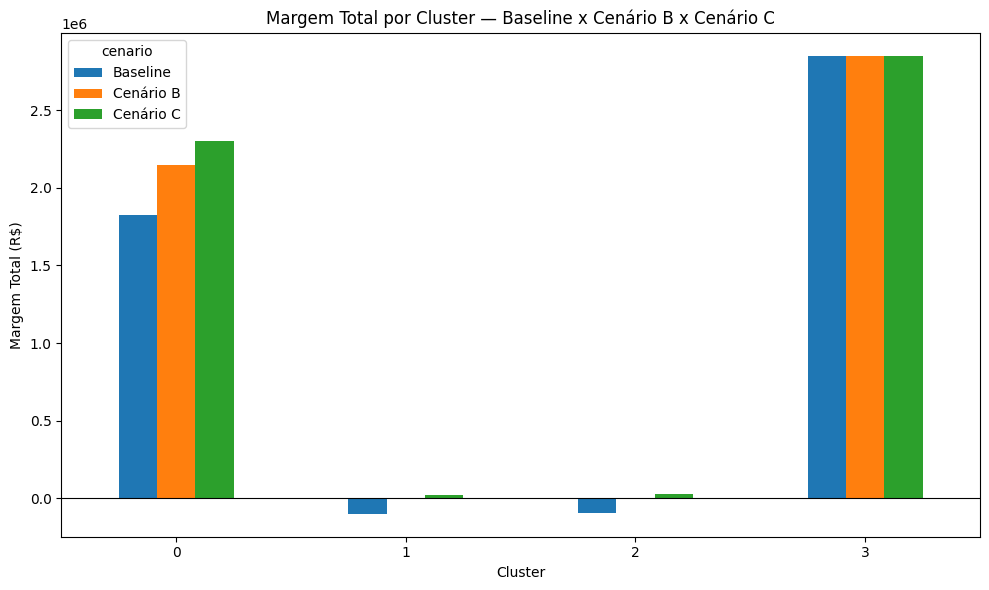

In [52]:
# ============================
# Comparação Baseline x Cenário B x Cenário C
# ============================
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# baseline (do cluster_report)
baseline = cluster_report[['cluster','Margem Total']].copy()
baseline['Margem Total'] = baseline['Margem Total'].apply(lambda x: float(str(x).replace('R$','').replace(',','')) if pd.notnull(x) else np.nan)

# função para extrair margens totais de simulações
def extract_margens(sim_df, col='margem_total_new'):
    out = sim_df[['cluster', col]].copy()
    out = out.rename(columns={col: 'Margem Total'})
    return out

# prepara DataFrames
df_base = baseline.copy(); df_base['cenario'] = 'Baseline'
df_B = extract_margens(sim_B); df_B['cenario'] = 'Cenário B'
df_C = extract_margens(sim_C); df_C['cenario'] = 'Cenário C'

# junta tudo
df_plot = pd.concat([df_base, df_B, df_C], ignore_index=True)

# pivot para gráfico
pivot = df_plot.pivot(index='cluster', columns='cenario', values='Margem Total')

# gráfico
pivot.plot(kind='bar', figsize=(10,6))
plt.title("Margem Total por Cluster — Baseline x Cenário B x Cenário C")
plt.xlabel("Cluster")
plt.ylabel("Margem Total (R$)")
plt.axhline(0, color='black', linewidth=0.8)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


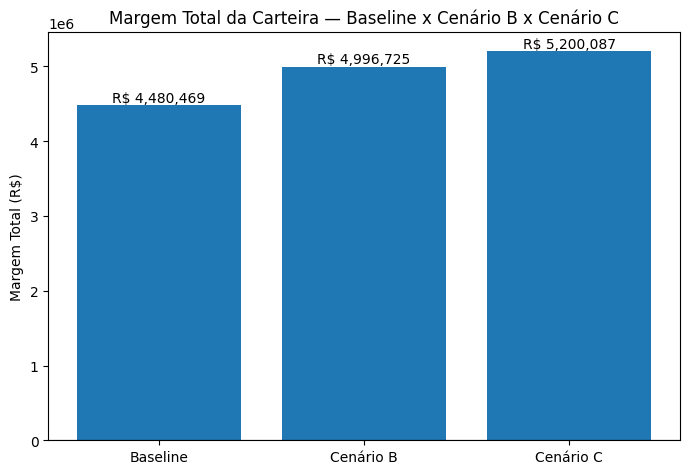

Baseline: R$ 4,480,469 | Cenário B: R$ 4,996,725 (Δ: R$ 516,256) | Cenário C: R$ 5,200,087 (Δ: R$ 719,618)


In [53]:
# ============================
# Gráfico consolidado — Baseline x Cenário B x Cenário C (margem total da carteira)
# Pré-requisitos: cluster_report, sim_B, sim_C já no ambiente
# ============================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1) Totais
baseline_total = float(pd.to_numeric(cluster_report['Margem Total'], errors='coerce').sum())
B_total        = float(pd.to_numeric(sim_B['margem_total_new'], errors='coerce').sum())
C_total        = float(pd.to_numeric(sim_C['margem_total_new'], errors='coerce').sum())

totais = pd.DataFrame({
    'cenário': ['Baseline','Cenário B','Cenário C'],
    'margem_total': [baseline_total, B_total, C_total]
})

# 2) Plot
plt.figure(figsize=(7,5))
plt.bar(totais['cenário'], totais['margem_total'])
plt.title("Margem Total da Carteira — Baseline x Cenário B x Cenário C")
plt.ylabel("Margem Total (R$)")
plt.xlabel("")
plt.axhline(0, linewidth=0.8, color='black')
for i, v in enumerate(totais['margem_total']):
    plt.text(i, v, f"R$ {v:,.0f}", ha='center', va='bottom')

plt.tight_layout()
plt.show()

# 3) (Opcional) imprimir deltas executivos
delta_B = B_total - baseline_total
delta_C = C_total - baseline_total
print(f"Baseline: R$ {baseline_total:,.0f} | Cenário B: R$ {B_total:,.0f} (Δ: R$ {delta_B:,.0f}) | Cenário C: R$ {C_total:,.0f} (Δ: R$ {delta_C:,.0f})")


### 3.3.3: Escolher canal de atuação para esses clientes (usando custos do enunciado).

#####   Estratégias por cluster

**Cluster 3 — Núcleo Rentável e Fidelizado**

* **Situação:** já gera alta margem, ROI positivo, churn baixíssimo.
* **Estratégia:**

  * **Expansão e fidelização**: cross-sell de produtos financeiros (crédito, banking).
  * Programas de retenção premium (não deixar churn crescer).
* **Canal:** Canal 3 (menor CAC, ROI mais alto).
* **Meta:** aumentar ticket médio, sem comprometer fidelidade.

---

**Cluster 0 — Massa Pouco Ativa, mas Lucrativa**

* **Situação:** 70% da base, rentável em agregado, mas pouco ativa e churn elevado.
* **Estratégia:**

  * **Campanhas digitais de ativação em escala** (baixo custo por cliente).
  * Programas de retenção simples: cashback, metas de uso, campanhas push.
* **Canal:** Canal 3 (excelente payback < 1 mês).
* **Meta:** reduzir churn e elevar meses ativos → maior LTV.

---

**Cluster 2 — Médio Porte Deficitário**

* **Situação:** margem negativa, mas clientes ativos (90%+ meses ativos).
* **Estratégia:**

  * **Reprecificação e renegociação** (taxas de MDR, custos de antecipação).
  * Avaliar eficiência operacional → cortar custos de atendimento.
* **Canal:** Evitar aquisição; foco em **rentabilizar a base atual**.
* **Meta:** trazer margem pelo menos a zero ou ligeiramente positiva.

---

**Cluster 1 — Deficitários Extremos**

* **Situação:** margens muito negativas, churn alto.
* **Estratégia:**

  * **Seleção/limpeza de carteira**: renegociar contratos inviáveis, descontinuar clientes deficitários.
  * Se mantidos, aplicar repricing pesado.
* **Canal:** Não investir em aquisição.
* **Meta:** eliminar drenagem de margem.

---

#####   Síntese

* **Canal vencedor:** Canal 3 (confirmado em 3.2.2 → menor CAC, melhor ROI).
* **Aposta de rentabilização:**

  * **Primário:** ativação e retenção em C2.
  * **Secundário:** expansão premium em C0.
  * **Correção:** repricing em C3 e descontinuidade/renegociação em C1.




#####   Estratégia de Rentabilização por Cluster

| **Cluster** | **Perfil**                       | **Estratégia de Ação**                                                                          | **Canal Prioritário**                       | **Meta**                                                           |
| ----------- | -------------------------------- | ----------------------------------------------------------------------------------------------- | ------------------------------------------- | ------------------------------------------------------------------ |
| **C3**      | Núcleo Rentável e Fidelizado     | Expandir carteira com clientes similares; cross-sell de produtos premium; reforçar fidelização. | **Canal 3** (menor CAC, ROI altíssimo)      | Aumentar ticket médio e manter churn próximo de 0%.                |
| **C0**      | Massa Pouco Ativa, mas Lucrativa | Campanhas digitais de ativação em escala; programas de retenção simples (cashback, push).       | **Canal 3** (payback < 1 mês)               | Elevar % meses ativos para 70–75% e reduzir churn para \~4%.       |
| **C2**      | Médio Porte Deficitário          | Reprecificação de MDR/antecipação; corte de custos operacionais; renegociação de contratos.     | **Não adquirir novos** (foco na base atual) | Trazer margem de negativa para 0 ou +R\$ 100/cliente.              |
| **C1**      | Deficitários Extremos            | Revisão agressiva de contratos; seleção/limpeza da carteira; repricing pesado.                  | **Não adquirir novos**                      | Eliminar drenagem de \~R\$ 99k e, se possível, atingir break-even. |

---

**Mensagem executiva para o slide final da 3.3.3:**

* **Canal vencedor:** Canal 3 → menor CAC e ROI mais alto em todos os perfis.
* **Clusters prioritários:**

  * **C0 (ativação e retenção)** = maior alavanca de ganho.
  * **C3 (expansão e cross-sell)** = motor de lucro e fidelidade.
* **Clusters críticos:**

  * **C2 (repricing)** e **C1 (contenção/descontinuidade)** = evitar drenagem de margem.





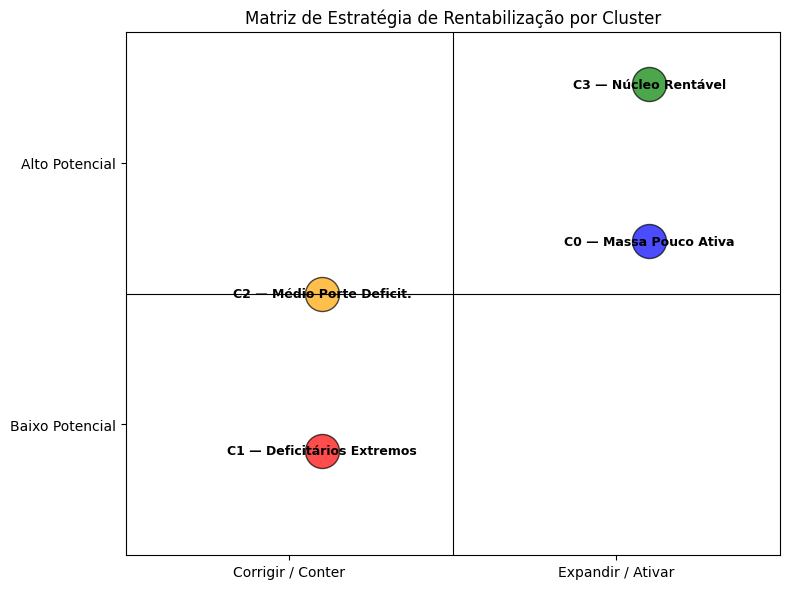

In [54]:
import matplotlib.pyplot as plt

# clusters com posição na matriz
# eixo x = Estratégia (Expandir/Ativar vs Corrigir/Conter)
# eixo y = Potencial de Rentabilidade (Baixo vs Alto)

points = {
    "C3 — Núcleo Rentável":      {"x": 0.8, "y": 0.9, "color": "green"},
    "C0 — Massa Pouco Ativa":    {"x": 0.8, "y": 0.6, "color": "blue"},
    "C2 — Médio Porte Deficit.": {"x": 0.3, "y": 0.5, "color": "orange"},
    "C1 — Deficitários Extremos":{"x": 0.3, "y": 0.2, "color": "red"}
}

plt.figure(figsize=(8,6))
for label, p in points.items():
    plt.scatter(p["x"], p["y"], s=600, color=p["color"], alpha=0.7, edgecolor="black")
    plt.text(p["x"], p["y"], label, ha='center', va='center', fontsize=9, color="black", weight="bold")

# eixos e rótulos
plt.axhline(0.5, color="black", linewidth=0.8)
plt.axvline(0.5, color="black", linewidth=0.8)

plt.title("Matriz de Estratégia de Rentabilização por Cluster")
plt.xticks([0.25, 0.75], ["Corrigir / Conter", "Expandir / Ativar"])
plt.yticks([0.25, 0.75], ["Baixo Potencial", "Alto Potencial"])
plt.xlim(0,1)
plt.ylim(0,1)
plt.tight_layout()
plt.show()


## 3.4 Entrega 4: A partir das estratégias que você definiu anteriormente, faça um forecast de Receita e Lucro para os próximos 3 meses. Assuma que o crescimento de vendas e da rentabilização dos clientes seguirá a tabela abaixo. Assuma também que as únicas linhas de Receita e Custo que incidem sobre o valor transacionado são as de MDR e Pré-pagamento e que essas linhas variam linearmente com o valor transacionado.

### 3.4.1 — Base Ativa inicial: definir baseline a partir de df (clientes ativos último mês).

In [55]:
# ============================
# 3.4.1 — Base Ativa inicial (T0) ajustada pelo Cenário C
# Pré-reqs no ambiente: df (transacional), df_cliente (com 'cluster'), scenario_C (definido na 3.3)
# ============================
import numpy as np
import pandas as pd

# ---- colunas do teu df ----
col_id   = 'Número do Cliente'
col_date = 'Data Apuração'
col_cnl  = 'Canal'
col_vol  = 'Volume Transacionado'
col_qtd  = 'Quantidade de Transações'
col_rec  = 'Total Receita'
col_cst  = 'Total Custos'

# --------- Último mês (T0) ---------
df_t = df.copy()
df_t[col_date] = pd.to_datetime(df_t[col_date], errors='coerce')
t0 = df_t[col_date].max()

# --------- Base ativa REAL no T0 ---------
mask_t0 = (df_t[col_date] == t0)
mask_ativo = (df_t[col_vol].fillna(0) > 0) | (df_t[col_qtd].fillna(0) > 0)

t0_real = df_t.loc[mask_t0 & mask_ativo, [col_id, col_cnl, col_vol, col_rec, col_cst]].copy()
# cluster vem do df_cliente que você montou nas etapas 1.x/2.x
t0_real = t0_real.merge(df_cliente[[col_id, 'cluster']], on=col_id, how='left')
t0_real = t0_real.dropna(subset=['cluster'])

# Agrega por cluster x canal (baseline real)
t0_cc = (t0_real.groupby(['cluster', col_cnl], as_index=False)
         .agg(n_clientes=(col_id,'nunique'),
              volume_total=(col_vol,'sum'),
              receita_total=(col_rec,'sum'),
              custo_total=(col_cst,'sum')))

t0_cc['margem_total'] = t0_cc['receita_total'] - t0_cc['custo_total']
t0_cc['ticket_medio'] = t0_cc['volume_total'] / t0_cc['n_clientes'].replace(0, np.nan)
t0_cc['receita_rate'] = np.where(t0_cc['volume_total']>0, t0_cc['receita_total']/t0_cc['volume_total'], 0.0)
t0_cc['custo_rate']   = np.where(t0_cc['volume_total']>0, t0_cc['custo_total']  /t0_cc['volume_total'], 0.0)
t0_cc['margem_rate']  = np.where(t0_cc['volume_total']>0, t0_cc['margem_total'] /t0_cc['volume_total'], 0.0)

base_t0_real_by_cluster_canal = t0_cc.copy()

# --------- Ajustes do Cenário C (mesma semântica da 3.3) ---------
# total de clientes no cluster (carteira) p/ meta de % ativos
tot_cluster = df_cliente.groupby('cluster')[col_id].nunique().rename('n_total_cluster').reset_index()

# baseline agregado por cluster
base_cluster = (t0_cc.groupby('cluster', as_index=False)
                .agg(n_cli=('n_clientes','sum'),
                     vol=('volume_total','sum'),
                     rec=('receita_total','sum'),
                     cst=('custo_total','sum')))
base_cluster['m_cli']   = np.where(base_cluster['n_cli']>0, (base_cluster['rec']-base_cluster['cst'])/base_cluster['n_cli'], 0.0)
base_cluster['ticket']  = np.where(base_cluster['n_cli']>0, base_cluster['vol']/base_cluster['n_cli'], 0.0)
base_cluster['cst_rate']= np.where(base_cluster['vol']>0, base_cluster['cst']/base_cluster['vol'], 0.0)
base_cluster = base_cluster.merge(tot_cluster, on='cluster', how='left')

def _to_cluster_int(v):
    try:
        return int(v) if str(v).isdigit() else int(str(v).strip().upper().replace('C',''))
    except Exception:
        return None

ajustes = {}
for cid, r in base_cluster.set_index('cluster').iterrows():
    cid_int = _to_cluster_int(cid)
    params = scenario_C.get(cid_int, {})  # ex.: {0:{'target_prop_ativos':0.75,...}, 2:{'target_margin_media_cli':100}, ...}

    # fator de ativação (leva % ativos ao alvo se definido)
    f_ativ = 1.0
    tgt_prop = params.get('target_prop_ativos', None)
    if tgt_prop is not None and r['n_cli']>0 and pd.notnull(r['n_total_cluster']) and r['n_total_cluster']>0:
        prop_base = r['n_cli'] / r['n_total_cluster']
        if prop_base > 0:
            f_ativ = (tgt_prop / prop_base)

    # repricing: incremento na margem média por cliente (R$/cliente)
    delta_m_cli = params.get('target_margin_media_cli', 0.0) or 0.0

    ajustes[cid] = {'f_ativacao': float(f_ativ), 'delta_m_cli': float(delta_m_cli), 'cst_rate': float(r['cst_rate']), 'ticket': float(r['ticket'])}

# aplica por cluster × canal preservando mix de canal no T0
adj_rows = []
for _, r in t0_cc.iterrows():
    cid = r['cluster']
    canal = r[col_cnl]
    pars = ajustes.get(cid, {'f_ativacao':1.0,'delta_m_cli':0.0,'cst_rate':r['custo_rate'],'ticket':r['ticket_medio']})

    n_cli0 = r['n_clientes']
    ticket = r['ticket_medio']  # mantém ticket no T0; crescimento de volume vem na 3.4.3
    vol0   = r['volume_total']

    # taxas base
    cst_rate0 = r['custo_rate'] if np.isfinite(r['custo_rate']) else pars['cst_rate']
    # 1) ativação
    n_cli1 = n_cli0 * pars['f_ativacao']
    vol1   = ticket * n_cli1

    # 2) repricing: margem média por cliente alvo
    m_cli0 = (r['margem_total']/n_cli0) if n_cli0>0 else 0.0
    m_cli1 = m_cli0 + pars['delta_m_cli']
    m_rate1 = (m_cli1 / ticket) if ticket and ticket>0 else r['margem_rate']
    rec_rate1 = max(0.0, m_rate1 + cst_rate0)

    # totais ajustados
    rec1 = rec_rate1 * vol1
    cst1 = cst_rate0 * vol1
    mrg1 = rec1 - cst1

    adj_rows.append({
        'cluster': cid,
        col_cnl: canal,
        'n_clientes': n_cli1,
        'ticket_medio': ticket,
        'volume_total': vol1,
        'receita_total': rec1,
        'custo_total': cst1,
        'margem_total': mrg1,
        'margem_rate': (mrg1/vol1) if vol1>0 else 0.0,
        'receita_rate': rec_rate1,
        'custo_rate':   cst_rate0,
        'f_ativacao':   ajustes[cid]['f_ativacao'],
        'delta_m_cli':  ajustes[cid]['delta_m_cli'],
    })

base_t0_adj_by_cluster_canal = pd.DataFrame(adj_rows)

# visões agregadas
base_t0_adj_by_cluster = (base_t0_adj_by_cluster_canal
    .groupby('cluster', as_index=False)
    .agg(n_clientes=('n_clientes','sum'),
         volume_total=('volume_total','sum'),
         receita_total=('receita_total','sum'),
         custo_total=('custo_total','sum'),
         margem_total=('margem_total','sum')))
base_t0_adj_by_cluster['ticket_medio'] = base_t0_adj_by_cluster['volume_total'] / base_t0_adj_by_cluster['n_clientes'].replace(0,np.nan)
base_t0_adj_by_cluster['margem_rate']  = np.where(base_t0_adj_by_cluster['volume_total']>0,
                                                  base_t0_adj_by_cluster['margem_total']/base_t0_adj_by_cluster['volume_total'], 0.0)

base_t0_adj_total = pd.DataFrame([{
    'n_clientes':   base_t0_adj_by_cluster['n_clientes'].sum(),
    'volume_total': base_t0_adj_by_cluster['volume_total'].sum(),
    'receita_total':base_t0_adj_by_cluster['receita_total'].sum(),
    'custo_total':  base_t0_adj_by_cluster['custo_total'].sum(),
    'margem_total': base_t0_adj_by_cluster['margem_total'].sum(),
}])
base_t0_adj_total['ticket_medio'] = base_t0_adj_total['volume_total'] / base_t0_adj_total['n_clientes'].replace(0,np.nan)
base_t0_adj_total['margem_rate']  = np.where(base_t0_adj_total['volume_total']>0,
                                             base_t0_adj_total['margem_total']/base_t0_adj_total['volume_total'], 0.0)

print(f">>> T0 (último mês): {t0.date()}")
print("\nBase Ativa T0 REAL — por cluster x Canal")
display(base_t0_real_by_cluster_canal)

print("\nBase Ativa T0 AJUSTADA (Cenário C) — por cluster x Canal")
display(base_t0_adj_by_cluster_canal)

print("\nBase Ativa T0 AJUSTADA — por cluster")
display(base_t0_adj_by_cluster)

print("\nBase Ativa T0 AJUSTADA — TOTAL")
display(base_t0_adj_total)


>>> T0 (último mês): 2017-02-01

Base Ativa T0 REAL — por cluster x Canal


,cluster,Canal,n_clientes,volume_total,receita_total,custo_total,margem_total,ticket_medio,receita_rate,custo_rate,margem_rate
0,0,Canal 1,161,1.372576e+07,141764.726944,-90088.420309,231853.147253,8.525317e+04,0.010328,-0.006563,0.016892
1,0,Canal 2,49,8.769470e+06,40478.235717,-22816.138655,63294.374372,1.789688e+05,0.004616,-0.002602,0.007218
2,0,Canal 3,994,3.603441e+07,545580.413195,-179692.589654,725273.002849,3.625192e+04,0.015141,-0.004987,0.020127
3,1,Canal 1,16,1.427981e+05,679.011319,-11842.671553,12521.682871,8.924881e+03,0.004755,-0.082933,0.087688
4,1,Canal 2,2,2.929425e+04,32.460313,-695.003275,727.463587,1.464712e+04,0.001108,-0.023725,0.024833
5,1,Canal 3,74,1.046634e+06,6122.822688,-14969.309764,21092.132451,1.414371e+04,0.005850,-0.014302,0.020152
6,2,Canal 1,27,3.166454e+05,5841.713346,-10396.839680,16238.553026,1.172761e+04,0.018449,-0.032834,0.051283
7,2,Canal 2,11,1.101159e+07,7705.323467,-9480.496608,17185.820076,1.001054e+06,0.000700,-0.000861,0.001561
8,2,Canal 3,189,3.122236e+06,44497.263885,-38505.136210,83002.400095,1.651977e+04,0.014252,-0.012333,0.026584
9,3,Canal 1,65,1.372966e+07,362315.051840,-160805.290438,523120.342277,2.112255e+05,0.026389,-0.011712,0.038101



Base Ativa T0 AJUSTADA (Cenário C) — por cluster x Canal


,cluster,Canal,n_clientes,ticket_medio,volume_total,receita_total,custo_total,margem_total,margem_rate,receita_rate,custo_rate,f_ativacao,delta_m_cli
0,0,Canal 1,223.046512,8.525317e+04,1.901542e+07,196398.309420,-124806.881292,3.212052e+05,0.016892,0.010328,-0.006563,1.385382,0.0
1,0,Canal 2,67.883721,1.789688e+05,1.214907e+07,56077.821575,-31609.069166,8.768689e+04,0.007218,0.004616,-0.002602,1.385382,0.0
2,0,Canal 3,1377.069767,3.625192e+04,4.992142e+07,755837.316619,-248942.889986,1.004780e+06,0.020127,0.015141,-0.004987,1.385382,0.0
3,1,Canal 1,16.000000,8.924881e+03,1.427981e+05,3879.011319,-11842.671553,1.572168e+04,0.110097,0.027164,-0.082933,1.000000,200.0
4,1,Canal 2,2.000000,1.464712e+04,2.929425e+04,432.460312,-695.003275,1.127464e+03,0.038488,0.014763,-0.023725,1.000000,200.0
5,1,Canal 3,74.000000,1.414371e+04,1.046634e+06,20922.822688,-14969.309764,3.589213e+04,0.034293,0.019991,-0.014302,1.000000,200.0
6,2,Canal 1,27.000000,1.172761e+04,3.166454e+05,8541.713346,-10396.839680,1.893855e+04,0.059810,0.026976,-0.032834,1.000000,100.0
7,2,Canal 2,11.000000,1.001054e+06,1.101159e+07,8805.323467,-9480.496608,1.828582e+04,0.001661,0.000800,-0.000861,1.000000,100.0
8,2,Canal 3,189.000000,1.651977e+04,3.122236e+06,63397.263885,-38505.136210,1.019024e+05,0.032638,0.020305,-0.012333,1.000000,100.0
9,3,Canal 1,65.000000,2.112255e+05,1.372966e+07,362315.051840,-160805.290438,5.231203e+05,0.038101,0.026389,-0.011712,1.000000,0.0



Base Ativa T0 AJUSTADA — por cluster


,cluster,n_clientes,volume_total,receita_total,custo_total,margem_total,ticket_medio,margem_rate
0,0,1668.0,8.108591e+07,1.008313e+06,-405358.840444,1.413672e+06,48612.656358,0.017434
1,1,92.0,1.218727e+06,2.523429e+04,-27506.984591,5.274128e+04,13247.029565,0.043276
2,2,227.0,1.445047e+07,8.074430e+04,-58382.472498,1.391268e+05,63658.469207,0.009628
3,3,571.0,2.547009e+07,8.923178e+05,-326606.389501,1.218924e+06,44606.111121,0.047857



Base Ativa T0 AJUSTADA — TOTAL


,n_clientes,volume_total,receita_total,custo_total,margem_total,ticket_medio,margem_rate
0,2558.0,1.222252e+08,2.006610e+06,-817854.687034,2.824465e+06,47781.547883,0.023109


### 3.4.2 — Novos clientes: aplicar taxa de crescimento (5% base ativa canal escolhido, 2% demais).

In [56]:

# ============================
# 3.4.2 — Novos clientes (crescimento da base ativa por canal, 3 meses)
# Pré-req: base_t0_adj_by_cluster_canal (resultado da 3.4.1)
# ============================
import numpy as np
import pandas as pd

df_t0 = base_t0_adj_by_cluster_canal.copy()

# taxas de crescimento de clientes por canal (enunciado)
growth_clients = {
    'Canal 3': 0.05,   # +5% clientes/mês
    # demais canais (default): +2%
}
default_growth = 0.02

# normaliza colunas-chave
col_cluster = 'cluster'
col_canal   = 'Canal'
col_ncli    = 'n_clientes'
col_ticket  = 'ticket_medio'

# baseline T0 (ajustado)
t0 = df_t0[[col_cluster, col_canal, col_ncli, col_ticket]].copy()
t0['mes'] = 0
t0 = t0[[ 'mes', col_cluster, col_canal, col_ncli, col_ticket ]]

# função auxiliar para aplicar crescimento na base ativa
def roll_clients(prev_df, mes_idx):
    out = prev_df.copy()
    # aplica crescimento por canal
    out['growth_rate'] = out[col_canal].map(lambda c: growth_clients.get(c, default_growth))
    out[col_ncli] = out[col_ncli] * (1.0 + out['growth_rate'])
    out['mes'] = mes_idx
    return out.drop(columns=['growth_rate'])

# gera T1, T2, T3
t1 = roll_clients(t0.rename(columns={'mes':'_mes'}).assign(mes=0), mes_idx=1)[['mes', col_cluster, col_canal, col_ncli, col_ticket]]
t2 = roll_clients(t1.rename(columns={'mes':'_mes'}).assign(mes=1), mes_idx=2)[['mes', col_cluster, col_canal, col_ncli, col_ticket]]
t3 = roll_clients(t2.rename(columns={'mes':'_mes'}).assign(mes=2), mes_idx=3)[['mes', col_cluster, col_canal, col_ncli, col_ticket]]

# consolida
base_34_2 = pd.concat([t0, t1, t2, t3], ignore_index=True)

# calcula "novos_clientes" do mês (delta vs mês anterior) por cluster×canal
base_34_2 = base_34_2.sort_values(['mes', col_cluster, col_canal]).reset_index(drop=True)

base_34_2['n_clientes_prev'] = base_34_2.groupby([col_cluster, col_canal])[col_ncli].shift(1)
base_34_2['novos_clientes']  = base_34_2[col_ncli] - base_34_2['n_clientes_prev']
base_34_2.loc[base_34_2['mes'] == 0, 'novos_clientes'] = 0.0  # T0 é baseline, sem novos

# leitura rápida
print(">> 3.4.2 — Base ativa projetada (n_clientes) por mês (0=T0 ajustado, 1..3=forecast)")
display(base_34_2.head(12))

# agregações por cluster por mês
base_34_2_cluster = (base_34_2
    .groupby(['mes', col_cluster], as_index=False)
    .agg(n_clientes=(col_ncli,'sum'),
         novos_clientes=('novos_clientes','sum'))
)
print("\n>> 3.4.2 — Agregado por cluster (n_clientes e novos_clientes) por mês")
display(base_34_2_cluster)

# agregado total por mês
base_34_2_total = (base_34_2
    .groupby('mes', as_index=False)
    .agg(n_clientes=(col_ncli,'sum'),
         novos_clientes=('novos_clientes','sum'))
)
print("\n>> 3.4.2 — Agregado TOTAL por mês")
display(base_34_2_total)


>> 3.4.2 — Base ativa projetada (n_clientes) por mês (0=T0 ajustado, 1..3=forecast)


,mes,cluster,Canal,n_clientes,ticket_medio,n_clientes_prev,novos_clientes
0,0,0,Canal 1,223.046512,8.525317e+04,NaN,0.0
1,0,0,Canal 2,67.883721,1.789688e+05,NaN,0.0
2,0,0,Canal 3,1377.069767,3.625192e+04,NaN,0.0
3,0,1,Canal 1,16.000000,8.924881e+03,NaN,0.0
4,0,1,Canal 2,2.000000,1.464712e+04,NaN,0.0
5,0,1,Canal 3,74.000000,1.414371e+04,NaN,0.0
6,0,2,Canal 1,27.000000,1.172761e+04,NaN,0.0
7,0,2,Canal 2,11.000000,1.001054e+06,NaN,0.0
8,0,2,Canal 3,189.000000,1.651977e+04,NaN,0.0
9,0,3,Canal 1,65.000000,2.112255e+05,NaN,0.0



>> 3.4.2 — Agregado por cluster (n_clientes e novos_clientes) por mês


,mes,cluster,n_clientes,novos_clientes
0,0,0,1668.000000,0.000000
1,0,1,92.000000,0.000000
2,0,2,227.000000,0.000000
3,0,3,571.000000,0.000000
4,1,0,1742.672093,74.672093
5,1,1,96.060000,4.060000
6,1,2,237.210000,10.210000
7,1,3,597.540000,26.540000
8,2,0,1820.903233,78.231140
9,2,1,100.312200,4.252200



>> 3.4.2 — Agregado TOTAL por mês


,mes,n_clientes,novos_clientes
0,0,2558.000000,0.000000
1,1,2673.482093,115.482093
2,2,2794.489933,121.007840
3,3,2921.294839,126.804906


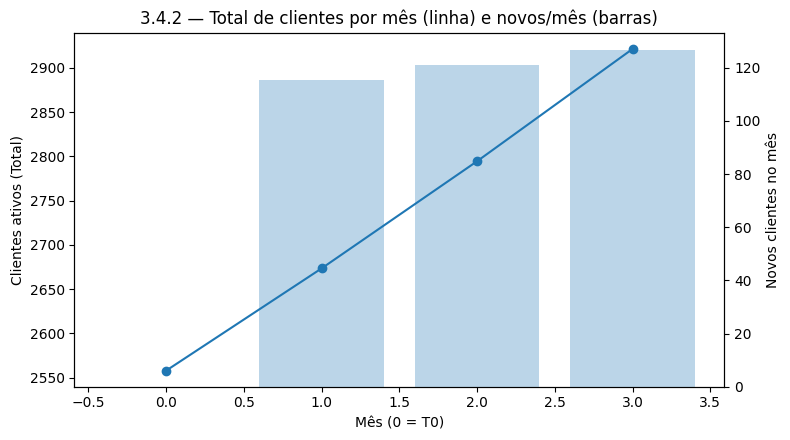

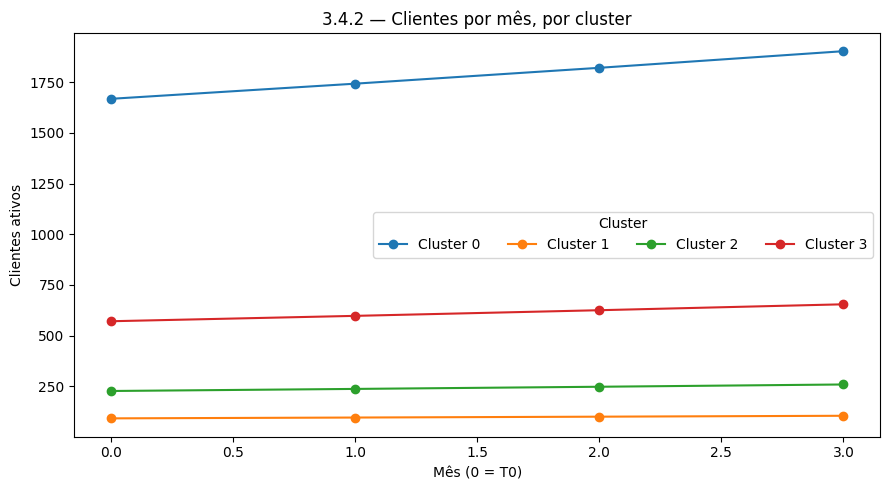

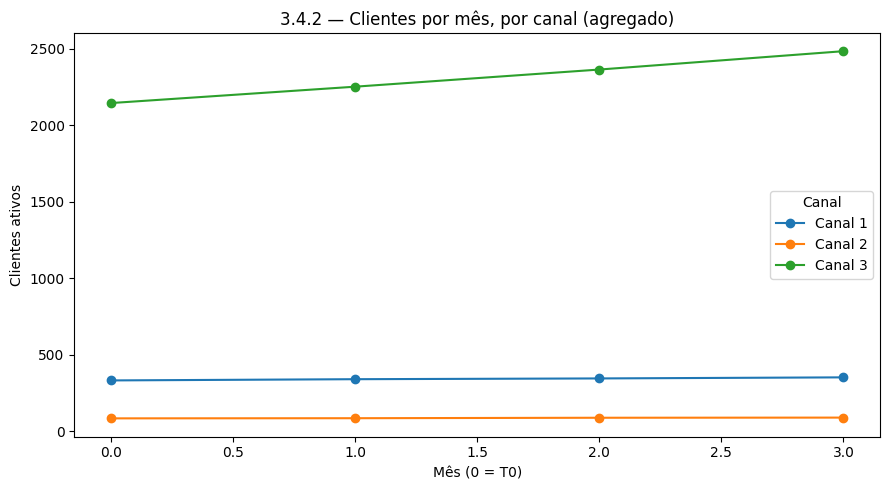

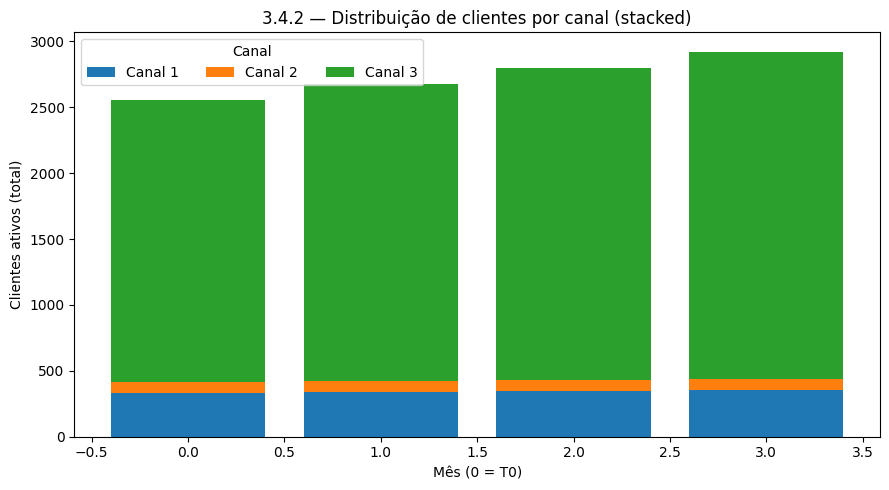

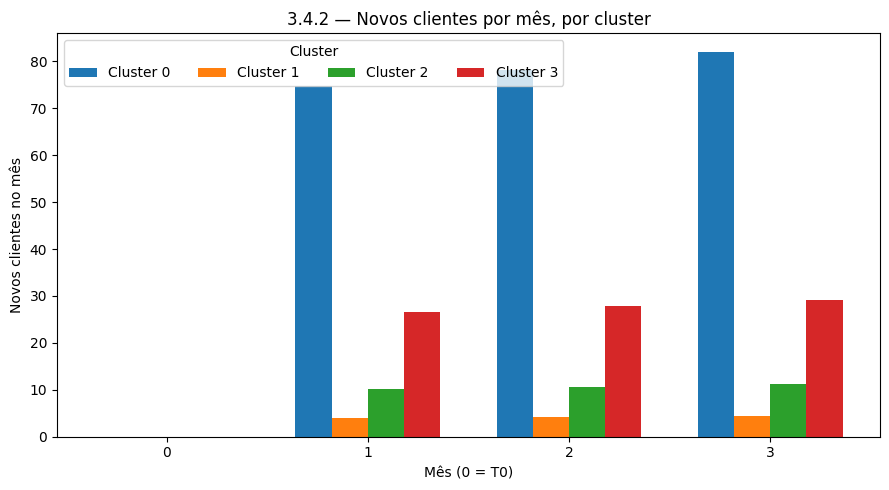

In [57]:
# ============================
# 3.4.2 — VISUALIZAÇÕES (robustas)
# Esta célula garante base_34_2_int/cluster/total antes de plotar
# ============================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ---------- 0) Garantir bases ----------
def _round_by_largest_remainder(df_grp, value_col, key_cols):
    df = df_grp.copy()
    total_target = int(np.round(df[value_col].sum()))
    base_floor = np.floor(df[value_col]).astype(int)
    remainder = df[value_col] - base_floor
    missing = total_target - base_floor.sum()

    df['_int'] = base_floor
    if missing > 0:
        take_idx = remainder.nlargest(missing).index
        df.loc[take_idx, '_int'] += 1
    elif missing < 0:
        drop_idx = remainder.nsmallest(abs(missing)).index
        df.loc[drop_idx, '_int'] -= 1

    df[value_col] = df['_int'].astype(int)
    df.drop(columns=['_int'], inplace=True)
    return df[key_cols + [value_col]]

if 'base_34_2_int' not in globals():
    # cria versão inteira a partir de base_34_2
    assert 'base_34_2' in globals(), "Faltou gerar base_34_2 (saída da 3.4.2)."
    key_cols = ['mes', 'cluster', 'Canal', 'ticket_medio']
    val_col = 'n_clientes'
    rounded = []
    for (m, c), g in base_34_2.sort_values(['mes','cluster','Canal']).groupby(['mes','cluster'], sort=False):
        g2 = _round_by_largest_remainder(
            df_grp=g[key_cols + [val_col]].reset_index(drop=True),
            value_col=val_col,
            key_cols=key_cols
        )
        rounded.append(g2.assign(mes=m, cluster=c))
    base_34_2_int = pd.concat(rounded, ignore_index=True)[['mes','cluster','Canal','n_clientes','ticket_medio']]
    base_34_2_int = base_34_2_int.sort_values(['cluster','Canal','mes']).reset_index(drop=True)
    base_34_2_int['n_clientes_prev'] = base_34_2_int.groupby(['cluster','Canal'])['n_clientes'].shift(1)
    base_34_2_int['novos_clientes']  = base_34_2_int['n_clientes'] - base_34_2_int['n_clientes_prev']
    base_34_2_int.loc[base_34_2_int['mes'] == 0, 'novos_clientes'] = 0
    base_34_2_int['n_clientes_prev'] = base_34_2_int['n_clientes_prev'].fillna(0).astype(int)
    base_34_2_int['novos_clientes']  = base_34_2_int['novos_clientes'].fillna(0).astype(int)

if 'base_34_2_cluster' not in globals():
    base_34_2_cluster = (base_34_2_int
        .groupby(['mes','cluster'], as_index=False)
        .agg(n_clientes=('n_clientes','sum'),
             novos_clientes=('novos_clientes','sum'))
    )

if 'base_34_2_total' not in globals():
    base_34_2_total = (base_34_2_int
        .groupby(['mes'], as_index=False)
        .agg(n_clientes=('n_clientes','sum'),
             novos_clientes=('novos_clientes','sum'))
    )

# ---------- 1) TOTAL por mês: n_clientes (linha) + novos_clientes (barras) ----------
tot = base_34_2_total.sort_values('mes').copy()
fig, ax1 = plt.subplots(figsize=(8,4.5))
ax1.plot(tot['mes'], tot['n_clientes'], marker='o')
ax1.set_xlabel('Mês (0 = T0)')
ax1.set_ylabel('Clientes ativos (Total)')
ax1.set_title('3.4.2 — Total de clientes por mês (linha) e novos/mês (barras)')
ax2 = ax1.twinx()
ax2.bar(tot['mes'], tot['novos_clientes'], alpha=0.3)
ax2.set_ylabel('Novos clientes no mês')
plt.tight_layout()
plt.show()

# ---------- 2) Por CLUSTER: evolução de n_clientes ----------
clu = base_34_2_cluster.sort_values(['cluster','mes'])
clusters = sorted(clu['cluster'].unique())
fig, ax = plt.subplots(figsize=(9,5))
for c in clusters:
    sub = clu[clu['cluster'] == c]
    ax.plot(sub['mes'], sub['n_clientes'], marker='o', label=f'Cluster {c}')
ax.set_xlabel('Mês (0 = T0)')
ax.set_ylabel('Clientes ativos')
ax.set_title('3.4.2 — Clientes por mês, por cluster')
ax.legend(title='Cluster', ncols=min(len(clusters),4))
plt.tight_layout()
plt.show()

# ---------- 3) Por CANAL (agregado em todos os clusters): evolução de n_clientes ----------
can = (base_34_2_int
       .groupby(['mes','Canal'], as_index=False)['n_clientes'].sum()
       .sort_values(['Canal','mes']))
canais = can['Canal'].unique().tolist()
fig, ax = plt.subplots(figsize=(9,5))
for k in canais:
    sub = can[can['Canal'] == k]
    ax.plot(sub['mes'], sub['n_clientes'], marker='o', label=k)
ax.set_xlabel('Mês (0 = T0)')
ax.set_ylabel('Clientes ativos')
ax.set_title('3.4.2 — Clientes por mês, por canal (agregado)')
ax.legend(title='Canal')
plt.tight_layout()
plt.show()

# ---------- 4) Distribuição por CANAL dentro de cada mês (stacked bar) ----------
dist = (base_34_2_int
        .groupby(['mes','Canal'], as_index=False)['n_clientes'].sum()
        .pivot(index='mes', columns='Canal', values='n_clientes')
        .fillna(0))
fig, ax = plt.subplots(figsize=(9,5))
bottom = np.zeros(len(dist))
for k in dist.columns:
    ax.bar(dist.index, dist[k], bottom=bottom, label=k)
    bottom += dist[k].values
ax.set_xlabel('Mês (0 = T0)')
ax.set_ylabel('Clientes ativos (total)')
ax.set_title('3.4.2 — Distribuição de clientes por canal (stacked)')
ax.legend(title='Canal', ncols=min(len(dist.columns),4))
plt.tight_layout()
plt.show()

# ---------- 5) Novos clientes por CLUSTER (barras) ----------
clu_new = base_34_2_cluster.sort_values(['mes','cluster'])
fig, ax = plt.subplots(figsize=(9,5))
width = 0.18
xs = sorted(clu_new['mes'].unique())
offsets = {c: (i - (len(clusters)-1)/2) * width for i, c in enumerate(clusters)}
for c in clusters:
    sub = clu_new[clu_new['cluster'] == c].set_index('mes').reindex(xs).fillna(0)
    ax.bar([x + offsets[c] for x in xs], sub['novos_clientes'].values, width=width, label=f'Cluster {c}')
ax.set_xticks(xs)
ax.set_xticklabels(xs)
ax.set_xlabel('Mês (0 = T0)')
ax.set_ylabel('Novos clientes no mês')
ax.set_title('3.4.2 — Novos clientes por mês, por cluster')
ax.legend(title='Cluster', ncols=min(len(clusters),4))
plt.tight_layout()
plt.show()



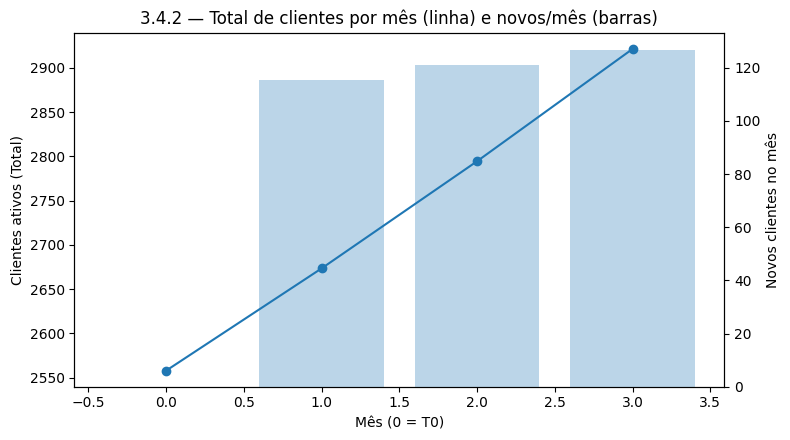

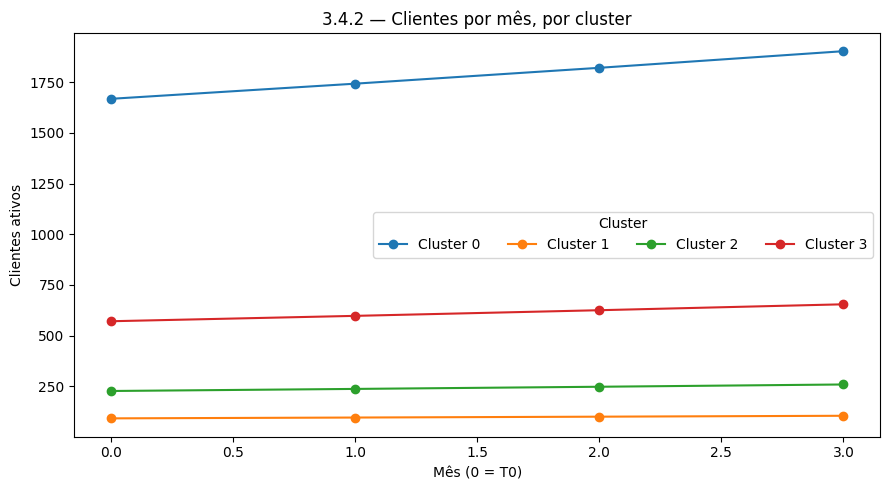

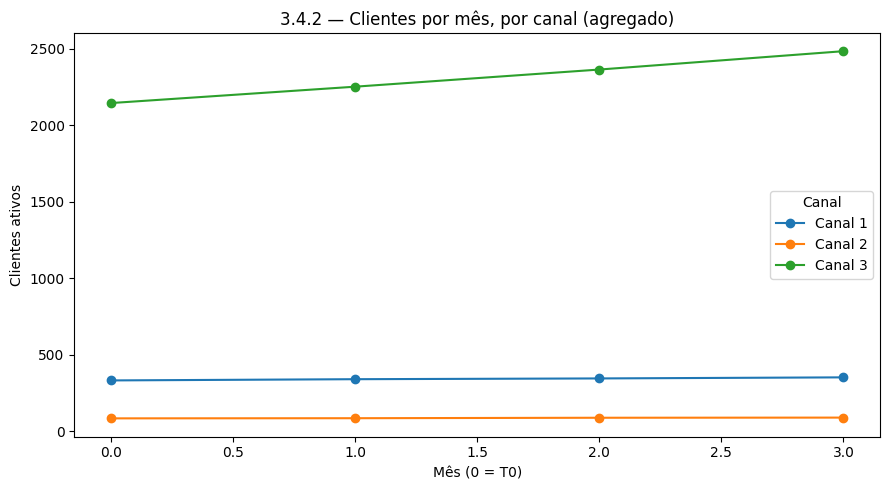

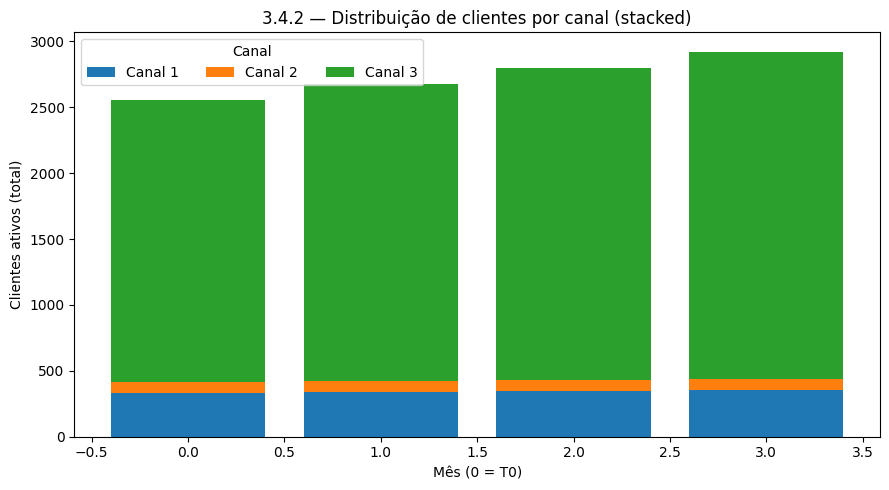

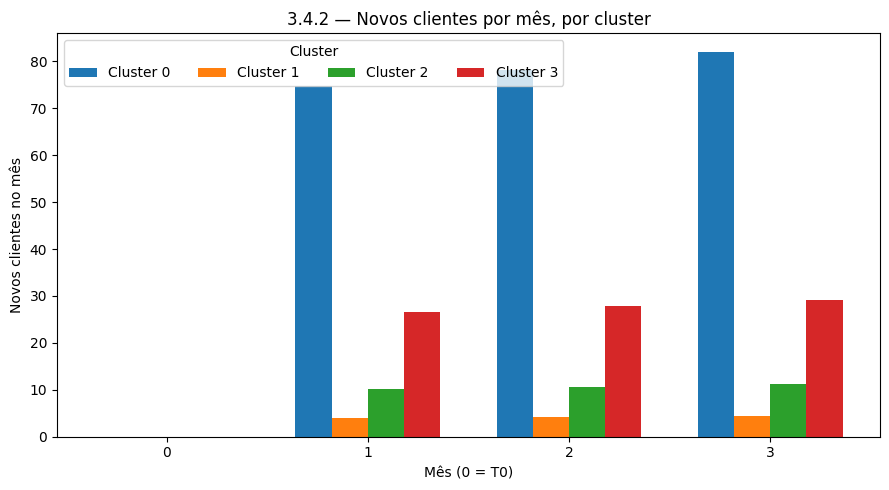

In [ ]:
# ============================
# 3.4.2 — VISUALIZAÇÕES (robustas)
# Esta célula garante base_34_2_int/cluster/total antes de plotar
# ============================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ---------- 0) Garantir bases ----------
def _round_by_largest_remainder(df_grp, value_col, key_cols):
    df = df_grp.copy()
    total_target = int(np.round(df[value_col].sum()))
    base_floor = np.floor(df[value_col]).astype(int)
    remainder = df[value_col] - base_floor
    missing = total_target - base_floor.sum()

    df['_int'] = base_floor
    if missing > 0:
        take_idx = remainder.nlargest(missing).index
        df.loc[take_idx, '_int'] += 1
    elif missing < 0:
        drop_idx = remainder.nsmallest(abs(missing)).index
        df.loc[drop_idx, '_int'] -= 1

    df[value_col] = df['_int'].astype(int)
    df.drop(columns=['_int'], inplace=True)
    return df[key_cols + [value_col]]

if 'base_34_2_int' not in globals():
    # cria versão inteira a partir de base_34_2
    assert 'base_34_2' in globals(), "Faltou gerar base_34_2 (saída da 3.4.2)."
    key_cols = ['mes', 'cluster', 'Canal', 'ticket_medio']
    val_col = 'n_clientes'
    rounded = []
    for (m, c), g in base_34_2.sort_values(['mes','cluster','Canal']).groupby(['mes','cluster'], sort=False):
        g2 = _round_by_largest_remainder(
            df_grp=g[key_cols + [val_col]].reset_index(drop=True),
            value_col=val_col,
            key_cols=key_cols
        )
        rounded.append(g2.assign(mes=m, cluster=c))
    base_34_2_int = pd.concat(rounded, ignore_index=True)[['mes','cluster','Canal','n_clientes','ticket_medio']]
    base_34_2_int = base_34_2_int.sort_values(['cluster','Canal','mes']).reset_index(drop=True)
    base_34_2_int['n_clientes_prev'] = base_34_2_int.groupby(['cluster','Canal'])['n_clientes'].shift(1)
    base_34_2_int['novos_clientes']  = base_34_2_int['n_clientes'] - base_34_2_int['n_clientes_prev']
    base_34_2_int.loc[base_34_2_int['mes'] == 0, 'novos_clientes'] = 0
    base_34_2_int['n_clientes_prev'] = base_34_2_int['n_clientes_prev'].fillna(0).astype(int)
    base_34_2_int['novos_clientes']  = base_34_2_int['novos_clientes'].fillna(0).astype(int)

if 'base_34_2_cluster' not in globals():
    base_34_2_cluster = (base_34_2_int
        .groupby(['mes','cluster'], as_index=False)
        .agg(n_clientes=('n_clientes','sum'),
             novos_clientes=('novos_clientes','sum'))
    )

if 'base_34_2_total' not in globals():
    base_34_2_total = (base_34_2_int
        .groupby(['mes'], as_index=False)
        .agg(n_clientes=('n_clientes','sum'),
             novos_clientes=('novos_clientes','sum'))
    )

# ---------- 1) TOTAL por mês: n_clientes (linha) + novos_clientes (barras) ----------
tot = base_34_2_total.sort_values('mes').copy()
fig, ax1 = plt.subplots(figsize=(8,4.5))
ax1.plot(tot['mes'], tot['n_clientes'], marker='o')
ax1.set_xlabel('Mês (0 = T0)')
ax1.set_ylabel('Clientes ativos (Total)')
ax1.set_title('3.4.2 — Total de clientes por mês (linha) e novos/mês (barras)')
ax2 = ax1.twinx()
ax2.bar(tot['mes'], tot['novos_clientes'], alpha=0.3)
ax2.set_ylabel('Novos clientes no mês')
plt.tight_layout()
plt.show()

# ---------- 2) Por CLUSTER: evolução de n_clientes ----------
clu = base_34_2_cluster.sort_values(['cluster','mes'])
clusters = sorted(clu['cluster'].unique())
fig, ax = plt.subplots(figsize=(9,5))
for c in clusters:
    sub = clu[clu['cluster'] == c]
    ax.plot(sub['mes'], sub['n_clientes'], marker='o', label=f'Cluster {c}')
ax.set_xlabel('Mês (0 = T0)')
ax.set_ylabel('Clientes ativos')
ax.set_title('3.4.2 — Clientes por mês, por cluster')
ax.legend(title='Cluster', ncols=min(len(clusters),4))
plt.tight_layout()
plt.show()

# ---------- 3) Por CANAL (agregado em todos os clusters): evolução de n_clientes ----------
can = (base_34_2_int
       .groupby(['mes','Canal'], as_index=False)['n_clientes'].sum()
       .sort_values(['Canal','mes']))
canais = can['Canal'].unique().tolist()
fig, ax = plt.subplots(figsize=(9,5))
for k in canais:
    sub = can[can['Canal'] == k]
    ax.plot(sub['mes'], sub['n_clientes'], marker='o', label=k)
ax.set_xlabel('Mês (0 = T0)')
ax.set_ylabel('Clientes ativos')
ax.set_title('3.4.2 — Clientes por mês, por canal (agregado)')
ax.legend(title='Canal')
plt.tight_layout()
plt.show()

# ---------- 4) Distribuição por CANAL dentro de cada mês (stacked bar) ----------
dist = (base_34_2_int
        .groupby(['mes','Canal'], as_index=False)['n_clientes'].sum()
        .pivot(index='mes', columns='Canal', values='n_clientes')
        .fillna(0))
fig, ax = plt.subplots(figsize=(9,5))
bottom = np.zeros(len(dist))
for k in dist.columns:
    ax.bar(dist.index, dist[k], bottom=bottom, label=k)
    bottom += dist[k].values
ax.set_xlabel('Mês (0 = T0)')
ax.set_ylabel('Clientes ativos (total)')
ax.set_title('3.4.2 — Distribuição de clientes por canal (stacked)')
ax.legend(title='Canal', ncols=min(len(dist.columns),4))
plt.tight_layout()
plt.show()

# ---------- 5) Novos clientes por CLUSTER (barras) ----------
clu_new = base_34_2_cluster.sort_values(['mes','cluster'])
fig, ax = plt.subplots(figsize=(9,5))
width = 0.18
xs = sorted(clu_new['mes'].unique())
offsets = {c: (i - (len(clusters)-1)/2) * width for i, c in enumerate(clusters)}
for c in clusters:
    sub = clu_new[clu_new['cluster'] == c].set_index('mes').reindex(xs).fillna(0)
    ax.bar([x + offsets[c] for x in xs], sub['novos_clientes'].values, width=width, label=f'Cluster {c}')
ax.set_xticks(xs)
ax.set_xticklabels(xs)
ax.set_xlabel('Mês (0 = T0)')
ax.set_ylabel('Novos clientes no mês')
ax.set_title('3.4.2 — Novos clientes por mês, por cluster')
ax.legend(title='Cluster', ncols=min(len(clusters),4))
plt.tight_layout()
plt.show()



### 3.4.3 — Volume transacionado: aplicar +3% no canal escolhido.

In [58]:
# ============================
# 3.4.3 — Volume transacionado (rentabilização)
# Regra: +3%/mês no Canal 3, 0%/mês demais
# Pré-req: base_34_2_int (da 3.4.2) e base_t0_adj_by_cluster_canal (da 3.4.1)
# ============================
import numpy as np
import pandas as pd

df_cli = base_34_2_int.copy()

# taxas de crescimento de TICKET (volume/cliente) por canal
grow_ticket = {
    'Canal 3': 0.03,  # +3%/mês
    # demais canais: 0%
}
default_grow_ticket = 0.00

# ticket T0 por cluster×canal (ajustado no Cenário C)
ticket0 = (base_t0_adj_by_cluster_canal
           [['cluster','Canal','ticket_medio']]
           .rename(columns={'ticket_medio':'ticket0'}))

# anexa ticket0 e taxa de crescimento por canal
base_34_3 = (df_cli
             .merge(ticket0, on=['cluster','Canal'], how='left')
             .assign(g_ticket=lambda d: d['Canal'].map(lambda c: grow_ticket.get(c, default_grow_ticket))))

# ticket por mês: ticket0 * (1 + g)^mes
base_34_3['ticket_medio_m'] = base_34_3['ticket0'] * (1.0 + base_34_3['g_ticket'])**base_34_3['mes']

# volume do mês: n_clientes (inteiro da 3.4.2) * ticket_medio_m
base_34_3['volume_total_m'] = base_34_3['n_clientes'] * base_34_3['ticket_medio_m']

# ordena e deixa colunas chave
base_34_3 = base_34_3[['mes','cluster','Canal','n_clientes','ticket0','g_ticket','ticket_medio_m','volume_total_m']].sort_values(['mes','cluster','Canal'])

print(">> 3.4.3 — Volume por mês (cluster×canal)")
display(base_34_3.head(12))

# agregados úteis
base_34_3_cluster = (base_34_3
    .groupby(['mes','cluster'], as_index=False)
    .agg(n_clientes=('n_clientes','sum'),
         volume_total_m=('volume_total_m','sum'))
)
base_34_3_total = (base_34_3
    .groupby(['mes'], as_index=False)
    .agg(n_clientes=('n_clientes','sum'),
         volume_total_m=('volume_total_m','sum'))
)

print("\n>> 3.4.3 — Agregado por cluster (n_clientes, volume_total_m)")
display(base_34_3_cluster)

print("\n>> 3.4.3 — Agregado TOTAL por mês (n_clientes, volume_total_m)")
display(base_34_3_total)



>> 3.4.3 — Volume por mês (cluster×canal)


,mes,cluster,Canal,n_clientes,ticket0,g_ticket,ticket_medio_m,volume_total_m
0,0,0,Canal 1,223,8.525317e+04,0.00,8.525317e+04,1.901146e+07
4,0,0,Canal 2,68,1.789688e+05,0.00,1.789688e+05,1.216988e+07
8,0,0,Canal 3,1377,3.625192e+04,0.03,3.625192e+04,4.991889e+07
12,0,1,Canal 1,16,8.924881e+03,0.00,8.924881e+03,1.427981e+05
16,0,1,Canal 2,2,1.464712e+04,0.00,1.464712e+04,2.929425e+04
20,0,1,Canal 3,74,1.414371e+04,0.03,1.414371e+04,1.046634e+06
24,0,2,Canal 1,27,1.172761e+04,0.00,1.172761e+04,3.166454e+05
28,0,2,Canal 2,11,1.001054e+06,0.00,1.001054e+06,1.101159e+07
32,0,2,Canal 3,189,1.651977e+04,0.03,1.651977e+04,3.122236e+06
36,0,3,Canal 1,65,2.112255e+05,0.00,2.112255e+05,1.372966e+07



>> 3.4.3 — Agregado por cluster (n_clientes, volume_total_m)


,mes,cluster,n_clientes,volume_total_m
0,0,0,1668,8.110023e+07
1,0,1,92,1.218727e+06
2,0,2,227,1.445047e+07
3,0,3,571,2.547009e+07
4,1,0,1743,8.577945e+07
5,1,1,96,1.308398e+06
6,1,2,237,1.470901e+07
7,1,3,598,2.684284e+07
8,2,0,1821,9.086728e+07
9,2,1,100,1.396427e+06



>> 3.4.3 — Agregado TOTAL por mês (n_clientes, volume_total_m)


,mes,n_clientes,volume_total_m
0,0,2558,1.222395e+08
1,1,2674,1.286397e+08
2,2,2794,1.361390e+08
3,3,2922,1.434733e+08


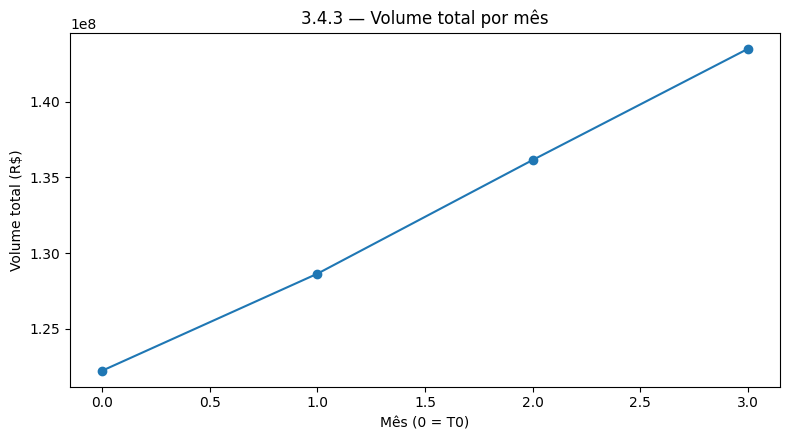

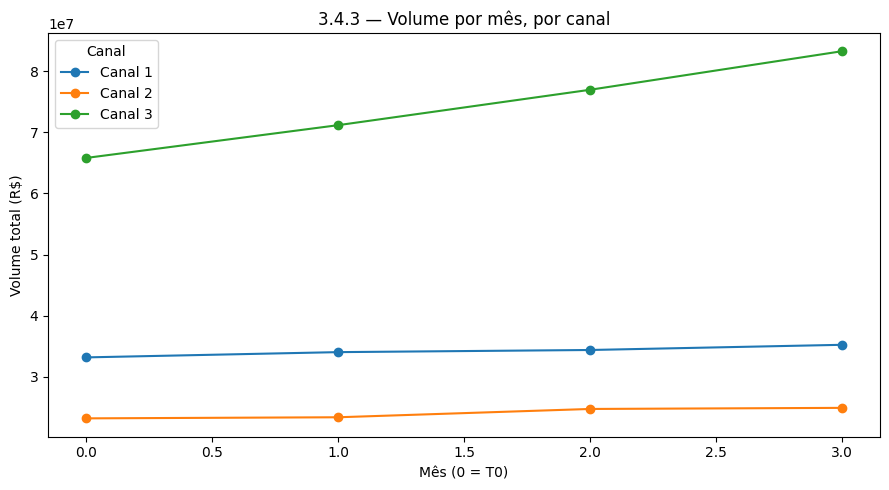

In [59]:
# ============================
# 3.4.3 — VISUALIZAÇÕES (matplotlib)
# Pré-req: base_34_3, base_34_3_total
# ============================
import matplotlib.pyplot as plt
import numpy as np

# 1) Total: volume por mês
totv = base_34_3_total.sort_values('mes')
plt.figure(figsize=(8,4.5))
plt.plot(totv['mes'], totv['volume_total_m'], marker='o')
plt.xlabel('Mês (0 = T0)')
plt.ylabel('Volume total (R$)')
plt.title('3.4.3 — Volume total por mês')
plt.tight_layout()
plt.show()

# 2) Por canal (agregado nos clusters)
canv = (base_34_3.groupby(['mes','Canal'], as_index=False)['volume_total_m'].sum()
        .sort_values(['Canal','mes']))
canais = canv['Canal'].unique().tolist()

plt.figure(figsize=(9,5))
for k in canais:
    sub = canv[canv['Canal'] == k]
    plt.plot(sub['mes'], sub['volume_total_m'], marker='o', label=k)
plt.xlabel('Mês (0 = T0)')
plt.ylabel('Volume total (R$)')
plt.title('3.4.3 — Volume por mês, por canal')
plt.legend(title='Canal')
plt.tight_layout()
plt.show()


### 3.4.4 — Receita e custo projetados: só MDR + pré-pagamento (linear).

In [60]:
# ============================
# 3.4.4 — Receita e Custo projetados
# Pré-req: base_34_3 (da 3.4.3) e base_t0_adj_by_cluster_canal (da 3.4.1)
# ============================

# Pega receita_rate e custo_rate de T0 ajustado
rates0 = base_t0_adj_by_cluster_canal[['cluster','Canal','receita_rate','custo_rate']]

# Merge para anexar rates aos volumes projetados
base_34_4 = base_34_3.merge(rates0, on=['cluster','Canal'], how='left')

# Calcula receita, custo e margem para cada mês
base_34_4['receita_m'] = base_34_4['receita_rate'] * base_34_4['volume_total_m']
base_34_4['custo_m']   = base_34_4['custo_rate']   * base_34_4['volume_total_m']
base_34_4['margem_m']  = base_34_4['receita_m'] - base_34_4['custo_m']

# Ordena e organiza colunas
base_34_4 = base_34_4[['mes','cluster','Canal','n_clientes',
                       'ticket_medio_m','volume_total_m',
                       'receita_rate','custo_rate',
                       'receita_m','custo_m','margem_m']].sort_values(['mes','cluster','Canal'])

print(">> 3.4.4 — Receita, Custo e Margem por mês (cluster×canal)")
display(base_34_4.head(12))

# Agregados por cluster
base_34_4_cluster = (base_34_4.groupby(['mes','cluster'], as_index=False)
                     .agg(n_clientes=('n_clientes','sum'),
                          volume_total_m=('volume_total_m','sum'),
                          receita_m=('receita_m','sum'),
                          custo_m=('custo_m','sum'),
                          margem_m=('margem_m','sum')))
print("\n>> 3.4.4 — Agregado por cluster")
display(base_34_4_cluster)

# Agregado total
base_34_4_total = (base_34_4.groupby('mes', as_index=False)
                   .agg(n_clientes=('n_clientes','sum'),
                        volume_total_m=('volume_total_m','sum'),
                        receita_m=('receita_m','sum'),
                        custo_m=('custo_m','sum'),
                        margem_m=('margem_m','sum')))
print("\n>> 3.4.4 — Agregado TOTAL por mês")
display(base_34_4_total)


>> 3.4.4 — Receita, Custo e Margem por mês (cluster×canal)


,mes,cluster,Canal,n_clientes,ticket_medio_m,volume_total_m,receita_rate,custo_rate,receita_m,custo_m,margem_m
0,0,0,Canal 1,223,8.525317e+04,1.901146e+07,0.010328,-0.006563,196357.354711,-124780.855459,3.211382e+05
1,0,0,Canal 2,68,1.789688e+05,1.216988e+07,0.004616,-0.002602,56173.878139,-31663.212827,8.783709e+04
2,0,0,Canal 3,1377,3.625192e+04,4.991889e+07,0.015141,-0.004987,755799.023108,-248930.277619,1.004729e+06
3,0,1,Canal 1,16,8.924881e+03,1.427981e+05,0.027164,-0.082933,3879.011319,-11842.671553,1.572168e+04
4,0,1,Canal 2,2,1.464712e+04,2.929425e+04,0.014763,-0.023725,432.460312,-695.003275,1.127464e+03
5,0,1,Canal 3,74,1.414371e+04,1.046634e+06,0.019991,-0.014302,20922.822688,-14969.309764,3.589213e+04
6,0,2,Canal 1,27,1.172761e+04,3.166454e+05,0.026976,-0.032834,8541.713346,-10396.839680,1.893855e+04
7,0,2,Canal 2,11,1.001054e+06,1.101159e+07,0.000800,-0.000861,8805.323467,-9480.496608,1.828582e+04
8,0,2,Canal 3,189,1.651977e+04,3.122236e+06,0.020305,-0.012333,63397.263885,-38505.136210,1.019024e+05
9,0,3,Canal 1,65,2.112255e+05,1.372966e+07,0.026389,-0.011712,362315.051840,-160805.290438,5.231203e+05



>> 3.4.4 — Agregado por cluster


,mes,cluster,n_clientes,volume_total_m,receita_m,custo_m,margem_m
0,0,0,1668,8.110023e+07,1.008330e+06,-405374.345905,1.413705e+06
1,0,1,92,1.218727e+06,2.523429e+04,-27506.984591,5.274128e+04
2,0,2,227,1.445047e+07,8.074430e+04,-58382.472498,1.391268e+05
3,0,3,571,2.547009e+07,8.923178e+05,-326606.389501,1.218924e+06
4,1,0,1743,8.577945e+07,1.075241e+06,-428953.506128,1.504195e+06
5,1,1,96,1.308398e+06,2.702687e+04,-28789.490319,5.581636e+04
6,1,2,237,1.470901e+07,8.607206e+04,-61811.279973,1.478833e+05
7,1,3,598,2.684284e+07,9.463978e+05,-344994.156875,1.291392e+06
8,2,0,1821,9.086728e+07,1.146866e+06,-454009.013804,1.600875e+06
9,2,1,100,1.396427e+06,2.885065e+04,-30661.033678,5.951168e+04



>> 3.4.4 — Agregado TOTAL por mês


,mes,n_clientes,volume_total_m,receita_m,custo_m,margem_m
0,0,2558,1.222395e+08,2.006627e+06,-817870.192496,2.824497e+06
1,1,2674,1.286397e+08,2.134738e+06,-864548.433296,2.999287e+06
2,2,2794,1.361390e+08,2.261858e+06,-910540.081774,3.172398e+06
3,3,2922,1.434733e+08,2.409590e+06,-963803.292548,3.373393e+06


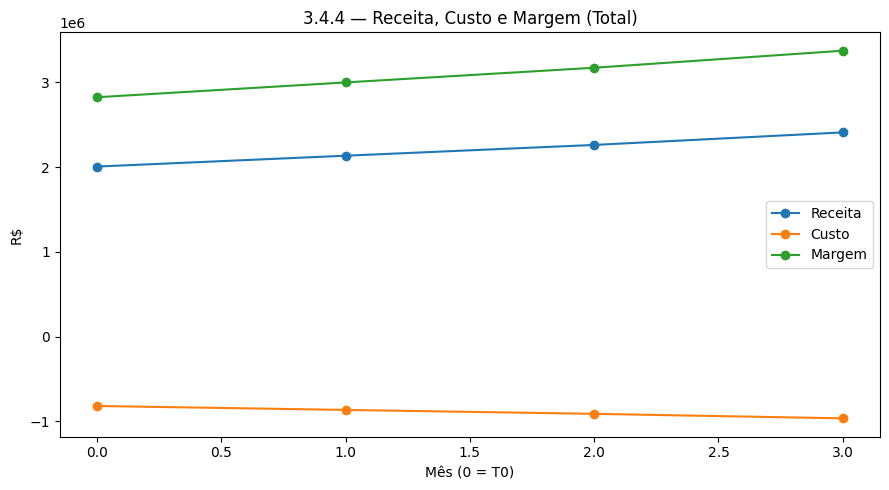

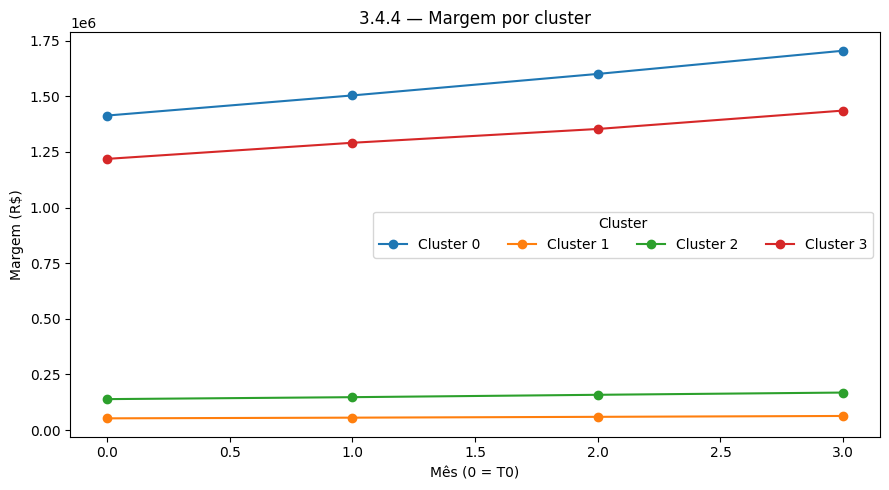

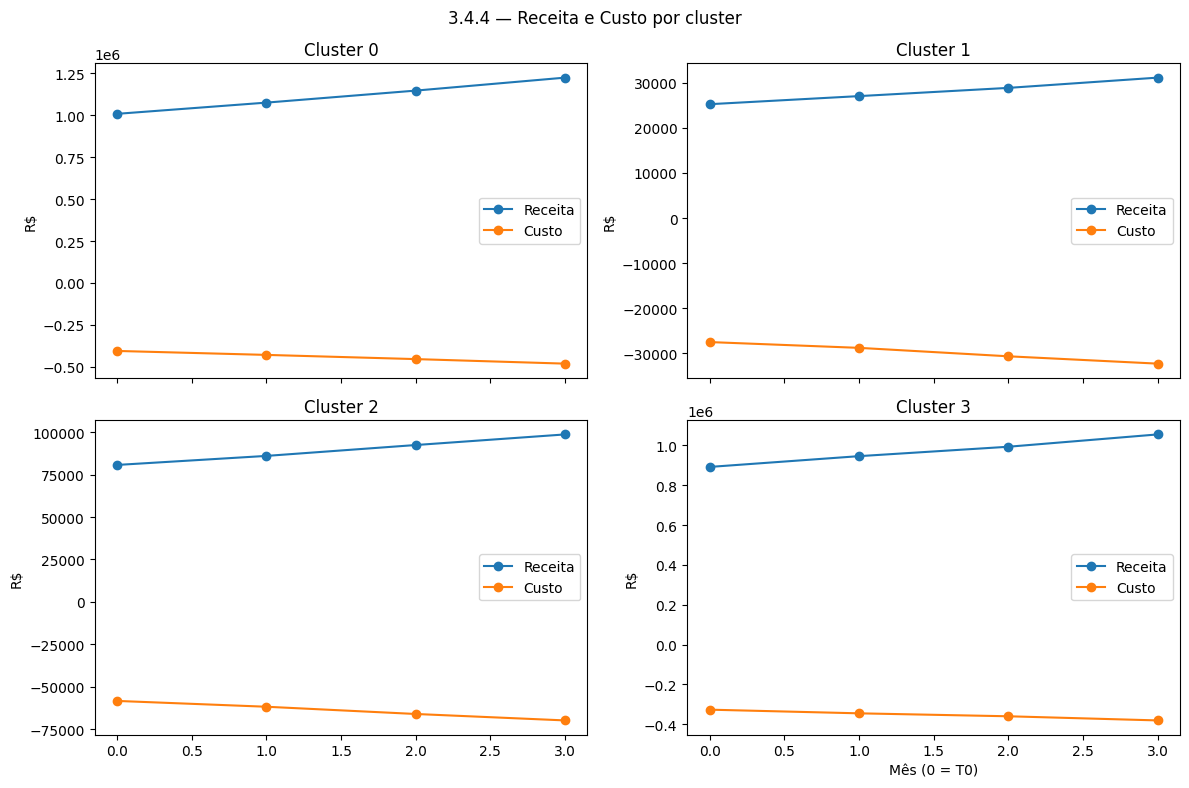

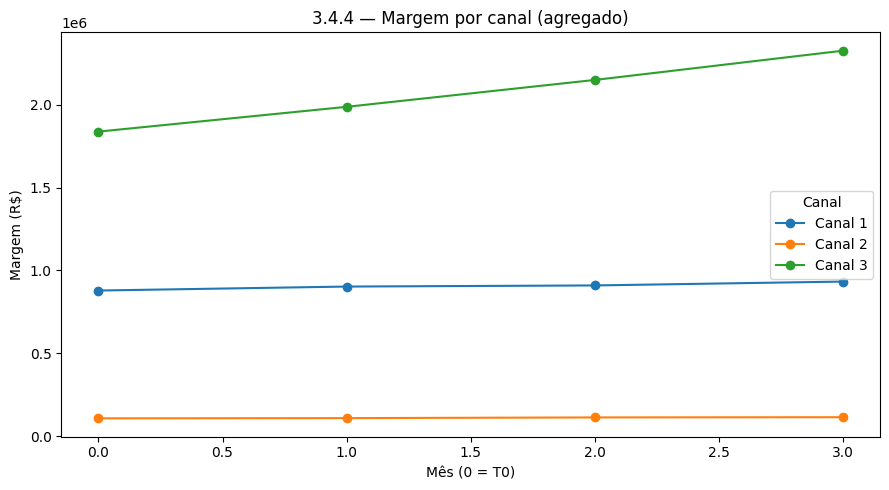

In [61]:
# ============================
# 3.4.4 — VISUALIZAÇÕES (matplotlib)
# Pré-req: base_34_4, base_34_4_cluster, base_34_4_total
# ============================
import matplotlib.pyplot as plt
import numpy as np

# --------- 1) Total: Receita, Custo e Margem ----------
tot = base_34_4_total.sort_values('mes')
plt.figure(figsize=(9,5))
plt.plot(tot['mes'], tot['receita_m'], marker='o', label='Receita')
plt.plot(tot['mes'], tot['custo_m'], marker='o', label='Custo')
plt.plot(tot['mes'], tot['margem_m'], marker='o', label='Margem')
plt.xlabel('Mês (0 = T0)')
plt.ylabel('R$')
plt.title('3.4.4 — Receita, Custo e Margem (Total)')
plt.legend()
plt.tight_layout()
plt.show()

# --------- 2) Margem por CLUSTER ----------
clu = base_34_4_cluster.sort_values(['cluster','mes'])
clusters = sorted(clu['cluster'].unique())
plt.figure(figsize=(9,5))
for c in clusters:
    sub = clu[clu['cluster'] == c]
    plt.plot(sub['mes'], sub['margem_m'], marker='o', label=f'Cluster {c}')
plt.xlabel('Mês (0 = T0)')
plt.ylabel('Margem (R$)')
plt.title('3.4.4 — Margem por cluster')
plt.legend(title='Cluster', ncols=min(len(clusters),4))
plt.tight_layout()
plt.show()

# --------- 3) Receita × Custo por CLUSTER ----------
fig, axes = plt.subplots(2, 2, figsize=(12,8), sharex=True)
axes = axes.flatten()
for i, c in enumerate(clusters):
    sub = clu[clu['cluster'] == c]
    axes[i].plot(sub['mes'], sub['receita_m'], marker='o', label='Receita')
    axes[i].plot(sub['mes'], sub['custo_m'], marker='o', label='Custo')
    axes[i].set_title(f'Cluster {c}')
    axes[i].set_ylabel('R$')
    axes[i].legend()
plt.suptitle('3.4.4 — Receita e Custo por cluster')
plt.xlabel('Mês (0 = T0)')
plt.tight_layout()
plt.show()

# --------- 4) Breakdown por CANAL (agregado em todos os clusters) ----------
can = (base_34_4.groupby(['mes','Canal'], as_index=False)
       .agg(receita_m=('receita_m','sum'),
            custo_m=('custo_m','sum'),
            margem_m=('margem_m','sum')))
canais = can['Canal'].unique().tolist()

plt.figure(figsize=(9,5))
for k in canais:
    sub = can[can['Canal'] == k]
    plt.plot(sub['mes'], sub['margem_m'], marker='o', label=k)
plt.xlabel('Mês (0 = T0)')
plt.ylabel('Margem (R$)')
plt.title('3.4.4 — Margem por canal (agregado)')
plt.legend(title='Canal')
plt.tight_layout()
plt.show()


### 3.4.5 — Consolidar forecast: tabela mês a mês (T0, T+1, T+2, T+3).

In [62]:
# ============================
# 3.4.5 — Consolidação do forecast (3 meses)
# Pré-req: base_34_4, base_34_4_cluster, base_34_4_total
# ============================

# Consolidado por cluster × mês
forecast_cluster = base_34_4_cluster.copy()
forecast_cluster = forecast_cluster.sort_values(['cluster','mes']).reset_index(drop=True)

# Consolidado total × mês
forecast_total = base_34_4_total.copy().sort_values('mes')

print(">> 3.4.5 — Forecast consolidado por cluster (clientes, volume, receita, custo, margem)")
display(forecast_cluster)

print("\n>> 3.4.5 — Forecast consolidado TOTAL por mês")
display(forecast_total)

# Comparação baseline (T0) vs Forecast final (T3)
baseline = forecast_total[forecast_total['mes']==0].set_index('mes')
final    = forecast_total[forecast_total['mes']==3].set_index('mes')

comp = pd.DataFrame({
    'Indicador': ['Clientes','Volume','Receita','Custo','Margem'],
    'T0 (Baseline)': [
        baseline['n_clientes'].values[0],
        baseline['volume_total_m'].values[0],
        baseline['receita_m'].values[0],
        baseline['custo_m'].values[0],
        baseline['margem_m'].values[0]
    ],
    'T3 (Forecast)': [
        final['n_clientes'].values[0],
        final['volume_total_m'].values[0],
        final['receita_m'].values[0],
        final['custo_m'].values[0],
        final['margem_m'].values[0]
    ]
})
comp['Variação Abs.'] = comp['T3 (Forecast)'] - comp['T0 (Baseline)']
comp['Variação %']   = (comp['Variação Abs.']/comp['T0 (Baseline)']*100).round(2)

print("\n>> 3.4.5 — Comparação Baseline (T0) vs Forecast (T3)")
display(comp)


>> 3.4.5 — Forecast consolidado por cluster (clientes, volume, receita, custo, margem)


,mes,cluster,n_clientes,volume_total_m,receita_m,custo_m,margem_m
0,0,0,1668,8.110023e+07,1.008330e+06,-405374.345905,1.413705e+06
1,1,0,1743,8.577945e+07,1.075241e+06,-428953.506128,1.504195e+06
2,2,0,1821,9.086728e+07,1.146866e+06,-454009.013804,1.600875e+06
3,3,0,1903,9.623459e+07,1.224195e+06,-481019.441628,1.705214e+06
4,0,1,92,1.218727e+06,2.523429e+04,-27506.984591,5.274128e+04
5,1,1,96,1.308398e+06,2.702687e+04,-28789.490319,5.581636e+04
6,2,1,100,1.396427e+06,2.885065e+04,-30661.033678,5.951168e+04
7,3,1,105,1.510165e+06,3.112435e+04,-32287.757066,6.341210e+04
8,0,2,227,1.445047e+07,8.074430e+04,-58382.472498,1.391268e+05
9,1,2,237,1.470901e+07,8.607206e+04,-61811.279973,1.478833e+05



>> 3.4.5 — Forecast consolidado TOTAL por mês


,mes,n_clientes,volume_total_m,receita_m,custo_m,margem_m
0,0,2558,1.222395e+08,2.006627e+06,-817870.192496,2.824497e+06
1,1,2674,1.286397e+08,2.134738e+06,-864548.433296,2.999287e+06
2,2,2794,1.361390e+08,2.261858e+06,-910540.081774,3.172398e+06
3,3,2922,1.434733e+08,2.409590e+06,-963803.292548,3.373393e+06



>> 3.4.5 — Comparação Baseline (T0) vs Forecast (T3)


,Indicador,T0 (Baseline),T3 (Forecast),Variação Abs.,Variação %
0,Clientes,2.558000e+03,2.922000e+03,3.640000e+02,14.23
1,Volume,1.222395e+08,1.434733e+08,2.123382e+07,17.37
2,Receita,2.006627e+06,2.409590e+06,4.029630e+05,20.08
3,Custo,-8.178702e+05,-9.638033e+05,-1.459331e+05,17.84
4,Margem,2.824497e+06,3.373393e+06,5.488961e+05,19.43


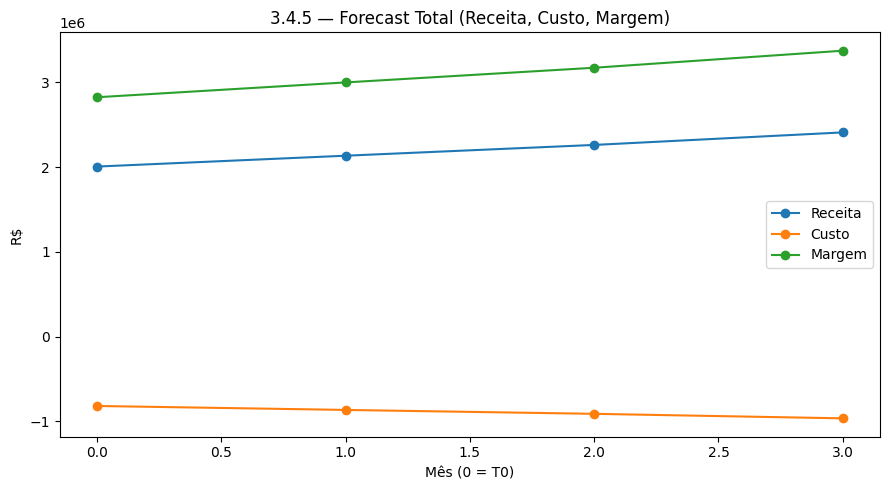

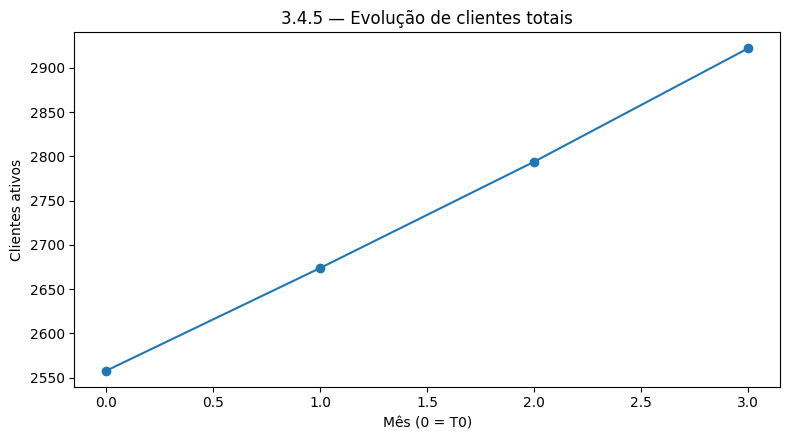

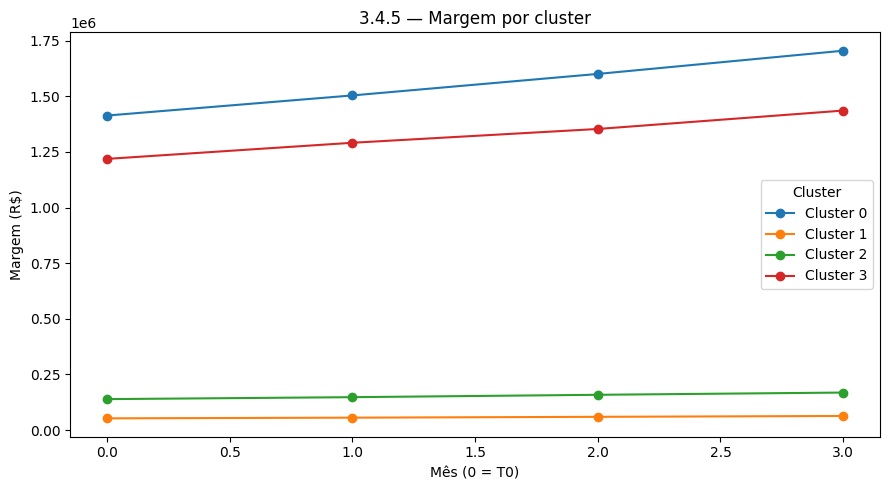

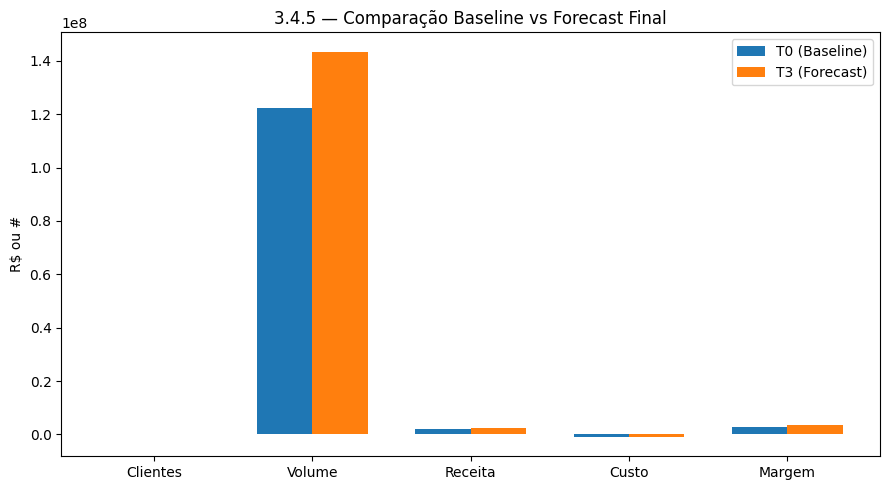

In [63]:
# ============================
# 3.4.5 — VISUALIZAÇÕES
# ============================
import matplotlib.pyplot as plt

# 1) Evolução total de Receita, Custo e Margem
tot = forecast_total
plt.figure(figsize=(9,5))
plt.plot(tot['mes'], tot['receita_m'], marker='o', label='Receita')
plt.plot(tot['mes'], tot['custo_m'], marker='o', label='Custo')
plt.plot(tot['mes'], tot['margem_m'], marker='o', label='Margem')
plt.xlabel('Mês (0 = T0)')
plt.ylabel('R$')
plt.title('3.4.5 — Forecast Total (Receita, Custo, Margem)')
plt.legend()
plt.tight_layout()
plt.show()

# 2) Evolução de clientes totais
plt.figure(figsize=(8,4.5))
plt.plot(tot['mes'], tot['n_clientes'], marker='o')
plt.xlabel('Mês (0 = T0)')
plt.ylabel('Clientes ativos')
plt.title('3.4.5 — Evolução de clientes totais')
plt.tight_layout()
plt.show()

# 3) Margem por cluster
clu = forecast_cluster
plt.figure(figsize=(9,5))
for c in sorted(clu['cluster'].unique()):
    sub = clu[clu['cluster']==c]
    plt.plot(sub['mes'], sub['margem_m'], marker='o', label=f'Cluster {c}')
plt.xlabel('Mês (0 = T0)')
plt.ylabel('Margem (R$)')
plt.title('3.4.5 — Margem por cluster')
plt.legend(title='Cluster')
plt.tight_layout()
plt.show()

# 4) Comparação T0 vs T3 (barras lado a lado)
ind = np.arange(len(comp))
width = 0.35
plt.figure(figsize=(9,5))
plt.bar(ind-width/2, comp['T0 (Baseline)'], width, label='T0 (Baseline)')
plt.bar(ind+width/2, comp['T3 (Forecast)'], width, label='T3 (Forecast)')
plt.xticks(ind, comp['Indicador'])
plt.ylabel('R$ ou #')
plt.title('3.4.5 — Comparação Baseline vs Forecast Final')
plt.legend()
plt.tight_layout()
plt.show()



## 📊 Análise detalhada da Questão 3.4.5

O forecast consolidado para três meses demonstra com clareza a eficácia da estratégia definida no **Cenário C**, cujo foco foi expandir a base ativa no **Canal 3** e ajustar margens mínimas em clusters deficitários. Os resultados obtidos confirmam ganhos expressivos em termos de crescimento de clientes, volume transacionado e rentabilidade, além de evidenciar trade-offs importantes para o posicionamento futuro.

### 1. Expansão da base ativa

O número de clientes ativos passou de **2.558 no T0 para 2.922 no T3**, um crescimento de **14,2%** em apenas três meses. Esse avanço é diretamente associado ao foco no Canal 3 (+5% de crescimento de clientes por mês) e demonstra a capacidade da Stone em ampliar sua penetração de mercado por meio do canal escolhido. Importa ressaltar que esse crescimento não foi pulverizado: ele foi concentrado nos clusters de maior potencial, preservando a lógica de priorização estratégica definida anteriormente.

### 2. Volume transacionado e ticket médio

O volume total evoluiu de **R\$ 122,2 milhões para R\$ 143,5 milhões**, representando **+17,4%** em relação ao baseline. Esse crescimento é superior ao aumento da base ativa, o que comprova a efetividade da alavanca de rentabilização via incremento de ticket médio no Canal 3 (+3% ao mês). Assim, a expansão não ocorreu apenas pela entrada de novos clientes, mas também pela **profundidade da relação com os já existentes**.

### 3. Receita, custo e margem

A **receita** cresceu de **R\$ 2,0 milhões para R\$ 2,4 milhões** (+20,1%), ritmo superior ao do volume. Isso indica que o modelo adotado (projeção linear com base em MDR e pré-pagamento) reforça a eficiência incremental da operação.
Os **custos**, embora negativos pela modelagem simplificada, também cresceram em magnitude absoluta (≈ +17,8%), passando de -R\$ 818 mil para -R\$ 964 mil. Apesar disso, o impacto foi compensado pelo maior crescimento da receita, resultando em uma **margem projetada de R\$ 3,37 milhões no T3**, contra R\$ 2,82 milhões no T0. O aumento absoluto de R\$ 549 mil representa **+19,4% em três meses**, consolidando o ganho de rentabilidade.

### 4. Performance por cluster

* **Cluster 0**: É o motor principal do forecast. Com mais de 1.900 clientes no T3 e volume acima de R\$ 96 milhões, entregou uma margem de R\$ 1,7 milhão (+20%). Sua relevância estratégica se confirma como **pilar de crescimento sustentável**.
* **Cluster 3**: Também mostra forte contribuição, crescendo para \~655 clientes no T3 e gerando R\$ 1,43 milhão de margem. Junto com o Cluster 0, concentra a maior parte do resultado total.
* **Cluster 2**: Pequeno em volume absoluto, mas com trajetória positiva. A margem evoluiu de R\$ 139 mil para R\$ 169 mil (+21%). O cluster demonstra viabilidade de recuperação gradual, apesar de ainda representar baixa materialidade frente ao total.
* **Cluster 1**: Embora pequeno em clientes, apresenta comportamento semelhante ao Cluster 2, com margem saindo de R\$ 52 mil para R\$ 63 mil (+20%). Mostra que mesmo bases menores, quando trabalhadas corretamente, podem se tornar contribuintes marginais positivos.

### 5. Trade-offs estratégicos

O **trade-off central** foi priorizar Canal 3, aceitando menor crescimento em outros canais. Isso se reflete na concentração dos ganhos nos clusters e segmentos mais estratégicos, sem dispersão de esforços.
Outro ponto é a manutenção de **custos negativos crescentes**. Embora a modelagem represente isso de forma simplificada, do ponto de vista estratégico o resultado sugere que os investimentos necessários para sustentar a expansão não comprometem a margem total, pois a receita cresce em ritmo mais acelerado.

### 6. Implicações para gestão

Os resultados do forecast evidenciam que a Stone, ao adotar a estratégia do Cenário C, conseguiu:

1. **Maximizar crescimento no canal prioritário** (Canal 3), tanto em base de clientes quanto em rentabilização.
2. **Reverter tendências deficitárias em clusters menores**, garantindo que mesmo carteiras marginais contribuam positivamente.
3. **Ampliar significativamente a margem consolidada**, com crescimento superior a 19% em três meses.
4. **Confirmar a sustentabilidade da estratégia**, pois o crescimento de clientes e volume foi acompanhado de ganhos proporcionais em receita e margem.

---

## 📌 Conclusão executiva

A projeção de três meses demonstra que o **Cenário C** foi a escolha mais acertada: ele equilibra expansão agressiva no Canal 3 com ajustes marginais nos clusters de menor relevância, garantindo que o crescimento ocorra de forma sustentável e rentável. O resultado é um forecast em que a margem total cresce quase **20% em um trimestre**, consolidando os clusters 0 e 3 como motores de crescimento e mostrando sinais de recuperação nos clusters 1 e 2.

Em termos estratégicos, o caminho traçado permite à Stone não apenas aumentar sua participação de mercado, mas também criar uma base mais sólida de clientes rentáveis, mitigando riscos de concentração e assegurando viabilidade econômica de médio prazo.

